# Methanol synthesis loop: 4-D feasibility, nominal and under feed uncertainty

Design variables: reactor temperature and pressure, H$_2$:CO$_2$ ratio of the fresh feed, purge fraction.
Constraints: methanol product, compression duty, CO formation in the reactor, hydrogen utilisation.
Uncertain parameter: the N$_2$ mole fraction of the CO$_2$ feed, uniform over `N2_RANGE`, represented by `N_SCEN`
equally weighted scenarios; a design is probabilistically-feasible if at most one scenario violates a constraint
(value-at-risk, `ALPHA = 1 / N_SCEN`).

One run from a fresh kernel, in order:

- **A** reactor-inlet hull of the HYSYS loop over design box and scenarios, inflated into the surrogate's training box
- **B** Sobol sample of the isolated PFR; surrogates `stoi` (reaction extents, atom balances exact by construction) and `raw` (outlet flows)
- **C** surrogate loop against HYSYS, point by point
- **D** nominal feasibility analysis: nested sampling on the surrogate loop and on HYSYS, surrogate candidates verified on HYSYS
- **E** the same under the N$_2$ scenarios, then the comparison of both

HYSYS plumbing: `hysys.py`, `hysys_loop.py`, `hysys_pfr.py`, `hysys_surrogate.py`; sampling, nets and figures: `helpers.py`.

In [1]:
import pickle, time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd

from hysys import open_case
from helpers import NestedSampler, Corner, Trellis, generate_sobol_points, train_surrogate, parity_plot, set_metrics
import hysys_loop as loop            # full loop, PFR solved by HYSYS       (methanol_loop.hsc)
import hysys_pfr as pfr              # isolated reactor                     (methanol_pfr.hsc)
import hysys_surrogate as sur        # loop with the PFR replaced by a net  (methanol_surrogate.hsc)
from plotstyle import setup, save; setup()

In [2]:
# KNOBS
SMOKE_TEST = False                                  # few points to check the machinery; False for the real run
TAG = "_smoke" if SMOKE_TEST else ""                # suffix of every file this notebook writes
CASES = Path("C:/Users/kr326/Documents/cyclic-feasibility/hysys-meoh/AspenFiles")
FIG = "Cases/HYSYS_MeOH_4D"

DESIGN = {"temperature_C": (220, 280), "pressure_bar": (70, 120), "ratio": (2.5, 4.0), "purge_rate": (0.015, 0.08)}
LABELS = [r"T [$^\circ$C]", "P [bar]", "H$_2$:CO$_2$ [-]", "purge [-]"]
VOLUME, SEGMENTS = 35, 10 if SMOKE_TEST else 50     # reactor m3 (the nets are trained at one volume), PFR segments
NET = "stoi"                                        # surrogate used in the feasibility analyses: "stoi" or "raw"
INFLATE, RELAX = 0.05, 0.02                         # training-box widening; constraint relaxation on the surrogate side
MEOH_MIN, COMPRESSION_MAX, CO_MAX, H2_UTIL_MIN, RECYCLE_MAX = 18_000, 4_000, 6, 0.85, 4.0     # kg/h, kW, kgmole/h, -
N2_NOMINAL = 0.01                                   # N2 mole fraction of the CO2 feed

N2_RANGE, N_SCEN = (0.005, 0.03), 4 if SMOKE_TEST else 8
edges = np.linspace(*N2_RANGE, N_SCEN + 1)
SCENARIOS = ((edges[:-1] + edges[1:]) / 2).reshape(-1, 1)   # midpoints of equal bins: equally weighted scenarios
ALPHA = 1 / N_SCEN                                           # VaR: at most one scenario may violate

N_HULL, N_PFR = (64, 1024) if SMOKE_TEST else (256, 8192)   # A: loop solves (scenarios cycled); B: PFR solves (cheap)
N_LIVE, N_PROP = (32, 8) if SMOKE_TEST else (256, 16)       # D, E: nested sampler; the surrogate run uses 2 * N_LIVE
MAX_TIME = 7200 if SMOKE_TEST else 0                        # s per sampler run, 0 = none

LOG = Path(f"progress{TAG}.log")
def log(msg):
    """Progress line to stdout and to LOG"""
    line = f"{datetime.now():%H:%M:%S}  {msg}"
    print(line)
    LOG.open("a").write(line + "\n")

In [3]:
# The three cases (HYSYS is launched for any that is not open)
case_loop, case_pfr, case_sur = (open_case(str(CASES / f)) for f in ("methanol_loop.hsc", "methanol_pfr.hsc", "methanol_surrogate.hsc"))
objects_loop = loop.cache_objects(case_loop, segments=SEGMENTS)
objects_pfr = pfr.cache_objects(case_pfr, segments=SEGMENTS)        # objects_sur needs the training box of Part A
assert np.isclose(objects_loop["co2_nominal"]["n2_fraction"], N2_NOMINAL), "loop case not at its nominal feed: reopen it"

Case not open in HYSYS - launching (this can take a minute)...
Case not open in HYSYS - launching (this can take a minute)...
Case not open in HYSYS - launching (this can take a minute)...


In [4]:
# One flowsheet evaluation at design x = (T, P, ratio, purge) under scenario p (N2 fraction; None = nominal),
# warm-started from the nearest converged point of the same flowsheet (distance in box-normalised coordinates)
WARM = {"hysys": [], "surrogate": []}                       # (key, tear_state) of every converged point
SPAN = np.array([hi - lo for lo, hi in DESIGN.values()] + [N2_RANGE[1] - N2_RANGE[0]])

def run(model, x, p=None, net=None):
    T, P, ratio, purge = x
    key = np.array([*x, N2_NOMINAL if p is None else p[0]])
    seen = WARM[model]
    warm = seen[np.argmin((((np.array([k for k, _ in seen]) - key) / SPAN) ** 2).sum(1))][1] if seen else None
    kw = dict(pressure=(P, "bar"), temperature=(T, "C"), ratio=ratio, purge_rate=purge,
              n2_fraction=None if p is None else float(p[0]), warm=warm)
    row = (loop.run_point(objects_loop, volume=(VOLUME, "m3"), **kw) if model == "hysys"
           else sur.run_point(objects_sur, net, **kw))
    if row["converged"]:
        seen.append((key, row["tear_state"]))
    return row

def residuals(r, relax=0.0):
    """Constraint residuals of a result row (or of a DataFrame of rows); feasible iff all <= 0."""
    return [MEOH_MIN * (1 - relax) - r["methanol_kg_h"], r["compression_kW"] - COMPRESSION_MAX * (1 + relax),
            r["co_formation_kgmole_h"] - CO_MAX * (1 + relax), H2_UTIL_MIN * (1 - relax) - r["h2_utilisation"],
            r["recycle_ratio"] - RECYCLE_MAX]

def sweep(model, points, scenarios=(None,), **kw):
    """One row per design point, point i under scenario i % len(scenarios); a point that raises is kept as not converged."""
    rows = []
    for i, x in enumerate(points):
        try:
            rows.append({**dict(zip(DESIGN, x)), **run(model, x, scenarios[i % len(scenarios)], **kw)})
        except Exception as e:
            rows.append({**dict(zip(DESIGN, x)), "converged": False, "error": str(e)})
        if (i + 1) % max(len(points) // 5, 1) == 0:
            log(f"{model} sweep: {i + 1}/{len(points)}")
    return pd.DataFrame(rows)

## A  Reactor-inlet hull of the loop, the surrogate's training box

In [5]:
t0 = time.time()
df_hull = sweep("hysys", generate_sobol_points(N_HULL, np.array(list(DESIGN.values())).T), list(SCENARIOS))
t_hull = time.time() - t0
ok = df_hull[df_hull.converged]
inlet = ok[[f"in_{c}_kgmole_h" for c in sur.COMPONENTS]].set_axis(sur.COMPONENTS, axis=1) / 3600    # kgmole/s, the net's unit
lo, hi = inlet.min(), inlet.max()
pfr_box = {k: DESIGN[k] for k in ("temperature_C", "pressure_bar")} | \
          {c: (max(lo[c] - INFLATE * (hi[c] - lo[c]), 0), hi[c] + INFLATE * (hi[c] - lo[c])) for c in sur.COMPONENTS}
print(f"{len(ok)}/{len(df_hull)} converged, {t_hull / 60:.1f} min")
pd.DataFrame(pfr_box, index=["lower", "upper"]).T

15:57:14  hysys sweep: 51/256
16:02:16  hysys sweep: 102/256
16:06:32  hysys sweep: 153/256
16:10:23  hysys sweep: 204/256
16:14:17  hysys sweep: 255/256
256/256 converged, 22.8 min


,lower,upper
temperature_C,220.000000,280.000000
pressure_bar,70.000000,120.000000
Hydrogen,0.815790,12.593247
CO,0.008374,0.365603
CO2,0.169509,1.413665
H2O,0.006838,0.013807
Methanol,0.001989,0.021950
Nitrogen,0.001743,0.295747


## B  Sobol sample of the isolated PFR, surrogates `stoi` and `raw`

In [ ]:
t0 = time.time()
X = generate_sobol_points(N_PFR, np.array(list(pfr_box.values())).T)
df_pfr = pd.DataFrame(pfr.run_point(objects_pfr, temperature=(T, "C"), pressure=(P, "bar"), volume=(VOLUME, "m3"),
                                    flows=(dict(zip(sur.COMPONENTS, f)), "kgmole/s")) for T, P, *f in X)
t_pfr = time.time() - t0
ok, X = df_pfr[df_pfr.converged], X[df_pfr.converged.to_numpy()]
inlet, outlet = (ok[[f"{s}_{c}_kgmole_h" for c in sur.COMPONENTS]].to_numpy() for s in ("in", "out"))
print(f"{len(ok)}/{len(df_pfr)} converged, {t_pfr:.0f} s")

# stoi: extents of CO2 + 3 H2 -> CH3OH + H2O and CO2 + H2 -> CO + H2O (outlet = inlet + sur.STOICH @ extents), duty, dP
# raw:  the six outlet flows, duty, dP
targets = {"stoi": (np.column_stack([(outlet - inlet)[:, [4, 1]], ok.reactor_duty_kW, ok.reactor_dP_bar]),
                    ["xi_meoh_kgmole_h", "xi_co_kgmole_h", "reactor_duty_kW", "reactor_dP_bar"]),
           "raw": (np.column_stack([outlet, ok.reactor_duty_kW, ok.reactor_dP_bar]),
                   [f"out_{c}_kgmole_h" for c in sur.COMPONENTS] + ["reactor_duty_kW", "reactor_dP_bar"])}
nets, oof, t_train = {}, {}, {}
for name, (Y, names) in targets.items():
    t0 = time.time()
    net, _, oof[name] = train_surrogate(X, Y, names=names, path=f"pfr_surrogate_{name}{TAG}_4d.txt")
    nets[name], t_train[name] = (sur.stoi_as_raw(net) if name == "stoi" else net), time.time() - t0

8192/8192 converged, 1161 s
width 64 (291 s)   CV rmse/std per width: 4: 0.1916, 8: 0.0586, 16: 0.0270, 32: 0.0155, 64: 0.0123, 128: 0.0125
  xi_meoh_kgmole_h           5.219    0.23 % of range
  xi_co_kgmole_h             4.993    0.27 % of range
  reactor_duty_kW          116.838    0.26 % of range
  reactor_dP_bar             0.006    0.11 % of range
width 128 (389 s)   CV rmse/std per width: 4: 0.3414, 8: 0.1150, 16: 0.0534, 32: 0.0216, 64: 0.0141, 128: 0.0119, 256: 0.0132
  out_Hydrogen_kgmole_h     80.172    0.19 % of range
  out_CO_kgmole_h            5.193    0.39 % of range
  out_CO2_kgmole_h           9.067    0.19 % of range
  out_H2O_kgmole_h           5.292    0.22 % of range
  out_Methanol_kgmole_h      5.898    0.26 % of range
  out_Nitrogen_kgmole_h      1.933    0.18 % of range
  reactor_duty_kW          145.917    0.32 % of range
  reactor_dP_bar             0.007    0.14 % of range


             range   stoi    raw
Hydrogen  42230.68  15.42  80.17
CO         1326.47   4.99   5.19
CO2        4752.54   6.43   9.07
H2O        2403.04   6.43   5.29
Methanol   2256.71   5.22   5.90
Nitrogen   1058.32   0.00   1.93 

raw net atom-balance error, rms kgmole/h: [8.06, 15.8, 156.74]


WindowsPath('C:/Users/kr326/Documents/MScThesis/figures/Cases/HYSYS_MeOH_4D/parity_pfr_outlets.png')

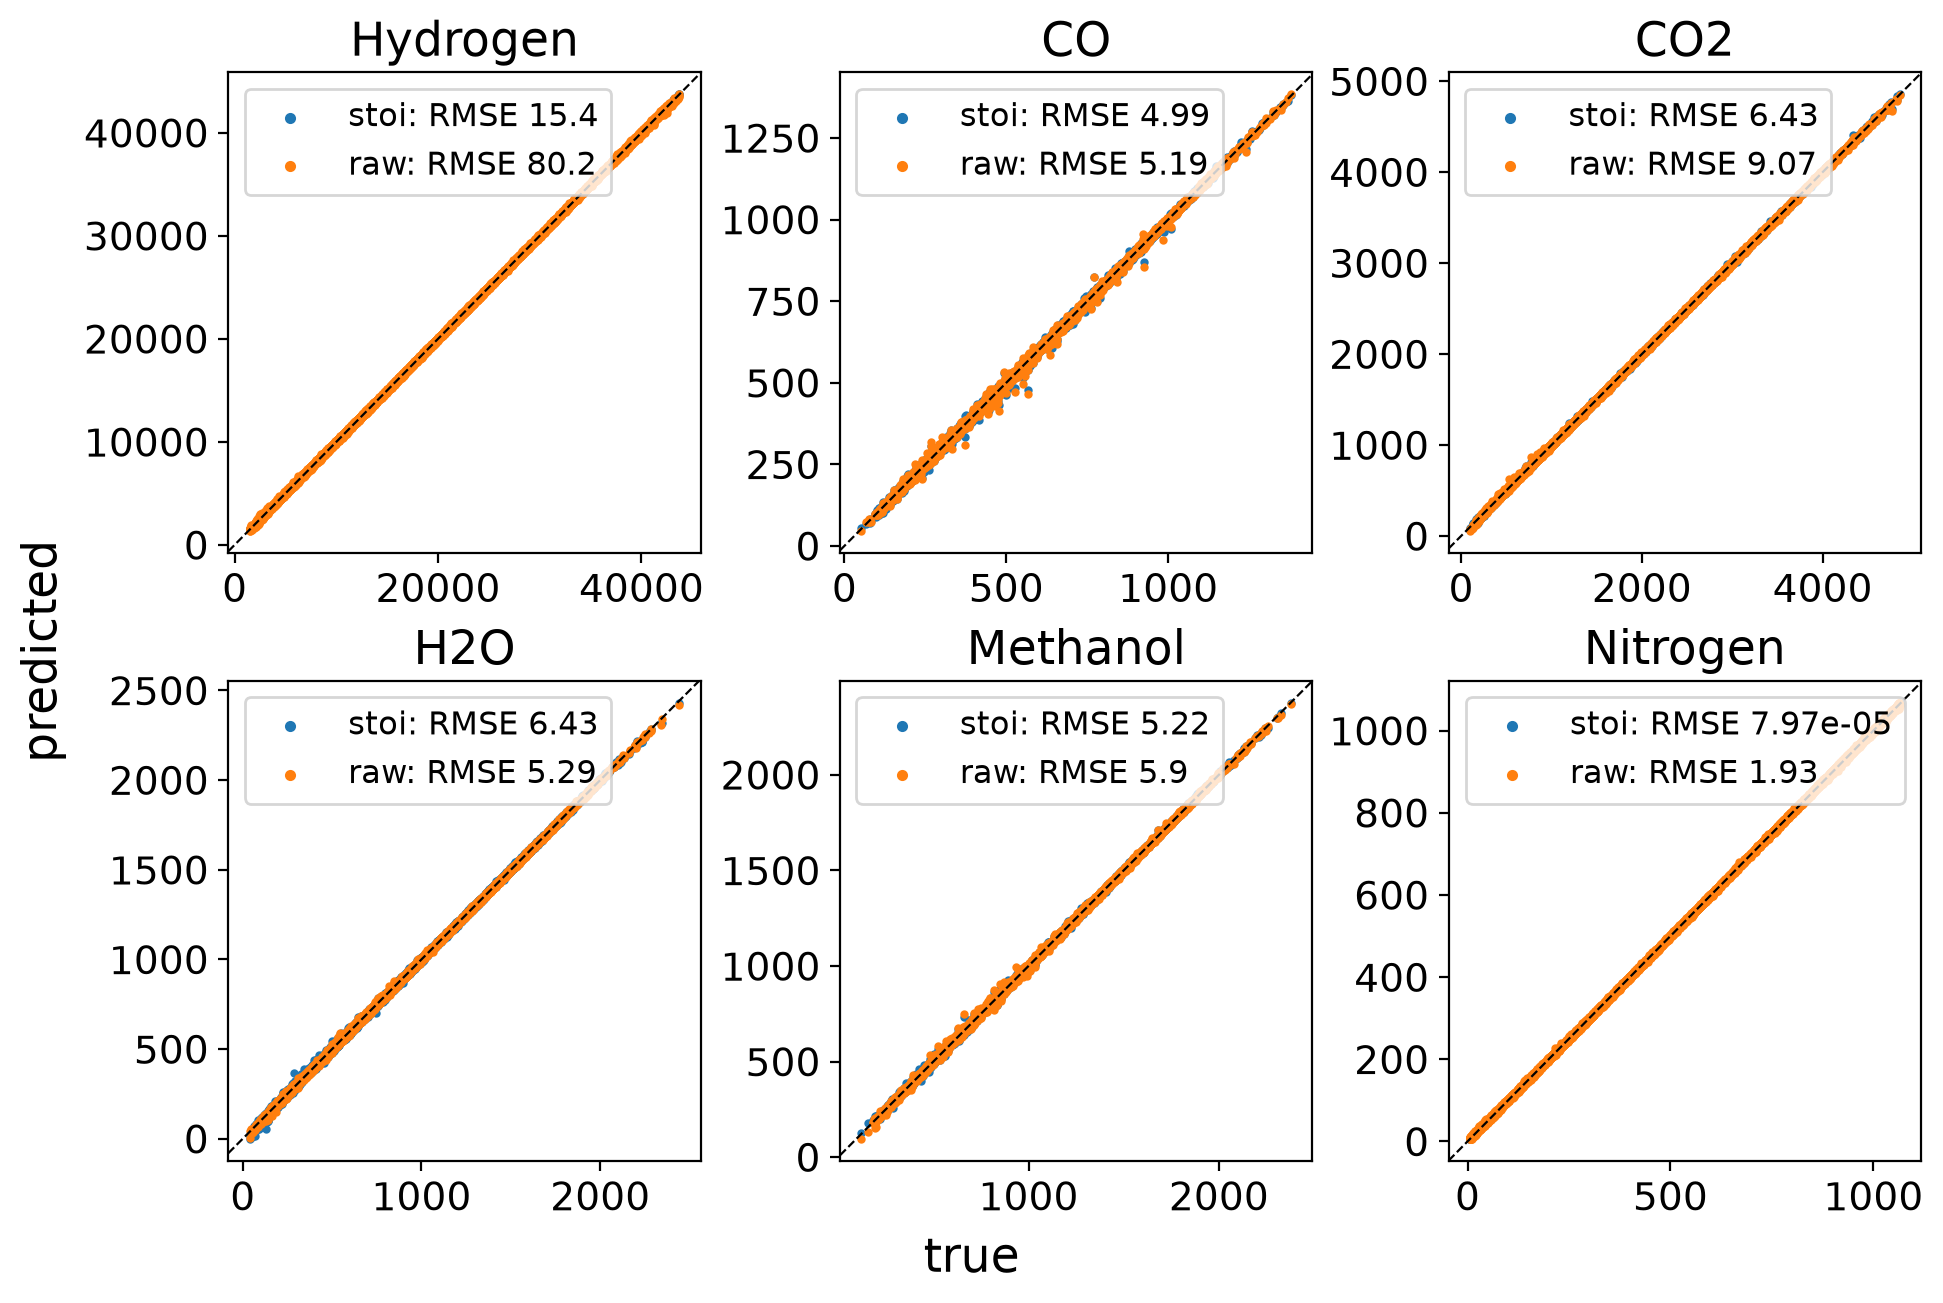

In [7]:
# Out-of-fold outlet flows, and the raw net's atom-balance error (stoi: zero by construction)
out_stoi = inlet + oof["stoi"][:, :2] @ sur.STOICH.T
rmse = lambda a, b: np.sqrt(((a - b) ** 2).mean(0))
print(pd.DataFrame({"range": np.ptp(outlet, 0), "stoi": rmse(out_stoi, outlet), "raw": rmse(oof["raw"][:, :6], outlet)},
                   index=sur.COMPONENTS).round(2), "\n")
ATOMS = pd.DataFrame({"C": [0, 1, 1, 0, 1, 0], "O": [0, 1, 2, 1, 1, 0], "H": [2, 0, 0, 2, 4, 0]}, index=sur.COMPONENTS)
print("raw net atom-balance error, rms kgmole/h:", (pd.DataFrame(oof["raw"][:, :6] - inlet) @ ATOMS.to_numpy()).pow(2).mean().pow(0.5).round(2).tolist())
fig, _ = parity_plot(outlet, {"stoi": out_stoi, "raw": oof["raw"][:, :6]}, names=sur.COMPONENTS)
save(fig, f"{FIG}/parity_pfr_outlets{TAG}")

## C  Surrogate loop against HYSYS, point by point on the hull sample

In [8]:
objects_sur = sur.cache_objects(case_sur, pfr_box)
assert np.isclose(objects_sur["co2_nominal"]["n2_fraction"], N2_NOMINAL), "cut case not at its nominal feed: reopen it"
hull_ok = df_hull[df_hull.converged].reset_index(drop=True)
KEYS = ["methanol_kg_h", "compression_kW", "co_formation_kgmole_h", "recycle_ratio"]
for name, net in nets.items():
    pred = sweep("surrogate", hull_ok[list(DESIGN)].to_numpy(), hull_ok[["n2_fraction"]].to_numpy(), net=net)
    err = (pred[KEYS] - hull_ok[KEYS])[pred.converged]
    print(f"=== {name}: {int(pred.converged.sum())}/{len(pred)} converged, {pred.tear_passes.mean():.0f} tear passes, "
          f"{int(pred.outside_box.map(len).gt(0).sum())} points outside the box")
    print(pd.DataFrame({"rmse": err.pow(2).mean().pow(0.5), "max |err|": err.abs().max(),
                        "% of mean": 100 * err.pow(2).mean().pow(0.5) / hull_ok[KEYS].abs().mean()}).round(3))

16:46:37  surrogate sweep: 51/256
16:47:56  surrogate sweep: 102/256
16:49:10  surrogate sweep: 153/256
16:50:24  surrogate sweep: 204/256
16:51:31  surrogate sweep: 255/256
=== stoi: 256/256 converged, 20 tear passes, 1 points outside the box
                         rmse  max |err|  % of mean
methanol_kg_h          46.001    131.724      0.274
compression_kW          8.136     88.265      0.205
co_formation_kgmole_h   0.325      1.447      2.295
recycle_ratio           0.106      0.667      2.378
16:52:41  surrogate sweep: 51/256
16:53:49  surrogate sweep: 102/256
16:54:53  surrogate sweep: 153/256
16:55:59  surrogate sweep: 204/256
16:57:03  surrogate sweep: 255/256
=== raw: 256/256 converged, 17 tear passes, 2 points outside the box
                          rmse  max |err|  % of mean
methanol_kg_h          366.991   1051.414      2.185
compression_kW          31.913    404.929      0.805
co_formation_kgmole_h    0.580      2.909      4.100
recycle_ratio            0.438      2.483

## D  Nominal feasibility analysis

In [9]:
def feasibility(scenarios, name):
    """Nested sampling of the feasible region on the surrogate loop (2 N_LIVE live points, relaxed constraints) and
    on HYSYS (N_LIVE), then the surrogate's live set re-evaluated on HYSYS under every scenario, shuffled (live
    points are sorted by margin), until N_LIVE are confirmed.  Feasible iff at most ALPHA of the scenarios violates."""
    scen, alpha = ([None], 0.0) if scenarios is None else (list(scenarios), ALPHA)
    out = {"scenarios": scenarios}
    for model, n_live, relax, net in (("surrogate", 2 * N_LIVE, RELAX, nets[NET]), ("hysys", N_LIVE, 0.0, None)):
        rows, t0 = [], time.time()
        def g(x, p=None):
            r = run(model, x, p, net)
            rows.append({**dict(zip(DESIGN, x)), **r})
            if len(rows) % 100 == 0:
                log(f"{name} {model}: {len(rows)} evaluations, {(time.time() - t0) / 60:.0f} min")
            if not r["converged"]:
                raise RuntimeError("not converged")                     # the sampler drops the point, counts a failure
            return residuals(r, relax)
        res = NestedSampler(g, *zip(*DESIGN.values()), scenarios=scenarios, criterion="var", threshold=alpha,
                            num_live=n_live, num_prop=N_PROP, max_time=MAX_TIME).sample()
        out[model] = dict(result=res, df=pd.DataFrame(rows), wall_s=time.time() - t0)
        log(f"{name} {model}: {res.status.name}, {len(rows)} evaluations, {(time.time() - t0) / 60:.0f} min")
    live = out["surrogate"]["result"].live
    cand = pd.DataFrame(live.x[live.feasible], columns=list(DESIGN)).sample(frac=1, random_state=42)
    allowed = alpha * len(scen)                                  # failing scenarios a feasible design may have
    t0, failed, n_ver = time.time(), [], 0
    for x in cand.to_numpy():
        if sum(f <= allowed for f in failed) >= N_LIVE:
            break
        n = 0
        for k, p in enumerate(scen[::-1]):                       # high N2 first: a rejection shows early (speed only)
            r = run("hysys", x, p)
            n += not r["converged"] or max(residuals(r)) > 0
            n_ver += 1
            if n > allowed or n + len(scen) - k - 1 <= allowed:   # verdict fixed: rejected, or cannot be rejected
                break
        failed.append(n)
    cand = cand.iloc[:len(failed)].assign(failed=failed, verified=lambda c: c.failed <= allowed)
    out |= dict(cand=cand, t_ver=time.time() - t0, n_ver=n_ver)
    log(f"{name} verification: {int(cand.verified.sum())}/{len(cand)} confirmed under {len(scen)} scenario(s)")
    return out

def backup():
    pickle.dump(dict(df_hull=df_hull, pfr_box=pfr_box, df_pfr=df_pfr, runs=runs, t_hull=t_hull, t_pfr=t_pfr, t_train=t_train),
                open(f"backup_4d{TAG}.pkl", "wb"))

In [10]:
T, P, R, U = range(4) # U: Purge
BOX = list(zip(*DESIGN.values()))
TITLES = {"simultaneous": "live vs dead points", "reconstructed": "reconstructed vs simultaneous"}

def figures(out, name, title):
    """Corner and trellis, as in the cascades: HYSYS live vs dead points, and verified candidates vs the HYSYS live set."""
    res, cand = out["hysys"]["result"], out["cand"]
    sets = {"simultaneous": [(res.dead.x, f"dead ({len(res.dead.x)})", dict(color="crimson", alpha=0.5)),
                             (res.live.x, f"live ({len(res.live.x)})", dict(color="royalblue"))],
            "reconstructed": [(res.live.x[res.live.feasible], f"simultaneous ({int(res.live.feasible.sum())})", dict(color="0.75")),
                              (cand.loc[cand.verified, list(DESIGN)].to_numpy(), f"reconstructed ({int(cand.verified.sum())})", dict(color="royalblue")),
                              (cand.loc[~cand.verified, list(DESIGN)].to_numpy(), f"rejected by HYSYS ({int((~cand.verified).sum())})", dict(color="crimson", marker="x"))]}
    purge_edges = np.linspace(DESIGN["purge_rate"][0], max(res.live.x[:, U].max(), cand.purge_rate.max()) + 1e-3, 4).round(3)
    for kind, pts in sets.items():
        grid = Corner(LABELS, BOX)
        for X, label, kw in pts:
            grid.scatter(X, s=2, label=label, **kw)
        grid.fig.legend(markerscale=4)
        grid.fig.suptitle(f"{title}: {TITLES[kind]}", x=0.01, ha="left")
        save(grid.fig, f"{FIG}/corner_{kind}_{name}{TAG}")
        grid = Trellis(np.linspace(*DESIGN["ratio"], 4), purge_edges, xlabel=LABELS[T], ylabel=LABELS[P],
                       col_label=LABELS[R], row_label=LABELS[U], subplot_kw={"xlim": DESIGN["temperature_C"], "ylim": DESIGN["pressure_bar"]})
        for X, label, kw in pts:
            grid.scatter(X[:, T], X[:, P], X[:, R], X[:, U], s=8, label=label, **kw)
        grid.fig.legend(loc="outside upper right")
        grid.fig.suptitle(f"{title}: {TITLES[kind]}", x=0.01, ha="left")
        save(grid.fig, f"{FIG}/trellis_{kind}_{name}{TAG}")


** INITIALIZING LIVE POINTS 16:59:16  nominal surrogate: 100 evaluations, 2 min
17:01:32  nominal surrogate: 200 evaluations, 4 min
17:03:48  nominal surrogate: 300 evaluations, 7 min
17:05:56  nominal surrogate: 400 evaluations, 9 min
17:08:10  nominal surrogate: 500 evaluations, 11 min
(512)    679.66 SEC

Iterate        Contour #Feas    #Dead         Factor
----------------------------------------------------
      0     7.5235e+03    14        0     3.0000e-01
17:10:20  nominal surrogate: 600 evaluations, 13 min
17:12:31  nominal surrogate: 700 evaluations, 15 min
17:14:45  nominal surrogate: 800 evaluations, 18 min
17:16:58  nominal surrogate: 900 evaluations, 20 min
     25     1.2085e+03    23      288     2.6818e-01
17:19:12  nominal surrogate: 1000 evaluations, 22 min
17:21:23  nominal surrogate: 1100 evaluations, 24 min
17:23:40  nominal surrogate: 1200 evaluations, 27 min
17:25:51  nominal surrogate: 1300 evaluations, 29 min
     50     6.8899e+02    32      460     2.5076e

C:\Users\kr326\AppData\Local\Temp\ipykernel_25424\1186479883.py:24: UserWarning: 398 of 1060 points lie outside the bin edges and appear in no panel
  grid.scatter(X[:, T], X[:, P], X[:, R], X[:, U], s=8, label=label, **kw)


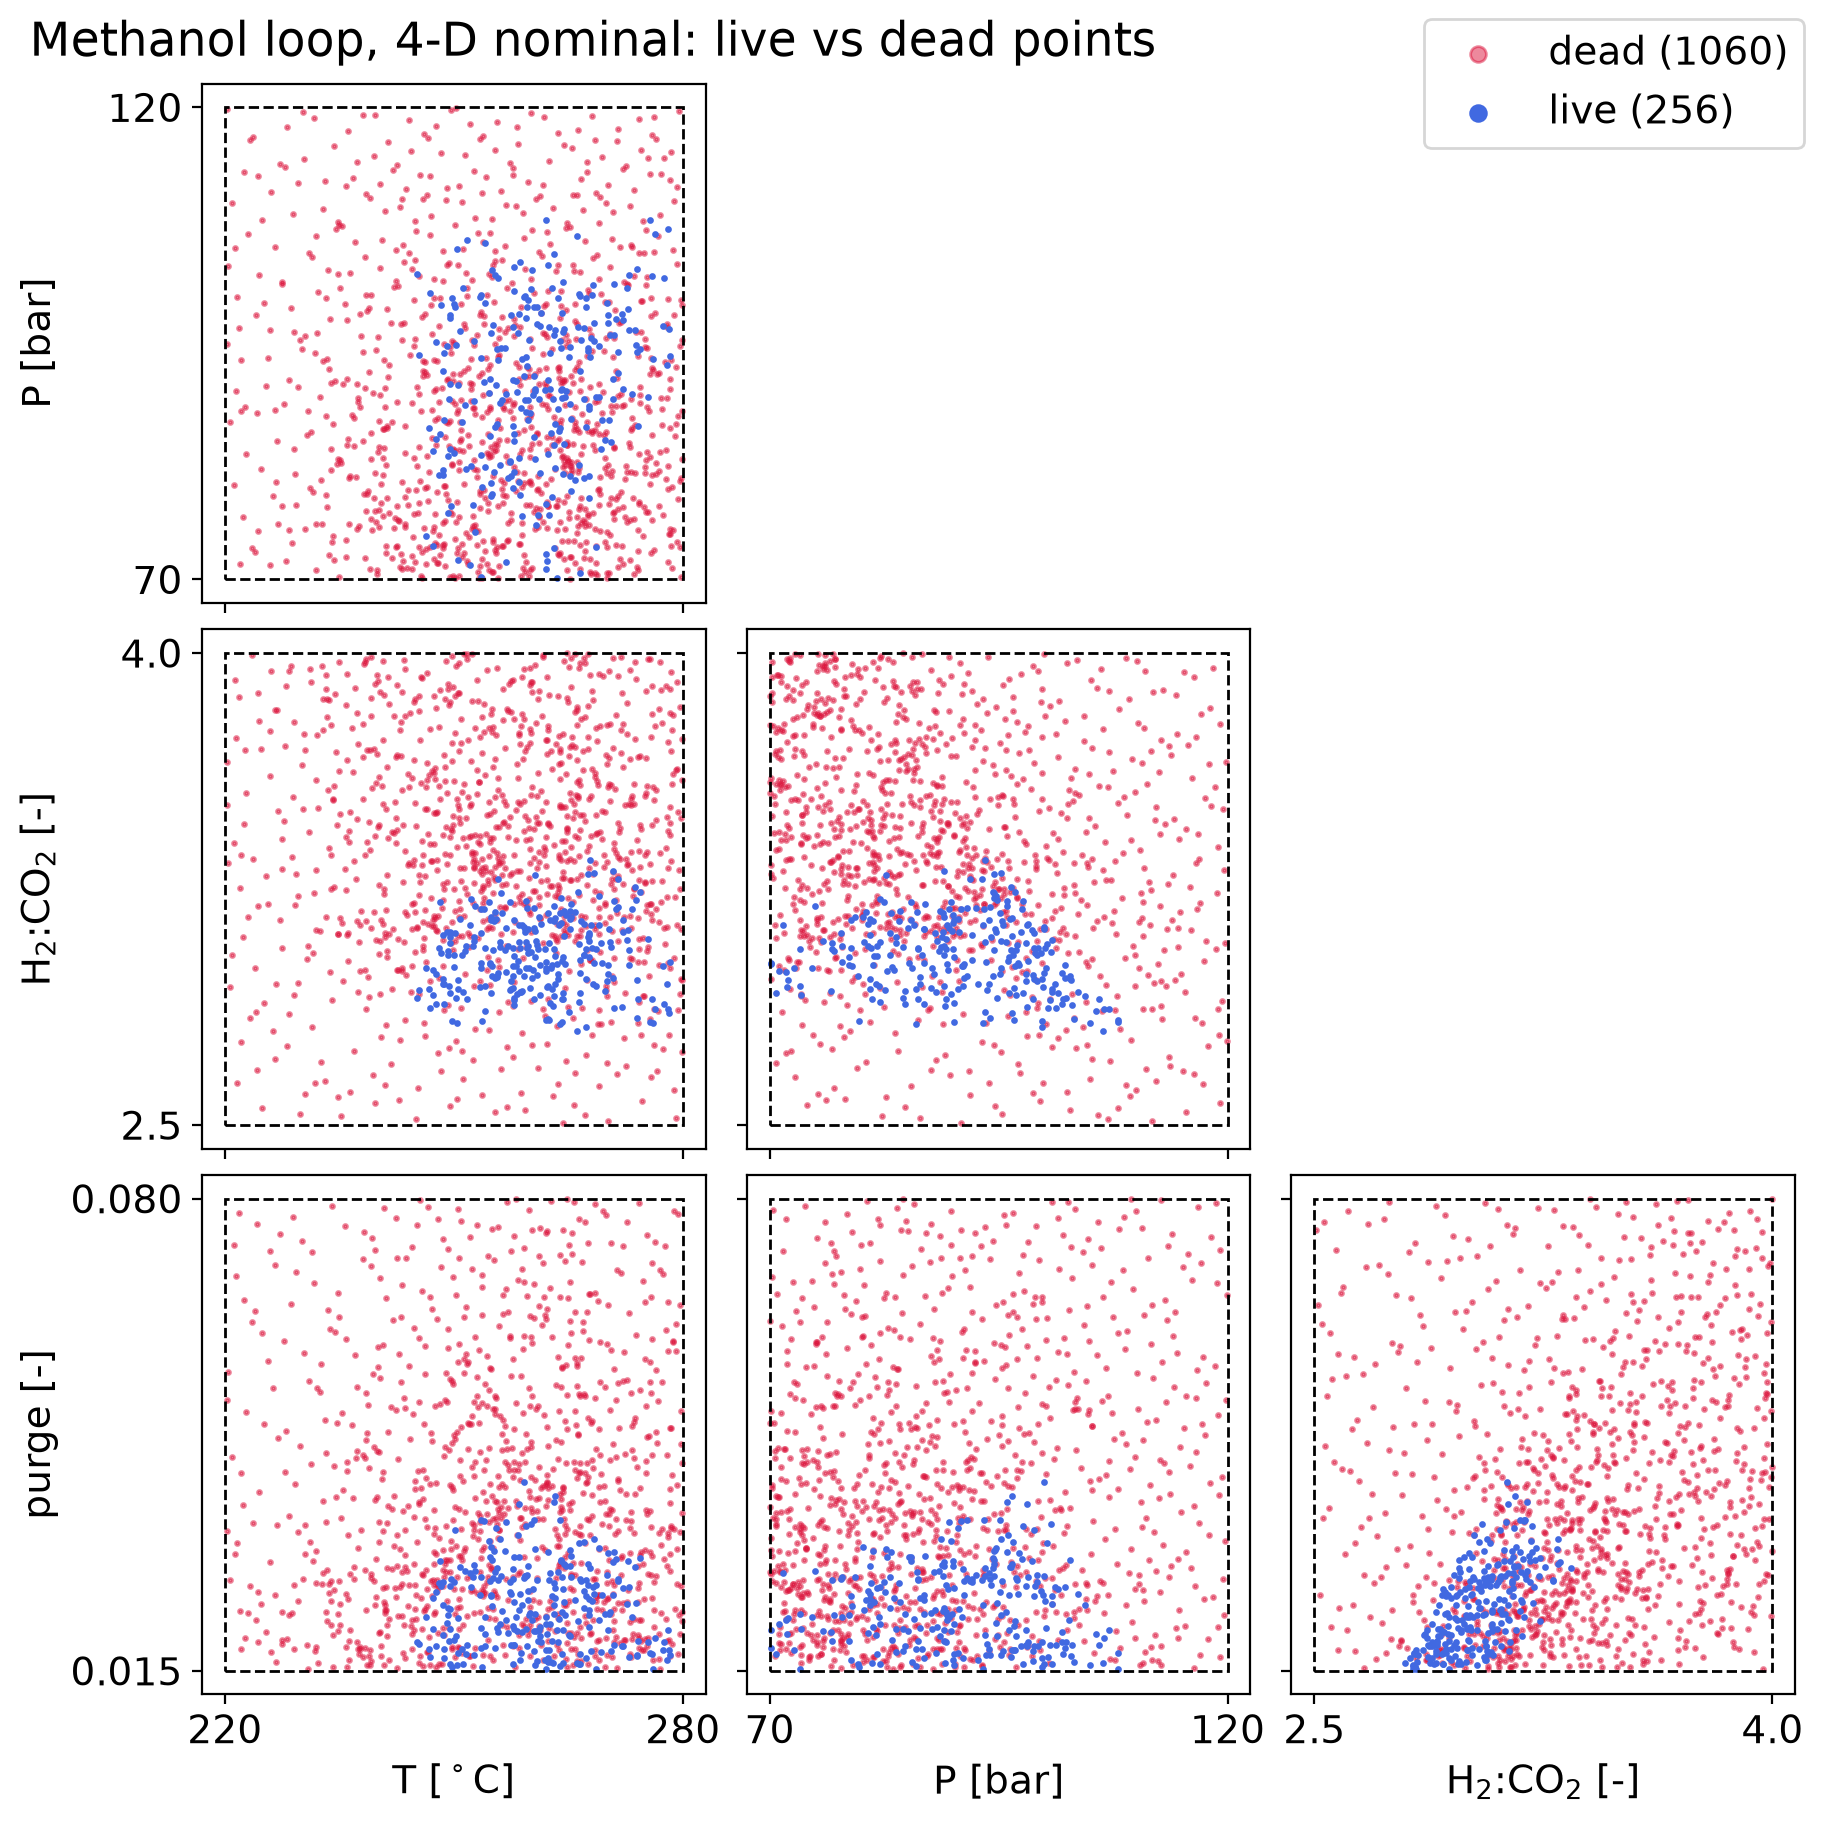

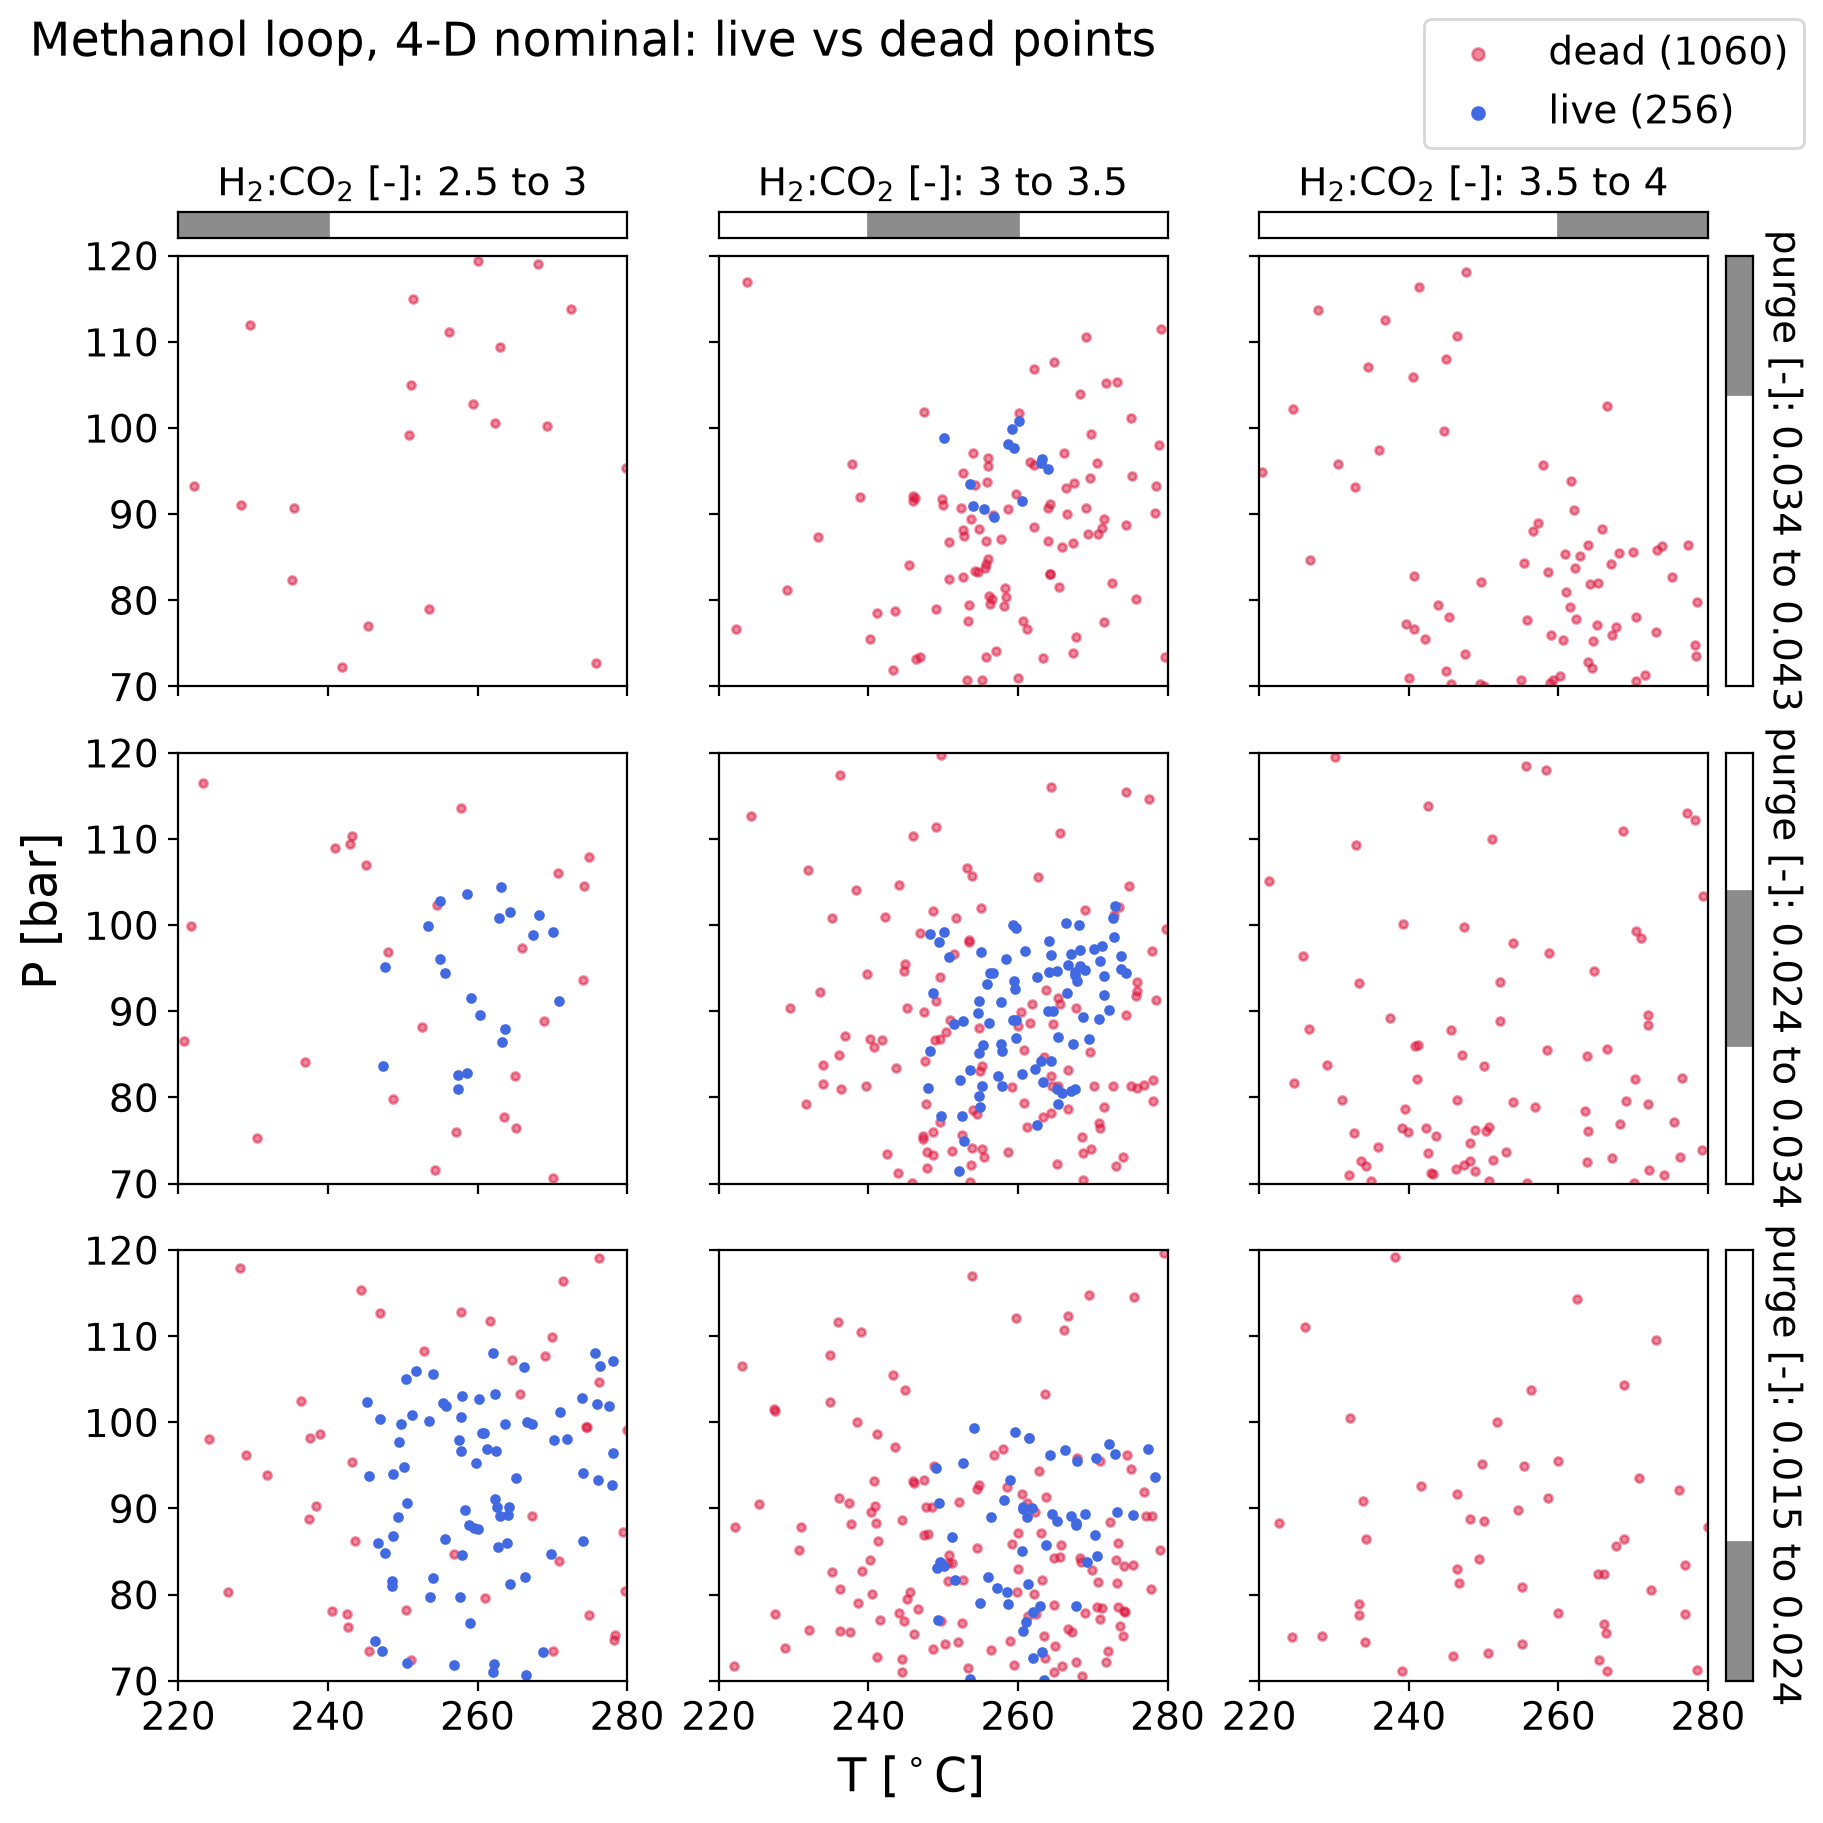

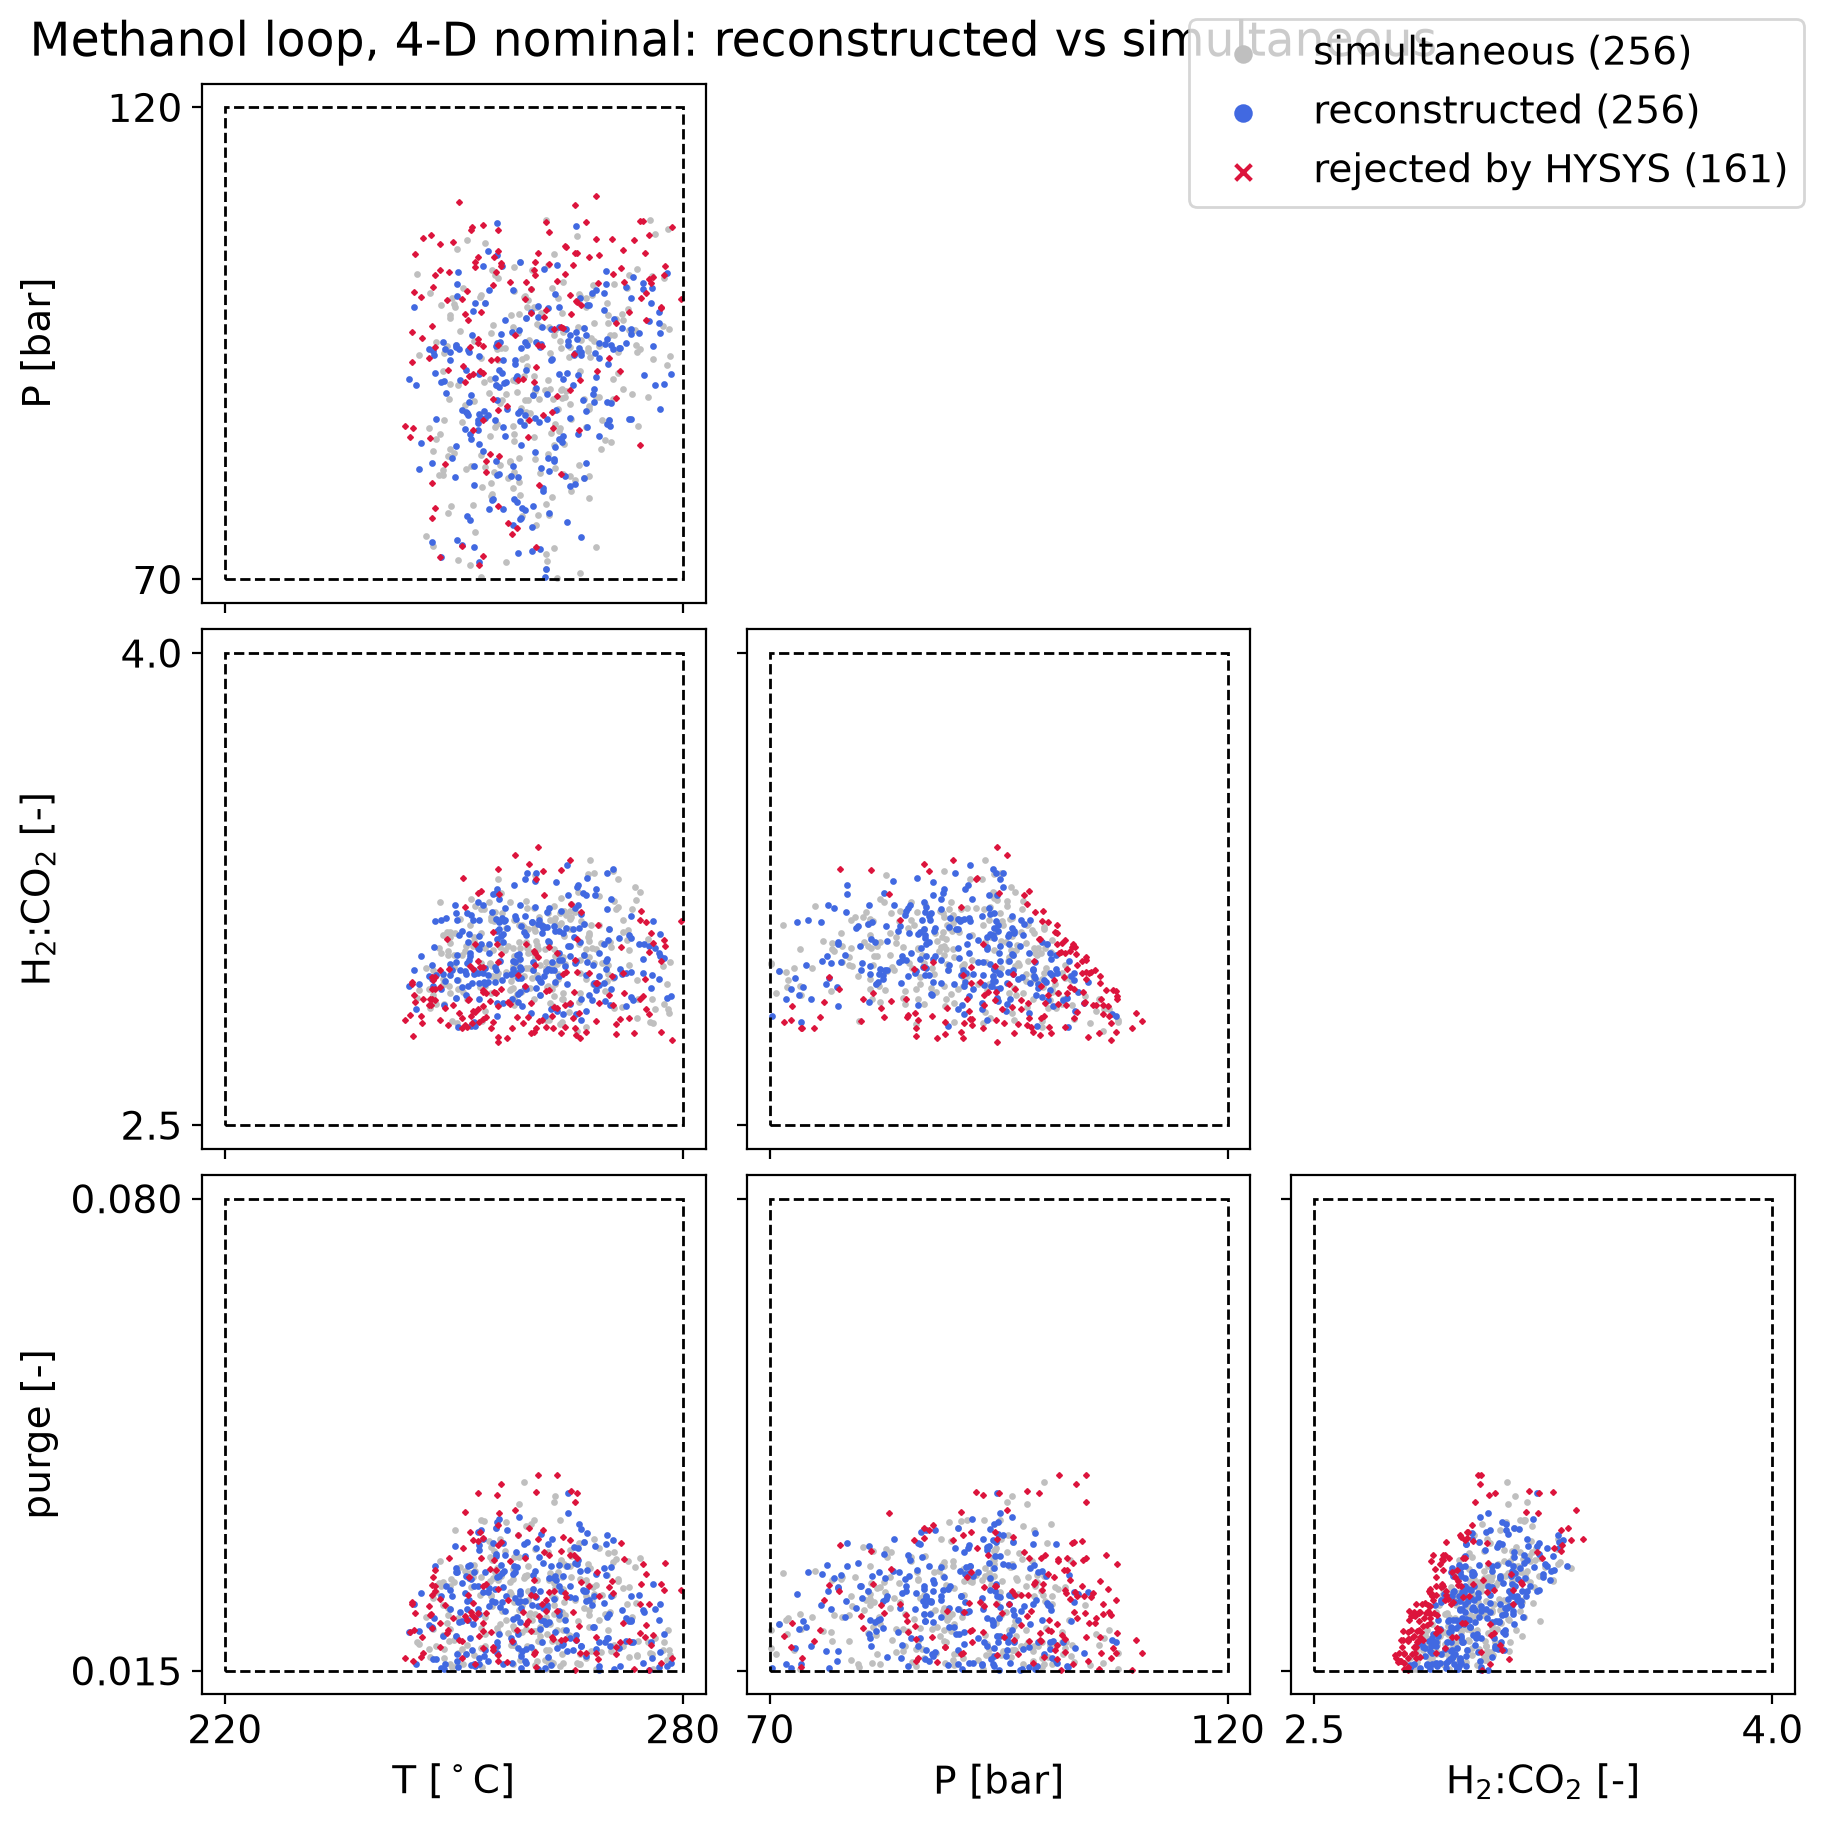

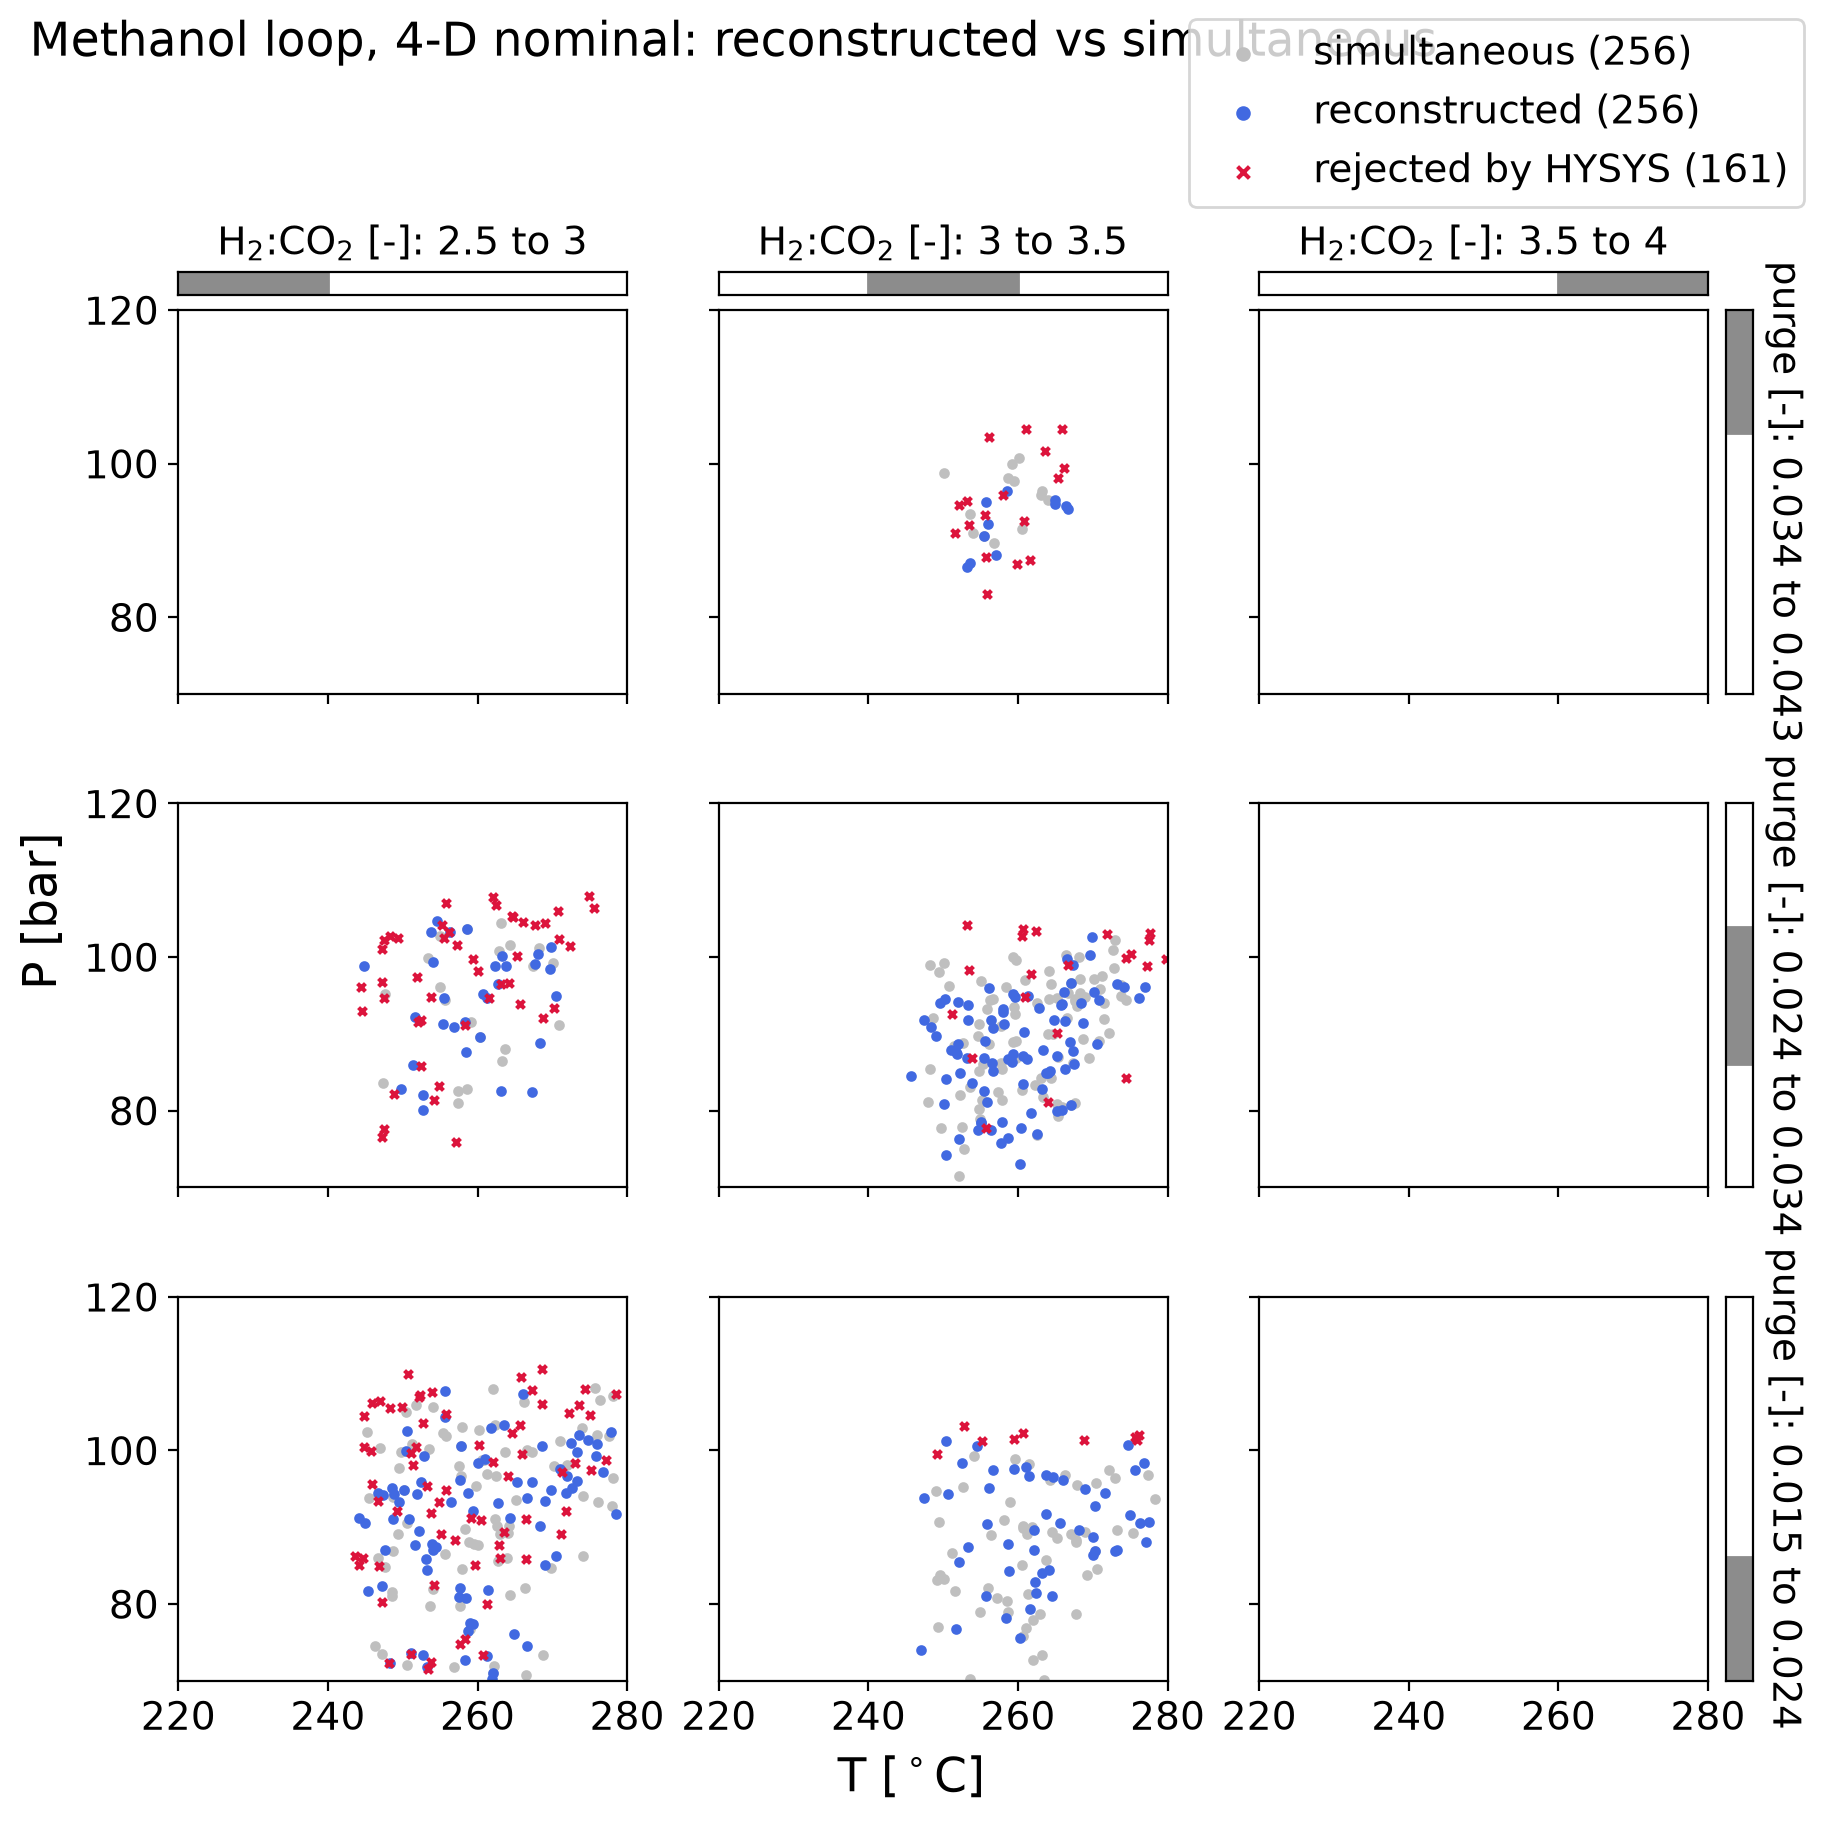

In [11]:
runs = {"nominal": feasibility(None, "nominal")}
figures(runs["nominal"], "nominal", "Methanol loop, 4-D nominal")
backup()

## E  Feasibility under the N$_2$ scenarios, and the comparison


** INITIALIZING LIVE POINTS 00:33:11  probabilistic surrogate: 100 evaluations, 1 min
00:34:32  probabilistic surrogate: 200 evaluations, 3 min
00:35:55  probabilistic surrogate: 300 evaluations, 4 min
00:37:19  probabilistic surrogate: 400 evaluations, 5 min
00:38:41  probabilistic surrogate: 500 evaluations, 7 min
00:40:06  probabilistic surrogate: 600 evaluations, 8 min
00:41:33  probabilistic surrogate: 700 evaluations, 10 min
00:42:53  probabilistic surrogate: 800 evaluations, 11 min
00:44:19  probabilistic surrogate: 900 evaluations, 12 min
00:45:48  probabilistic surrogate: 1000 evaluations, 14 min
00:47:12  probabilistic surrogate: 1100 evaluations, 15 min
00:48:31  probabilistic surrogate: 1200 evaluations, 17 min
00:49:52  probabilistic surrogate: 1300 evaluations, 18 min
00:51:15  probabilistic surrogate: 1400 evaluations, 19 min
00:52:39  probabilistic surrogate: 1500 evaluations, 21 min
00:54:03  probabilistic surrogate: 1600 evaluations, 22 min
00:55:25  probabilistic su

C:\Users\kr326\AppData\Local\Temp\ipykernel_25424\1186479883.py:24: UserWarning: 422 of 1150 points lie outside the bin edges and appear in no panel
  grid.scatter(X[:, T], X[:, P], X[:, R], X[:, U], s=8, label=label, **kw)


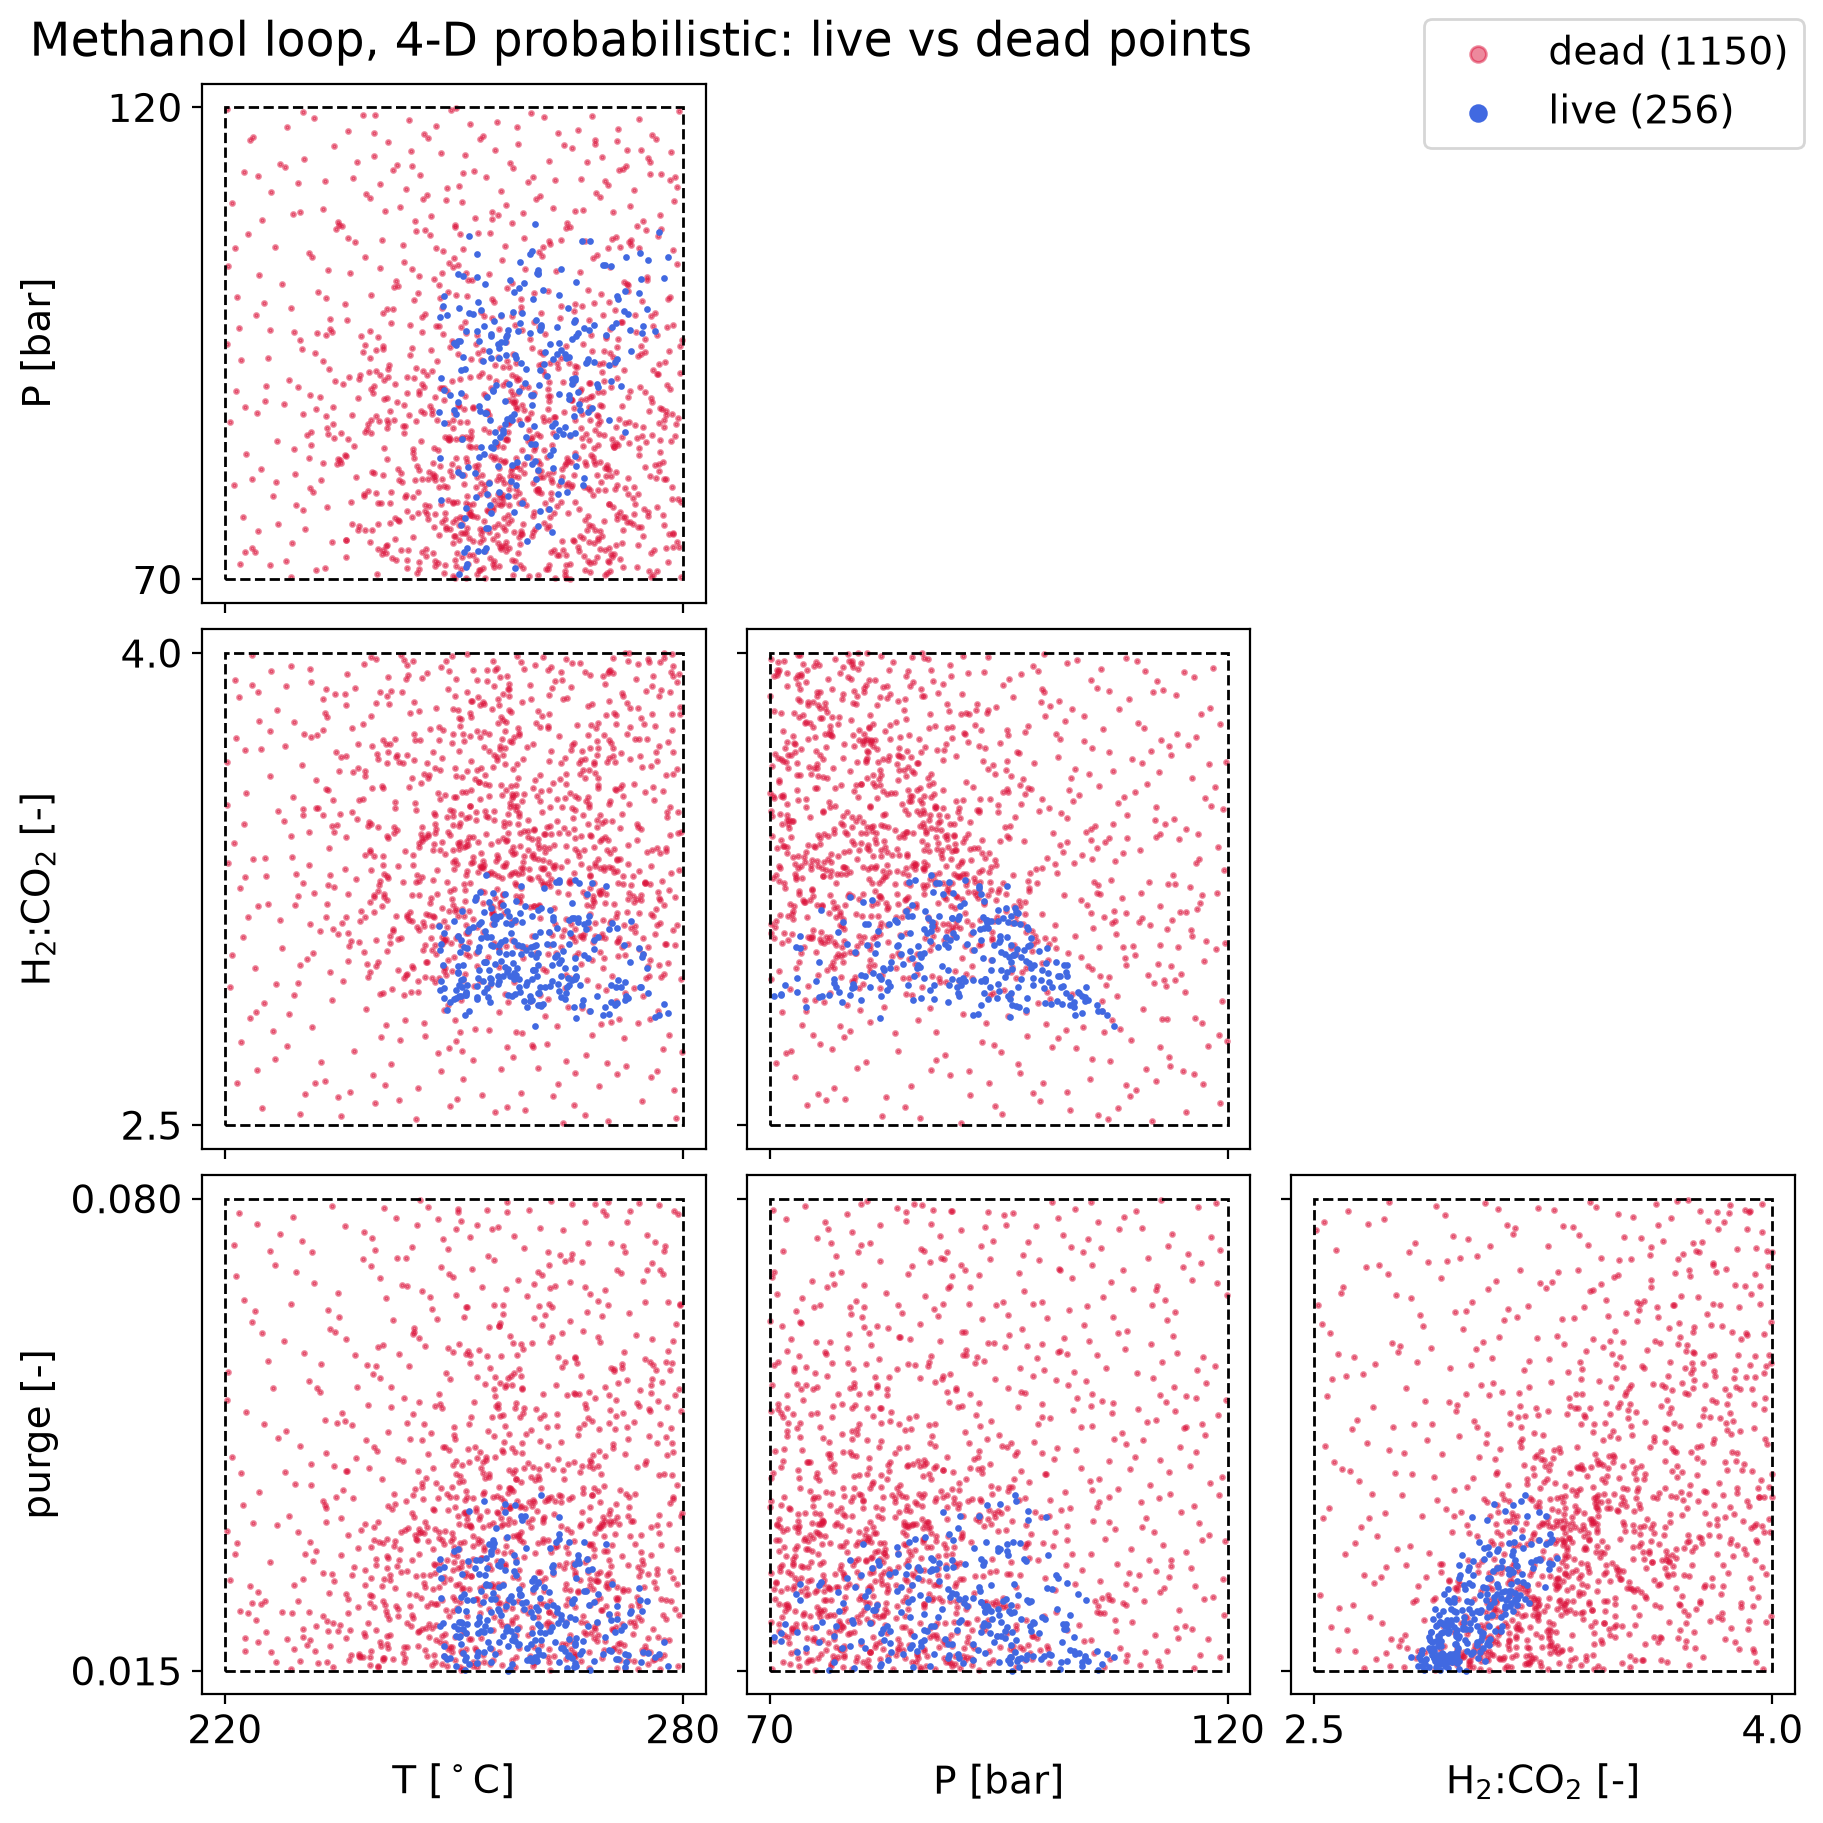

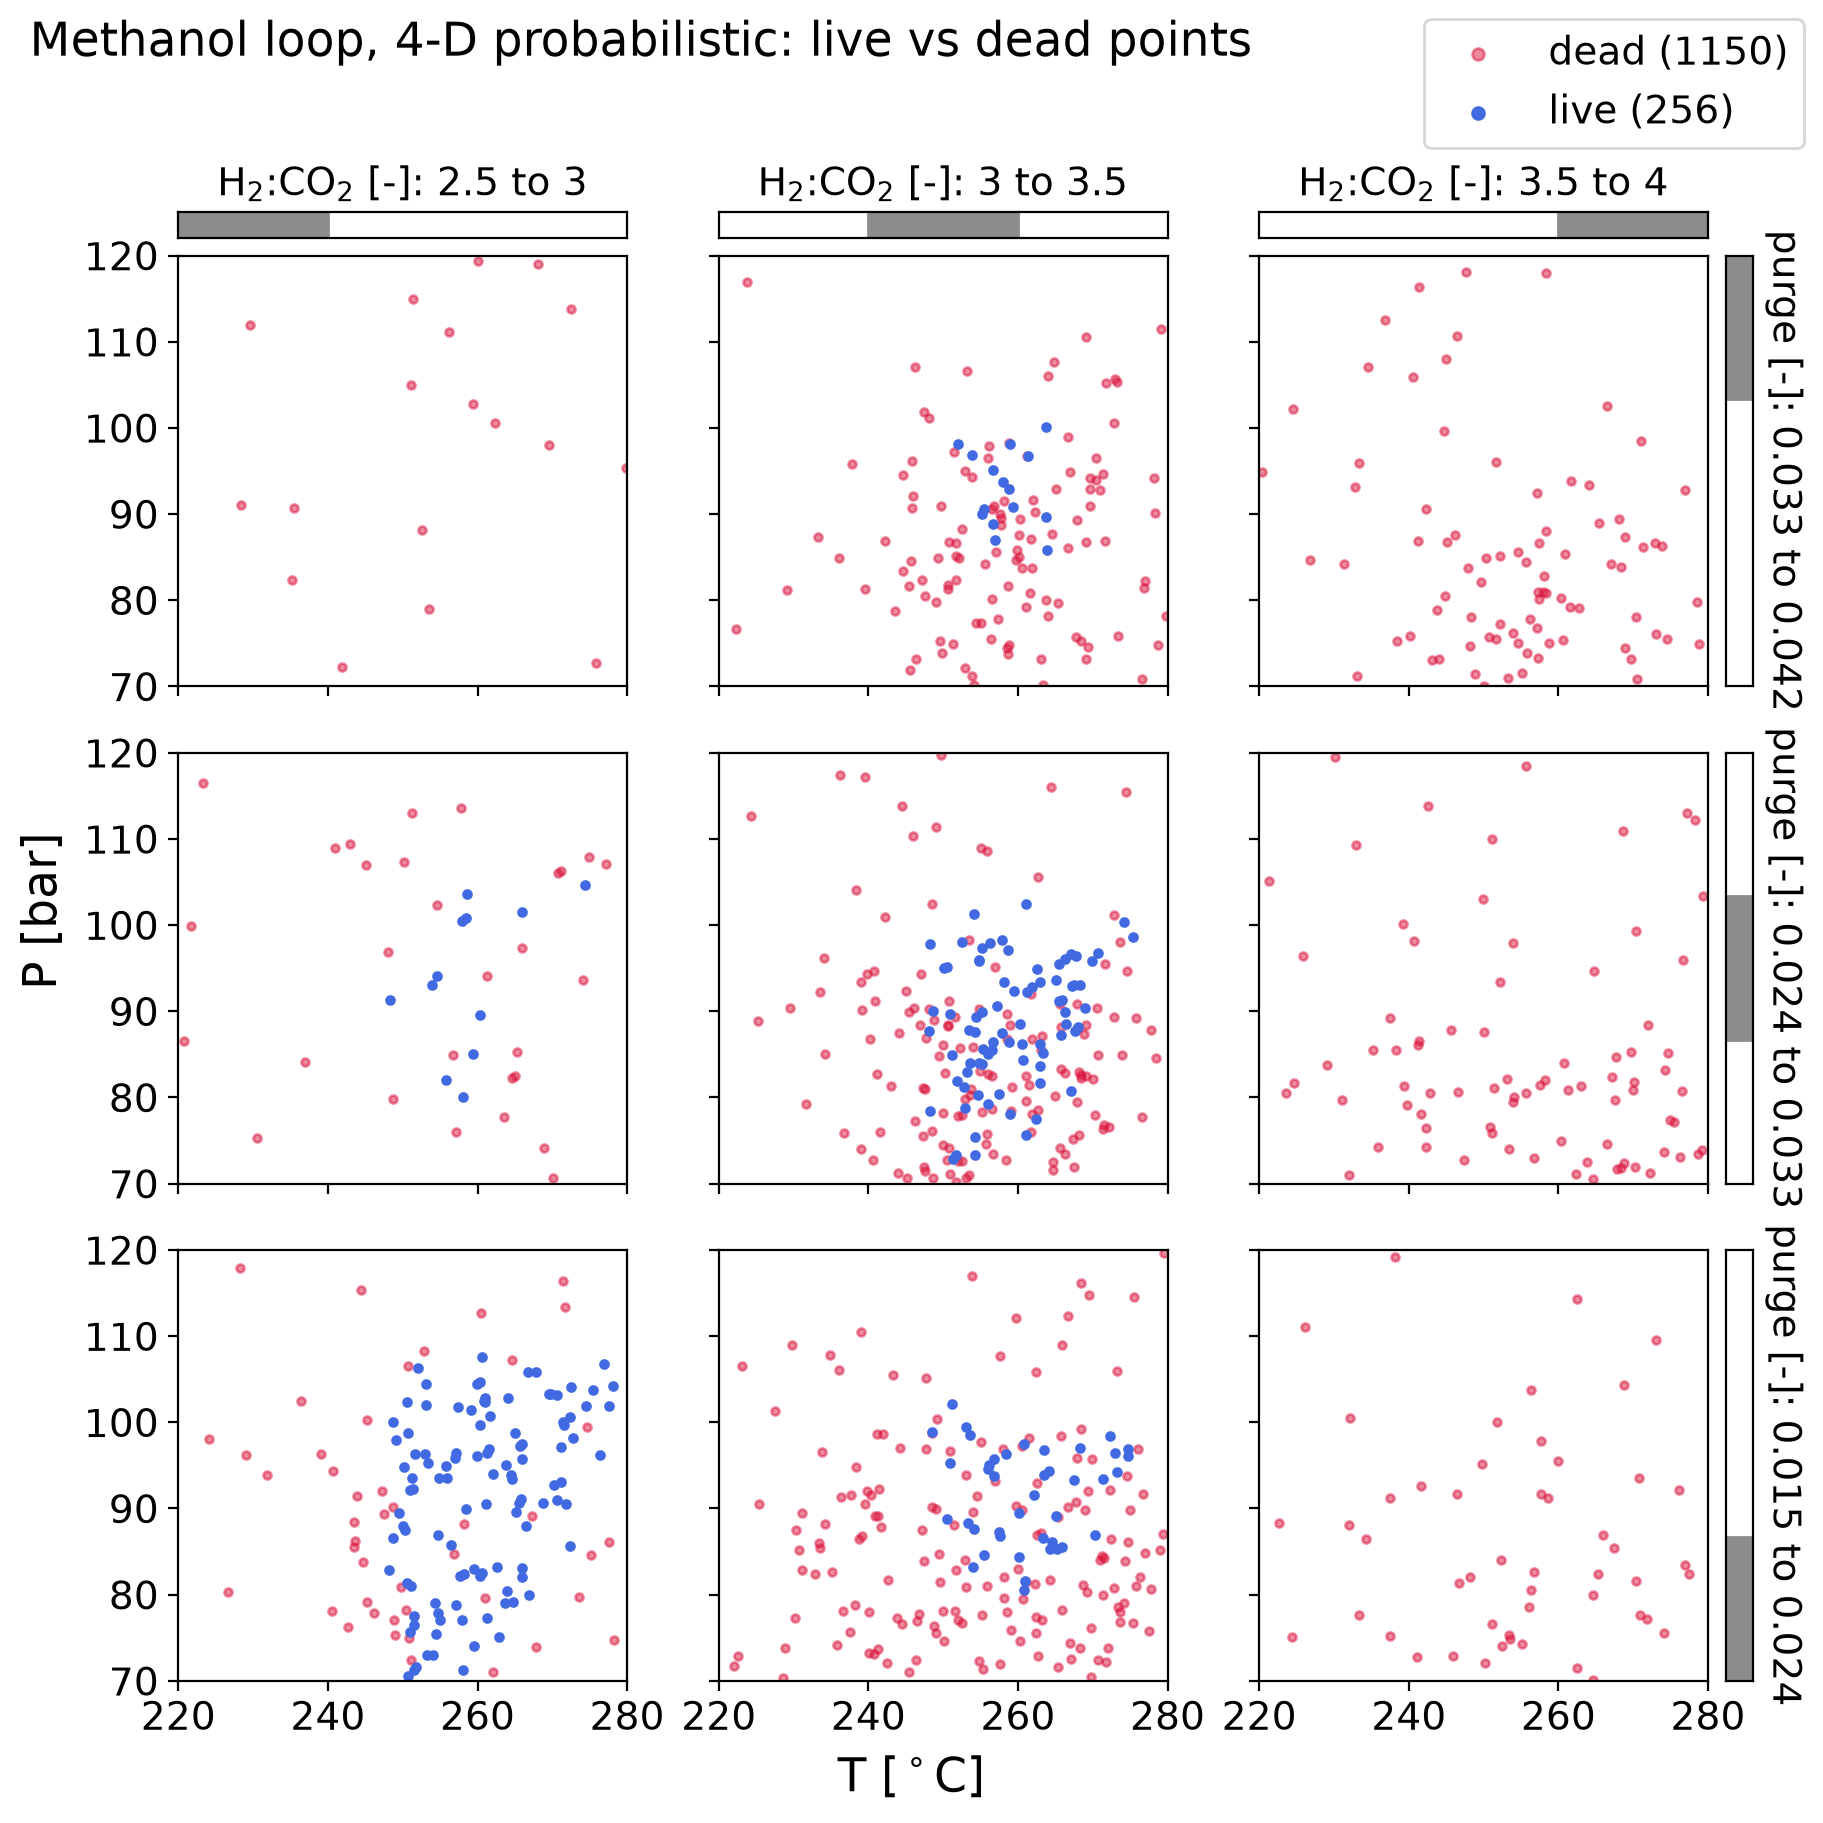

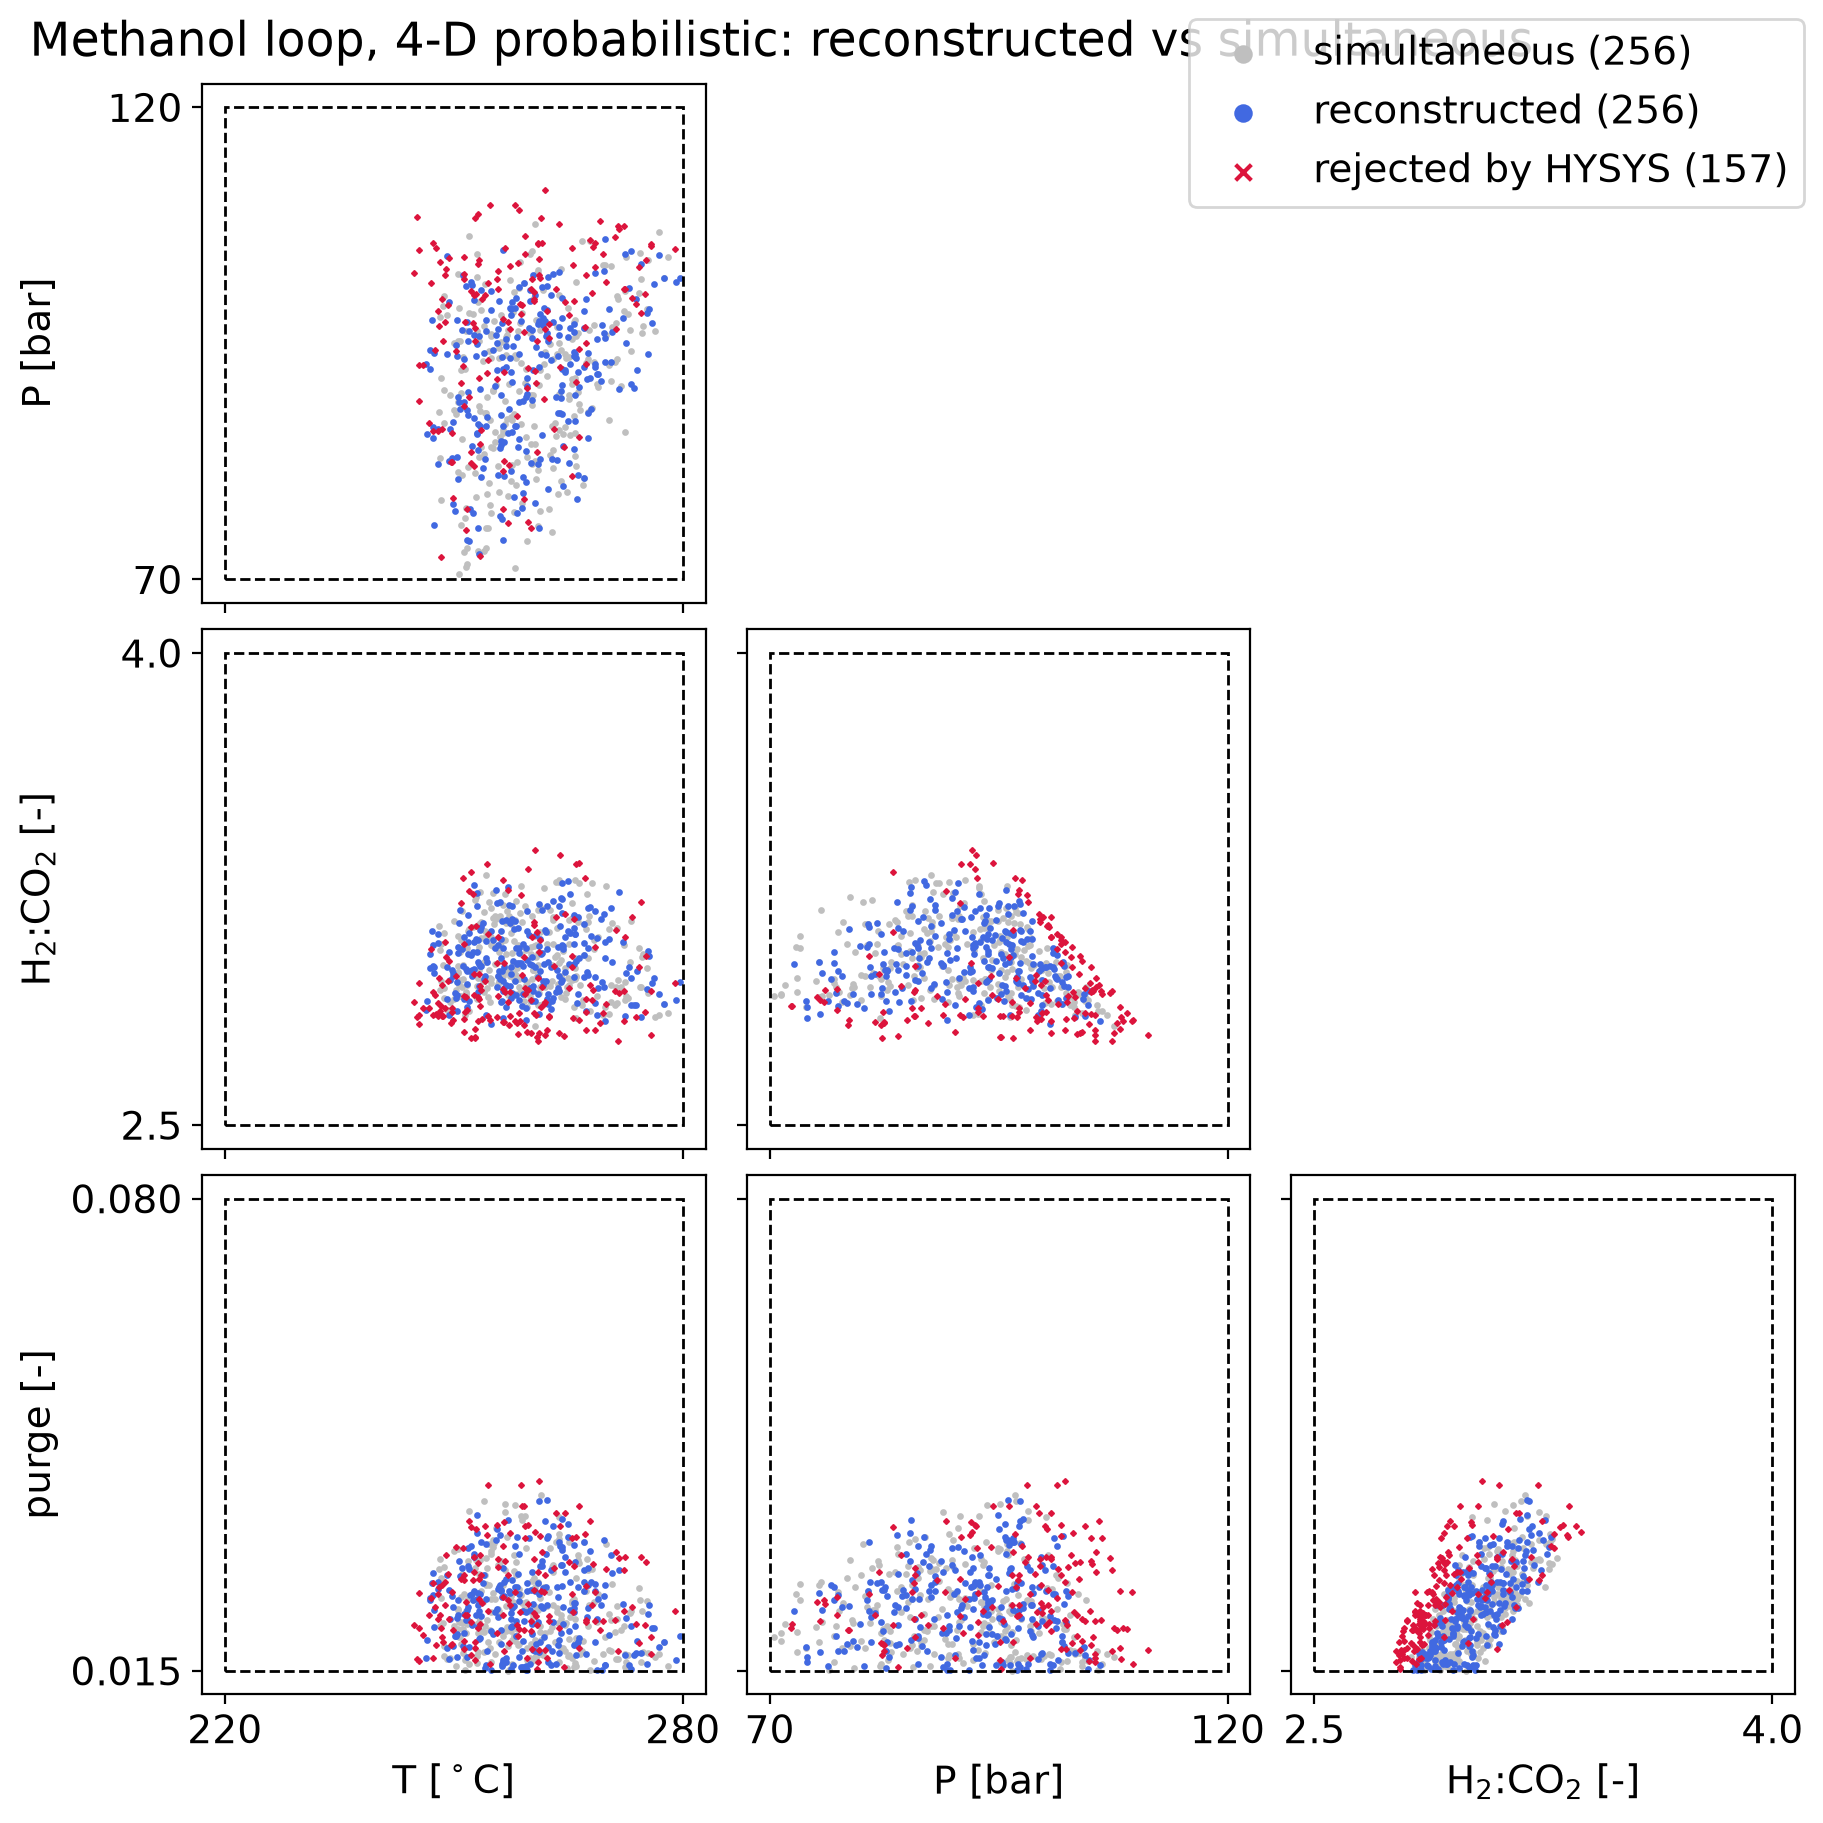

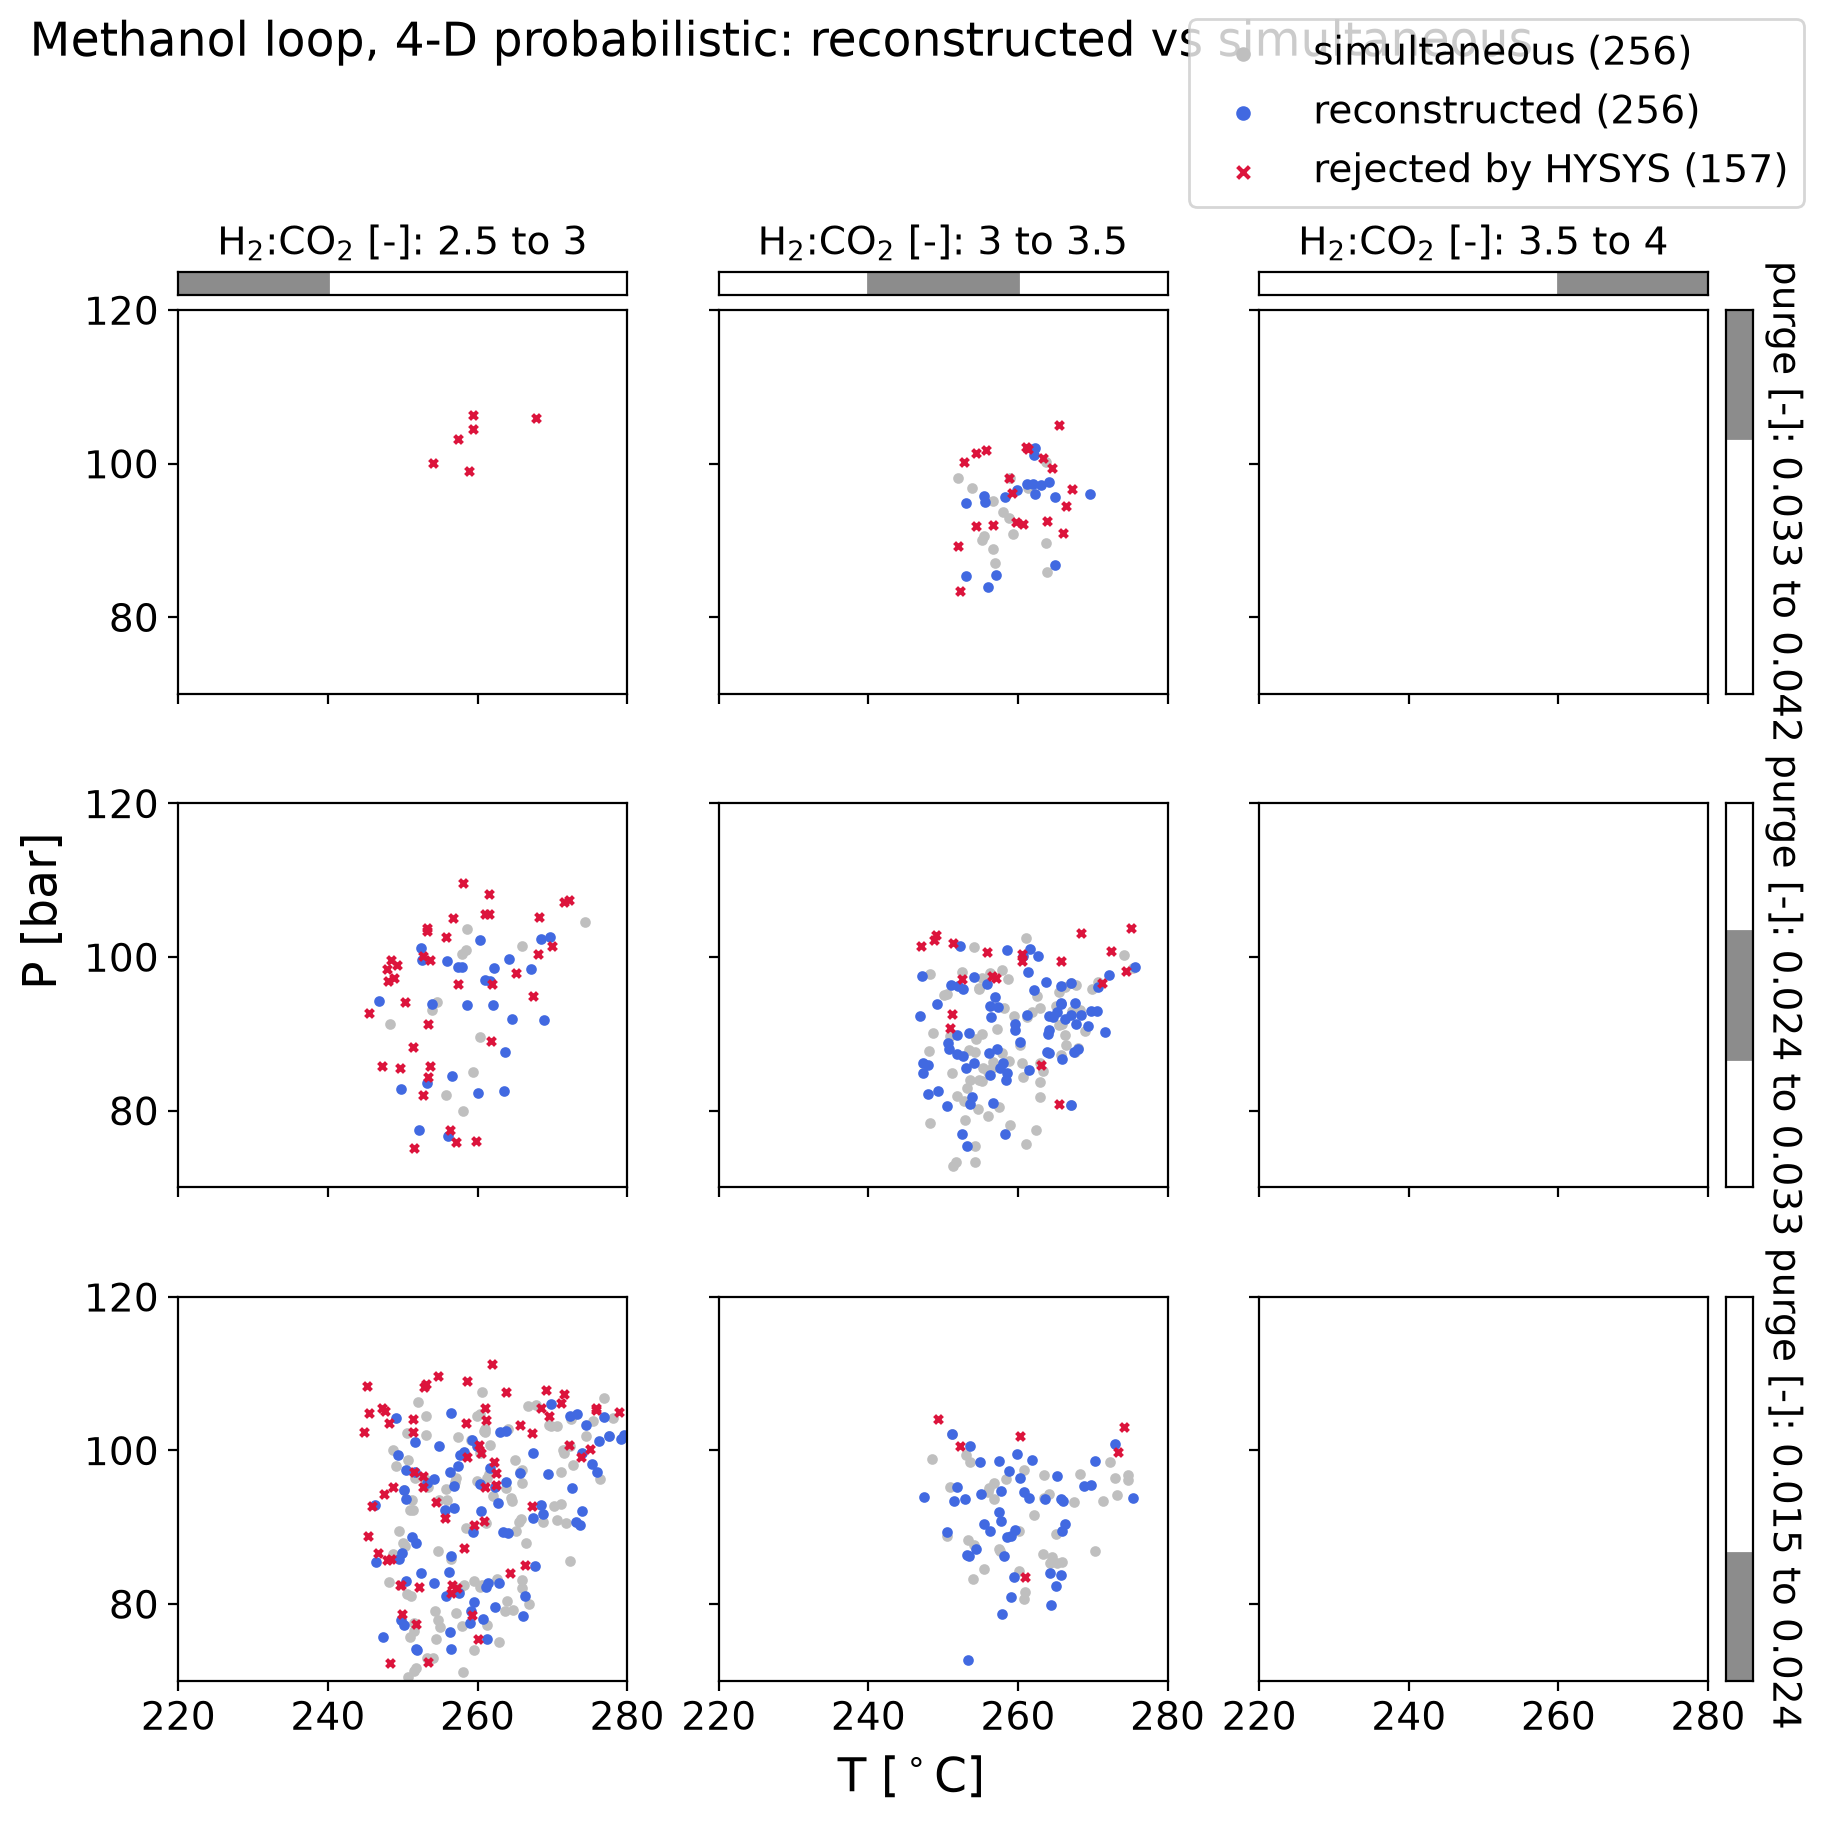

In [12]:
runs["probabilistic"] = feasibility(SCENARIOS, "probabilistic")
figures(runs["probabilistic"], "probabilistic", "Methanol loop, 4-D probabilistic")
backup()

WindowsPath('C:/Users/kr326/Documents/MScThesis/figures/Cases/HYSYS_MeOH_4D/corner_probabilistic_vs_nominal.png')

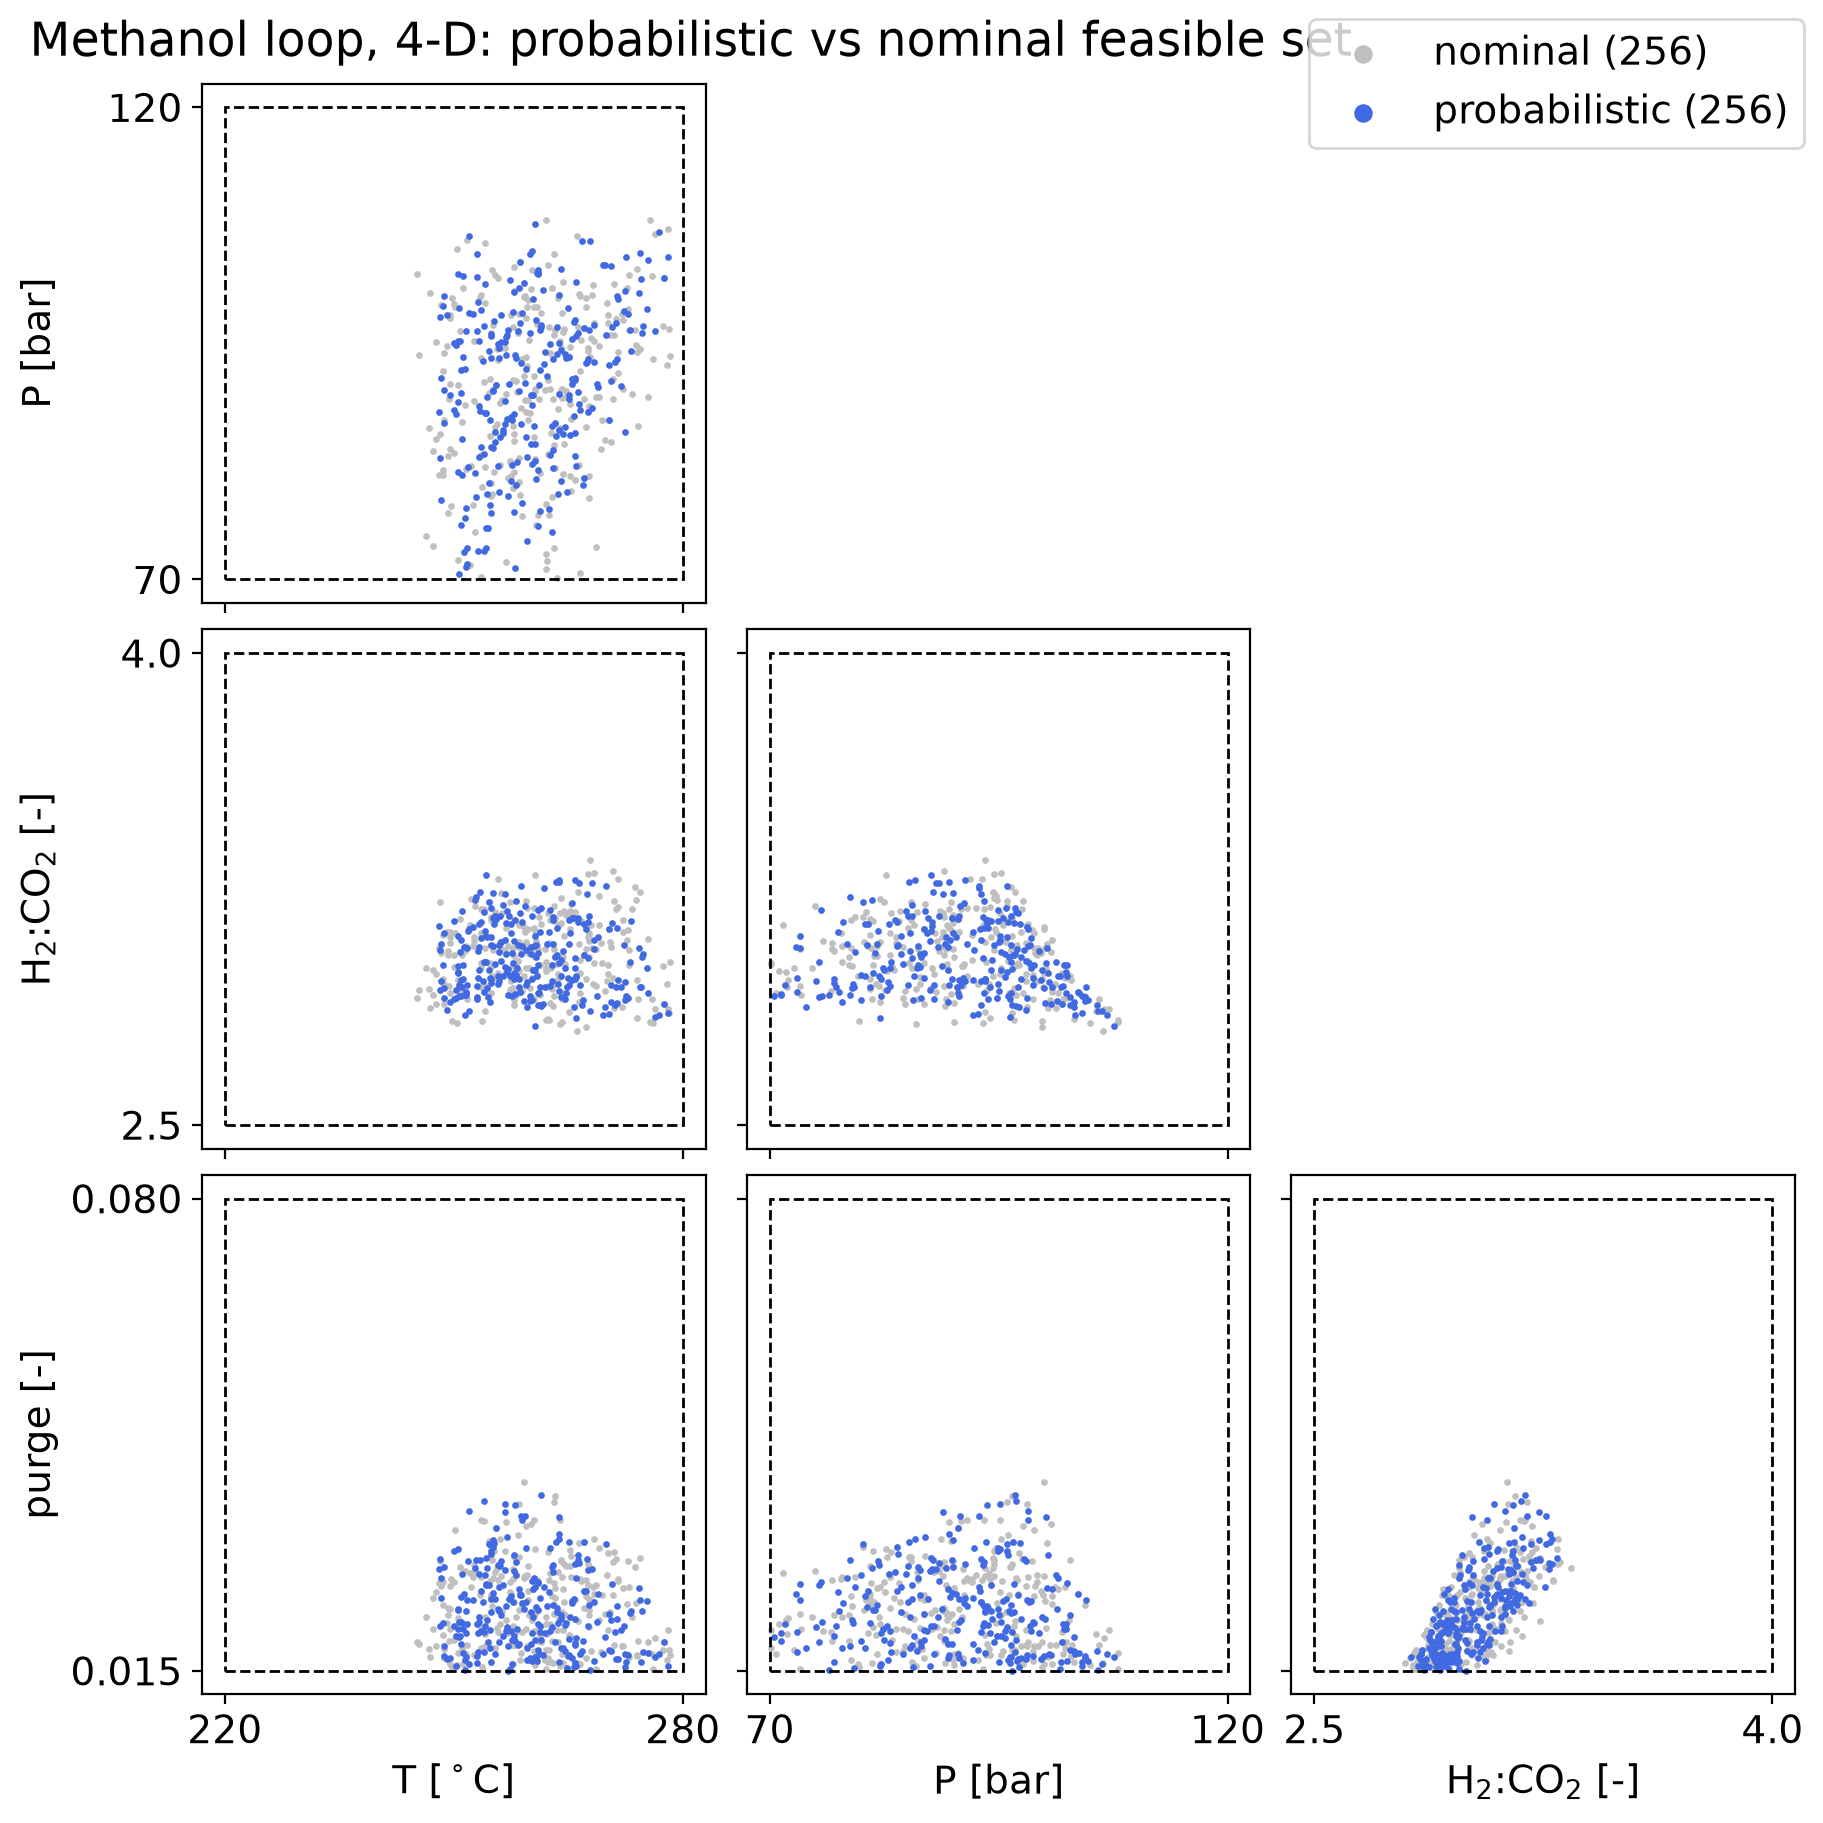

In [13]:
# Probabilistic against nominal feasible set, both from the HYSYS benchmark
grid = Corner(LABELS, BOX)
for name, color in (("nominal", "0.75"), ("probabilistic", "royalblue")):
    live = runs[name]["hysys"]["result"].live
    grid.scatter(live.x[live.feasible], s=2, color=color, label=f"{name} ({int(live.feasible.sum())})")
grid.fig.legend(markerscale=4)
grid.fig.suptitle("Methanol loop, 4-D: probabilistic vs nominal feasible set", x=0.01, ha="left")
save(grid.fig, f"{FIG}/corner_probabilistic_vs_nominal{TAG}")

In [14]:
def benchmark(out):
    """Decomposition against the simultaneous HYSYS analysis: flowsheet equivalents (1 EQ = one HYSYS loop solve, i.e.
    one design point under one scenario; PFR solves weighted by solver time; surrogate evaluations free by convention),
    wall time (the surrogate loop is not free: HYSYS solves the separation every tear pass), the true-feasible rate of
    the candidates, and the set metrics of the reconstructed against the simultaneous set in box units."""
    s_loop = df_hull.solve_time_s.mean()
    eq_dec, eq_sim = len(df_hull) + df_pfr.solve_time_s.sum() / s_loop + out["n_ver"], len(out["hysys"]["df"])
    t_dec, t_sim = t_hull + t_pfr + t_train[NET] + out["surrogate"]["wall_s"] + out["t_ver"], out["hysys"]["wall_s"]
    live, cand = out["hysys"]["result"].live, out["cand"]
    return pd.Series({"EQ decomposition": eq_dec, "EQ simultaneous": eq_sim, "cost ratio": eq_sim / eq_dec,
                      "wall decomposition [min]": t_dec / 60, "wall simultaneous [min]": t_sim / 60, "speed-up": t_sim / t_dec,
                      "true feasible rate [%]": 100 * cand.verified.mean(),
                      **set_metrics(cand.loc[cand.verified, list(DESIGN)].to_numpy(), live.x[live.feasible], BOX)})

pd.DataFrame({name: benchmark(out) for name, out in runs.items()}).round(2)

,nominal,probabilistic
EQ decomposition,890.35,2598.35
EQ simultaneous,4176.00,39680.00
cost ratio,4.69,15.27
wall decomposition [min],248.14,1861.92
wall simultaneous [min],253.51,2233.74
speed-up,1.02,1.20
true feasible rate [%],61.39,61.99
hausdorff,0.13,0.12
wasserstein,0.07,0.07
precision,0.52,0.50


## F  Thesis figures, regenerated from the pickle (no HYSYS) for visual adjustments post run only
> Below is not functionally relevant to the methodology applied

In [16]:
saved = pickle.load(open(f"backup_4d.pkl", "rb"))
runs = saved["runs"]    # also in `saved`: df_hull, pfr_box, df_pfr, t_hull, t_pfr, t_train

WindowsPath('C:/Users/kr326/Documents/MScThesis/figures/Cases/HYSYS_MeOH_4D/corner_probabilistic_vs_nominal.png')

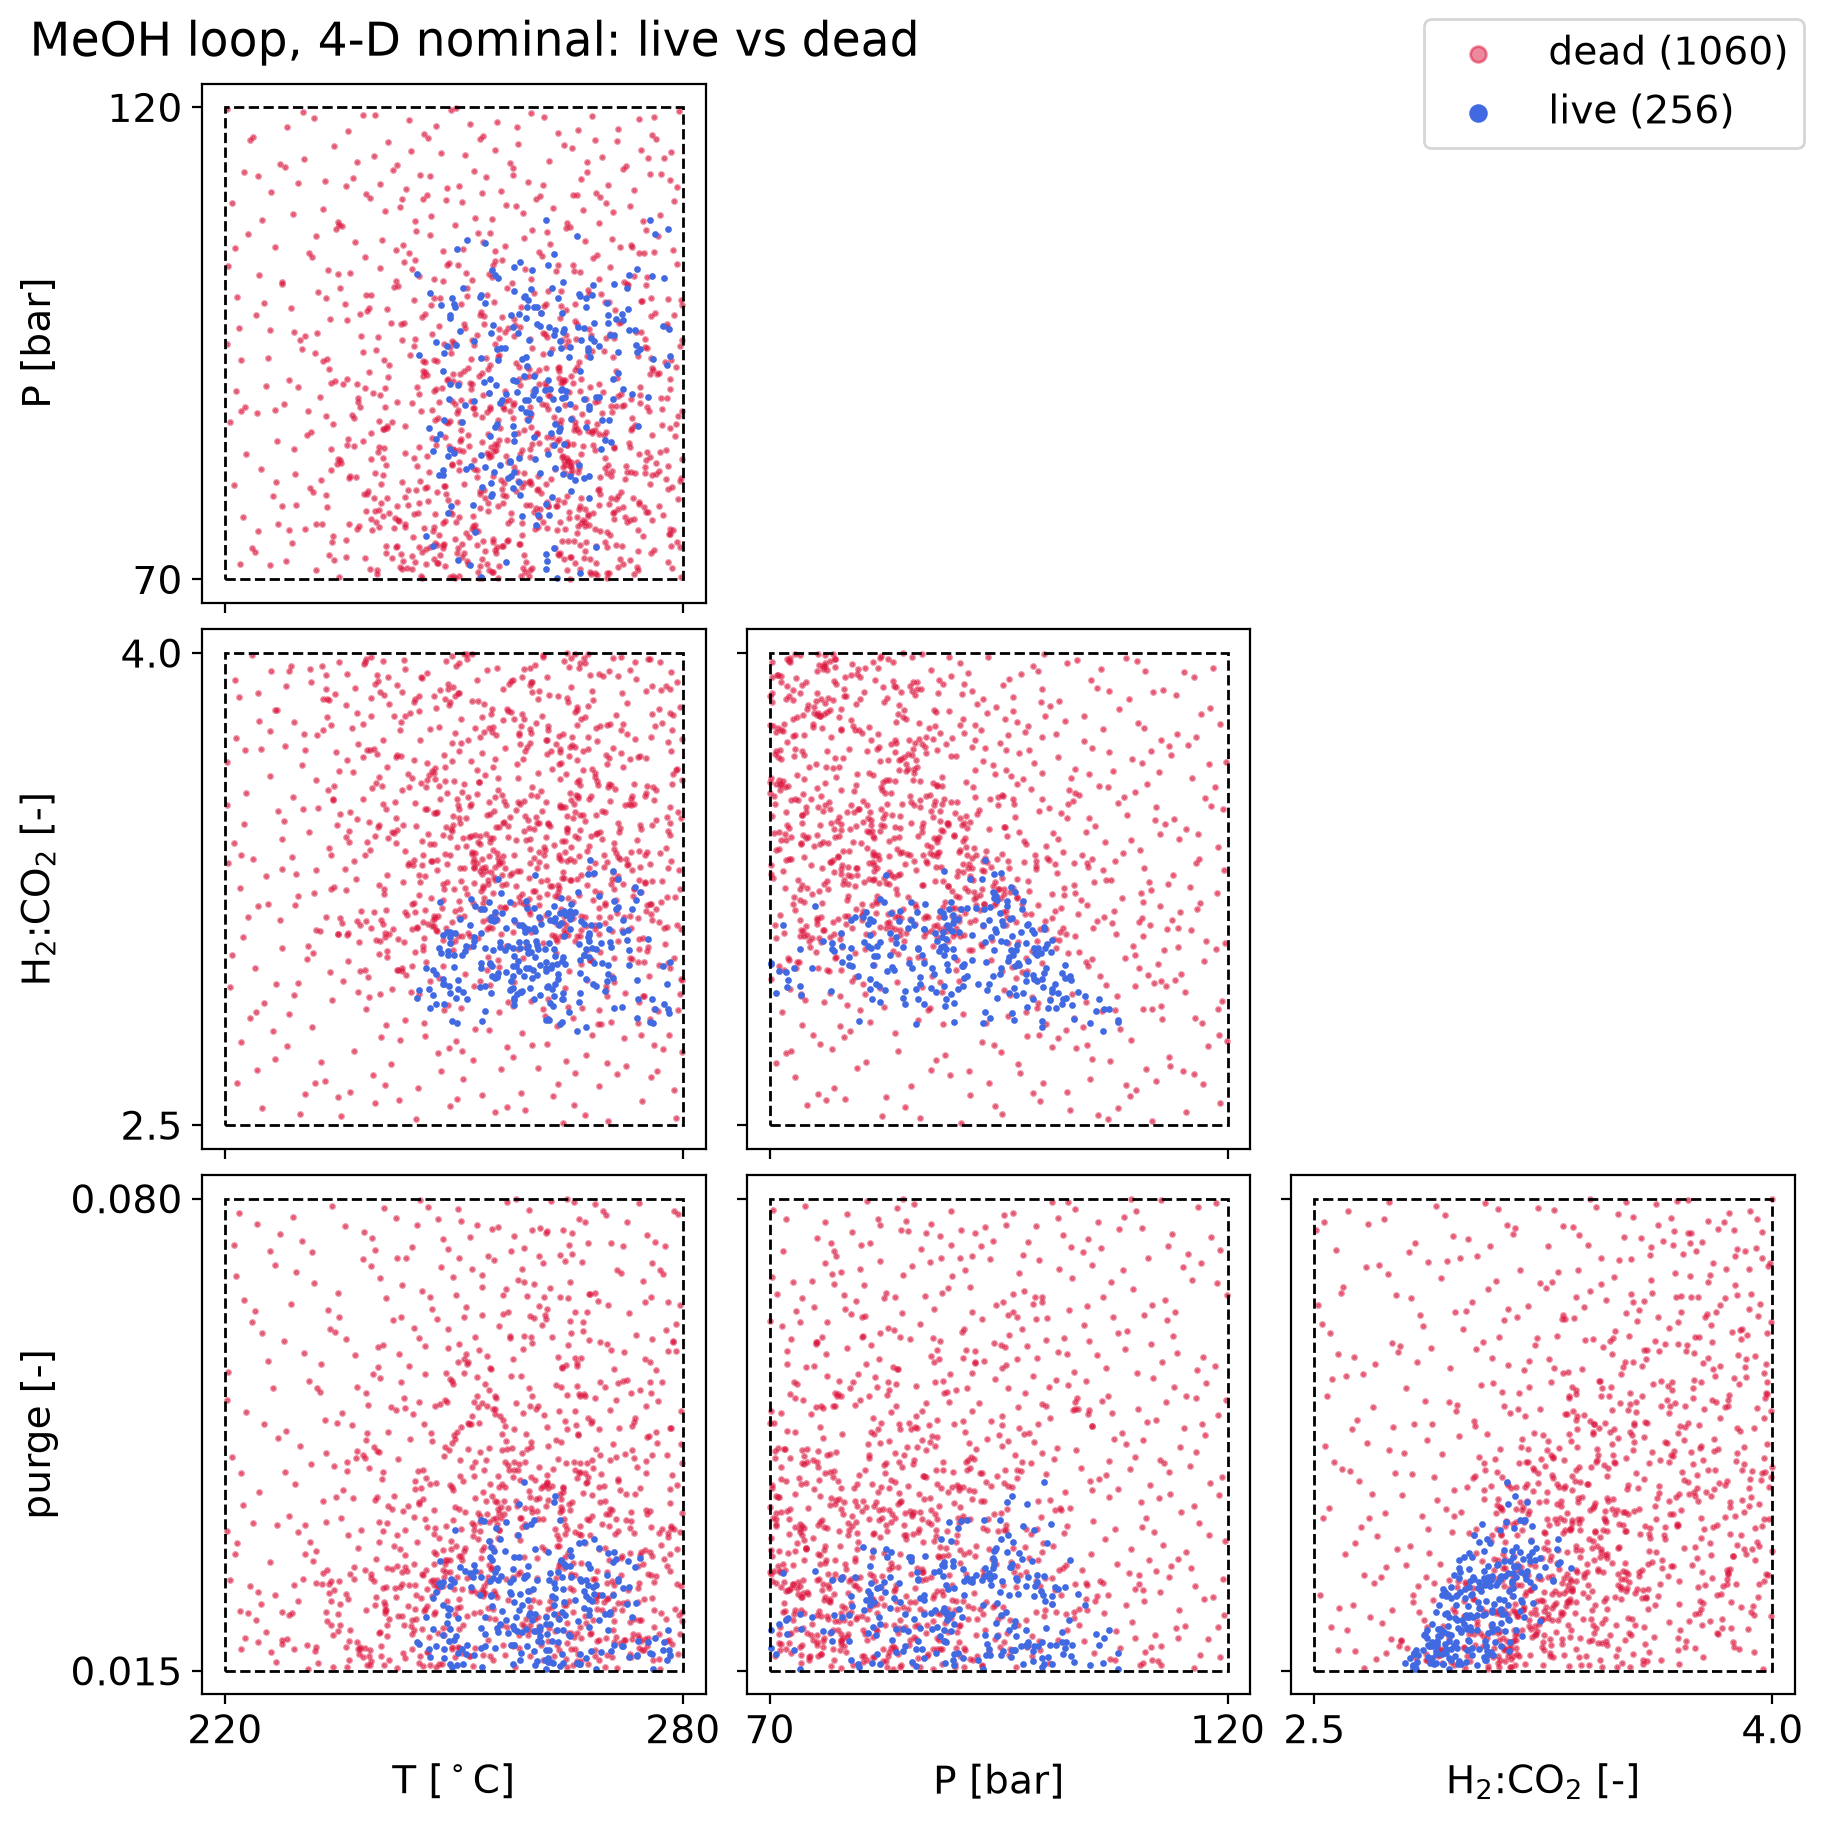

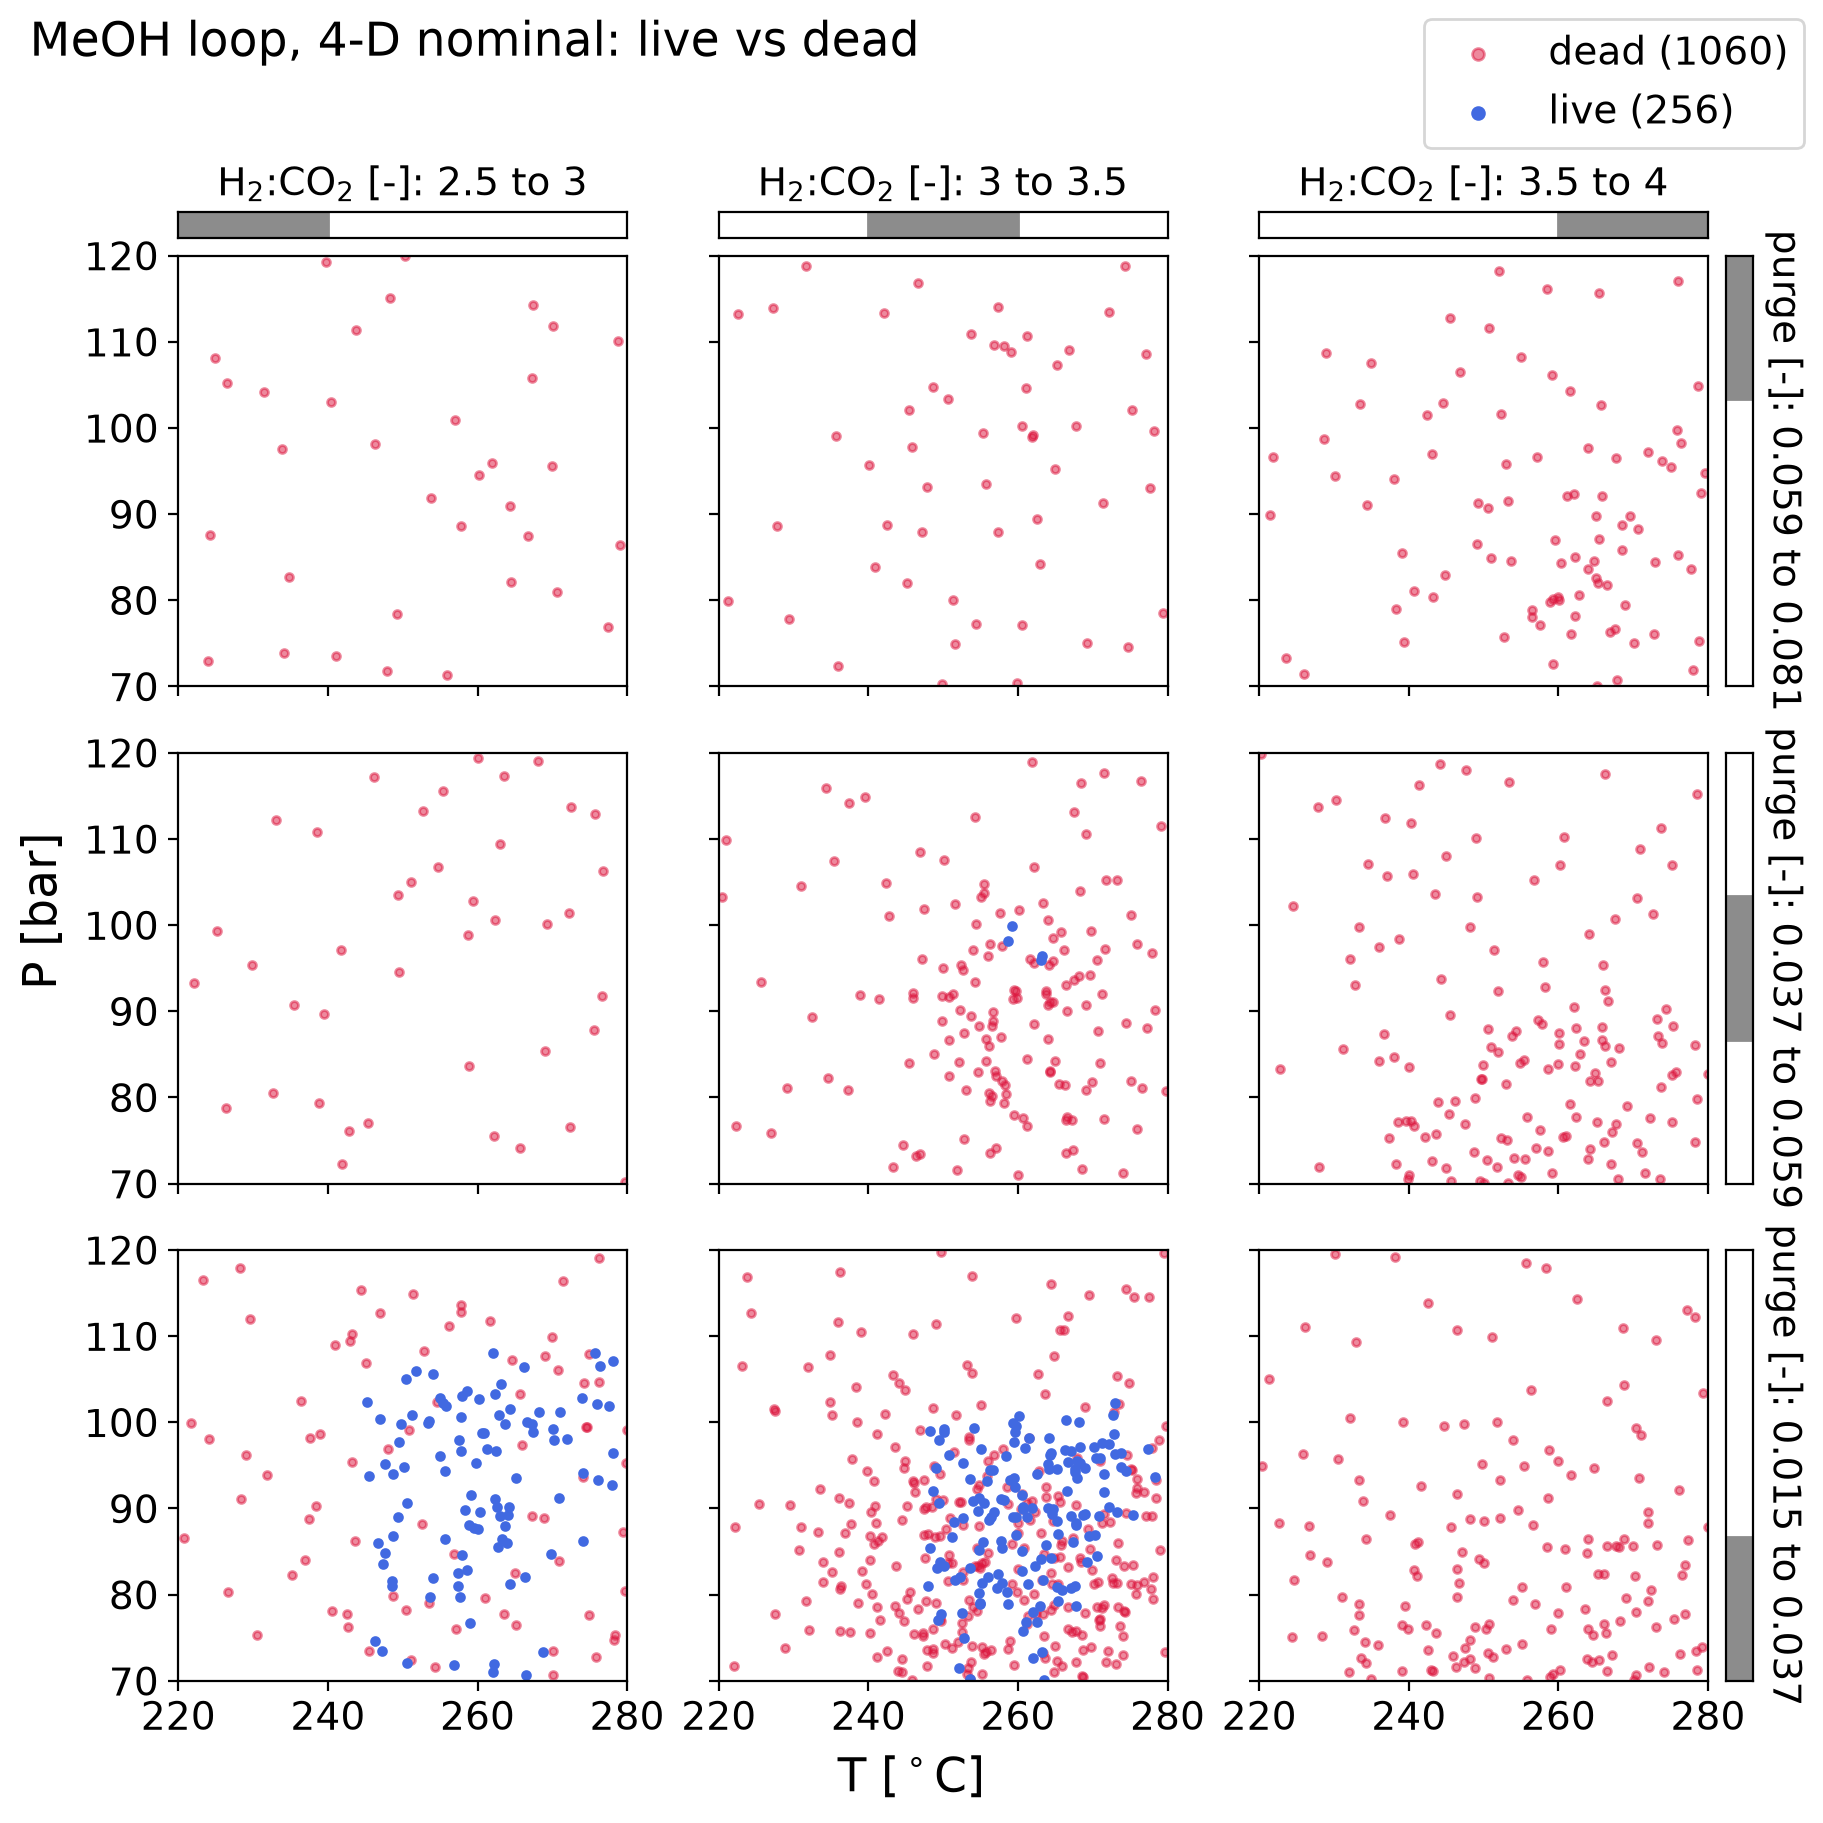

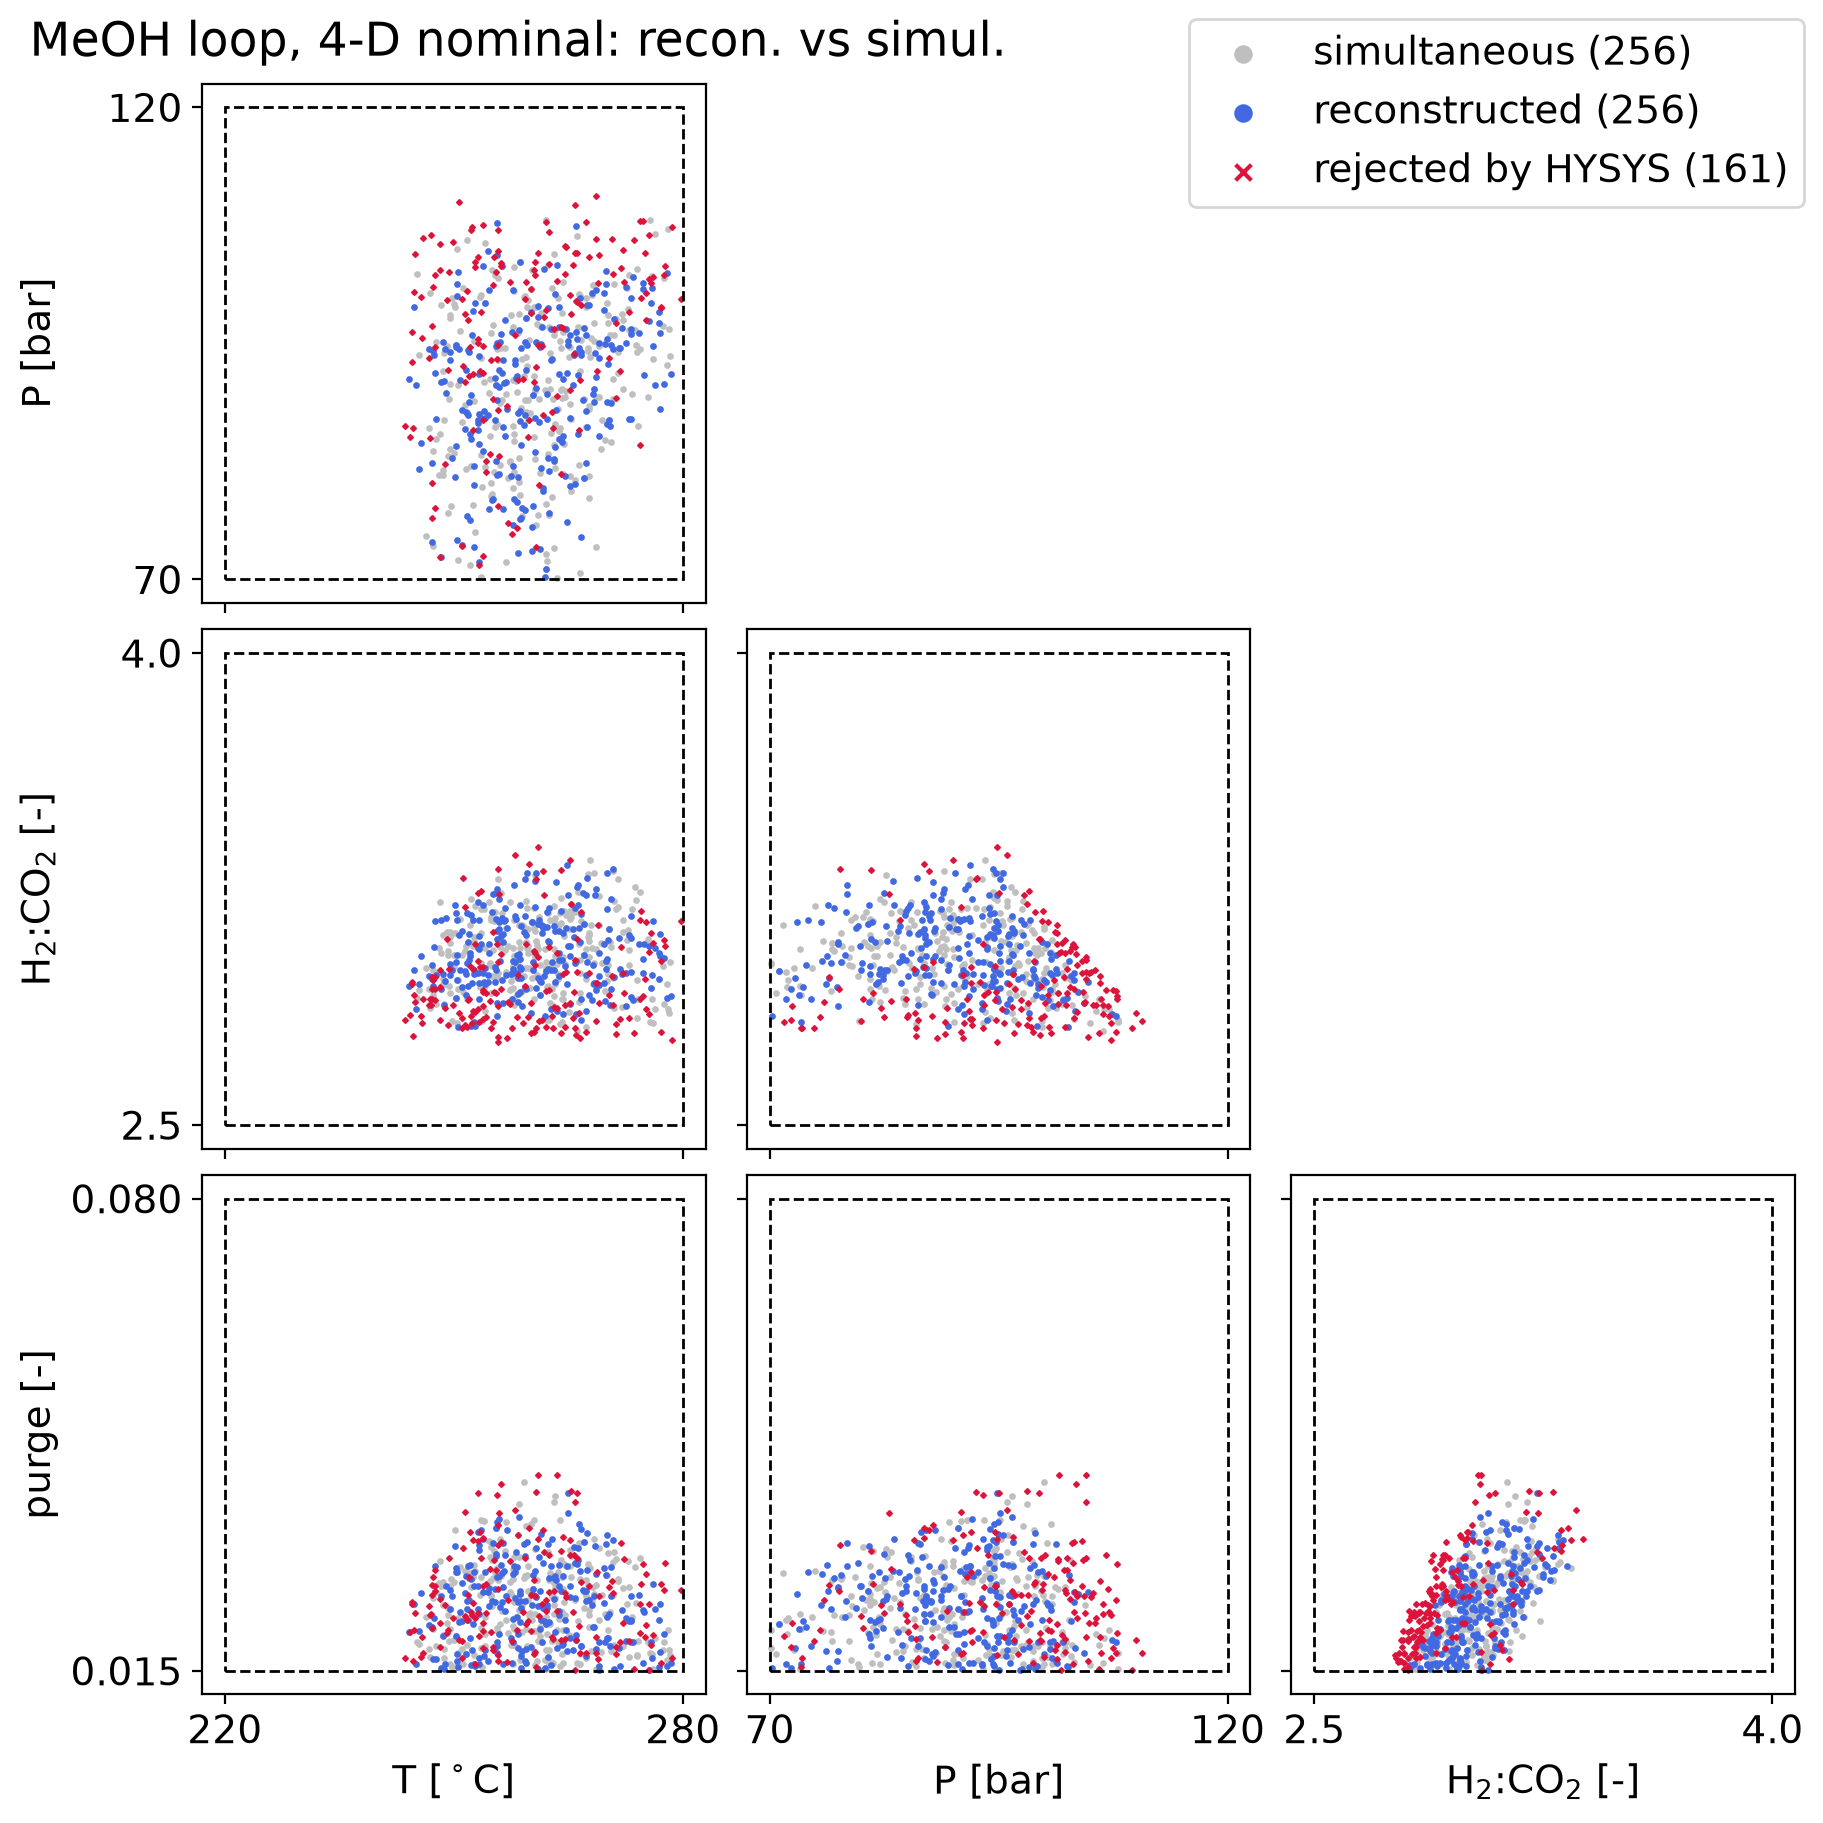

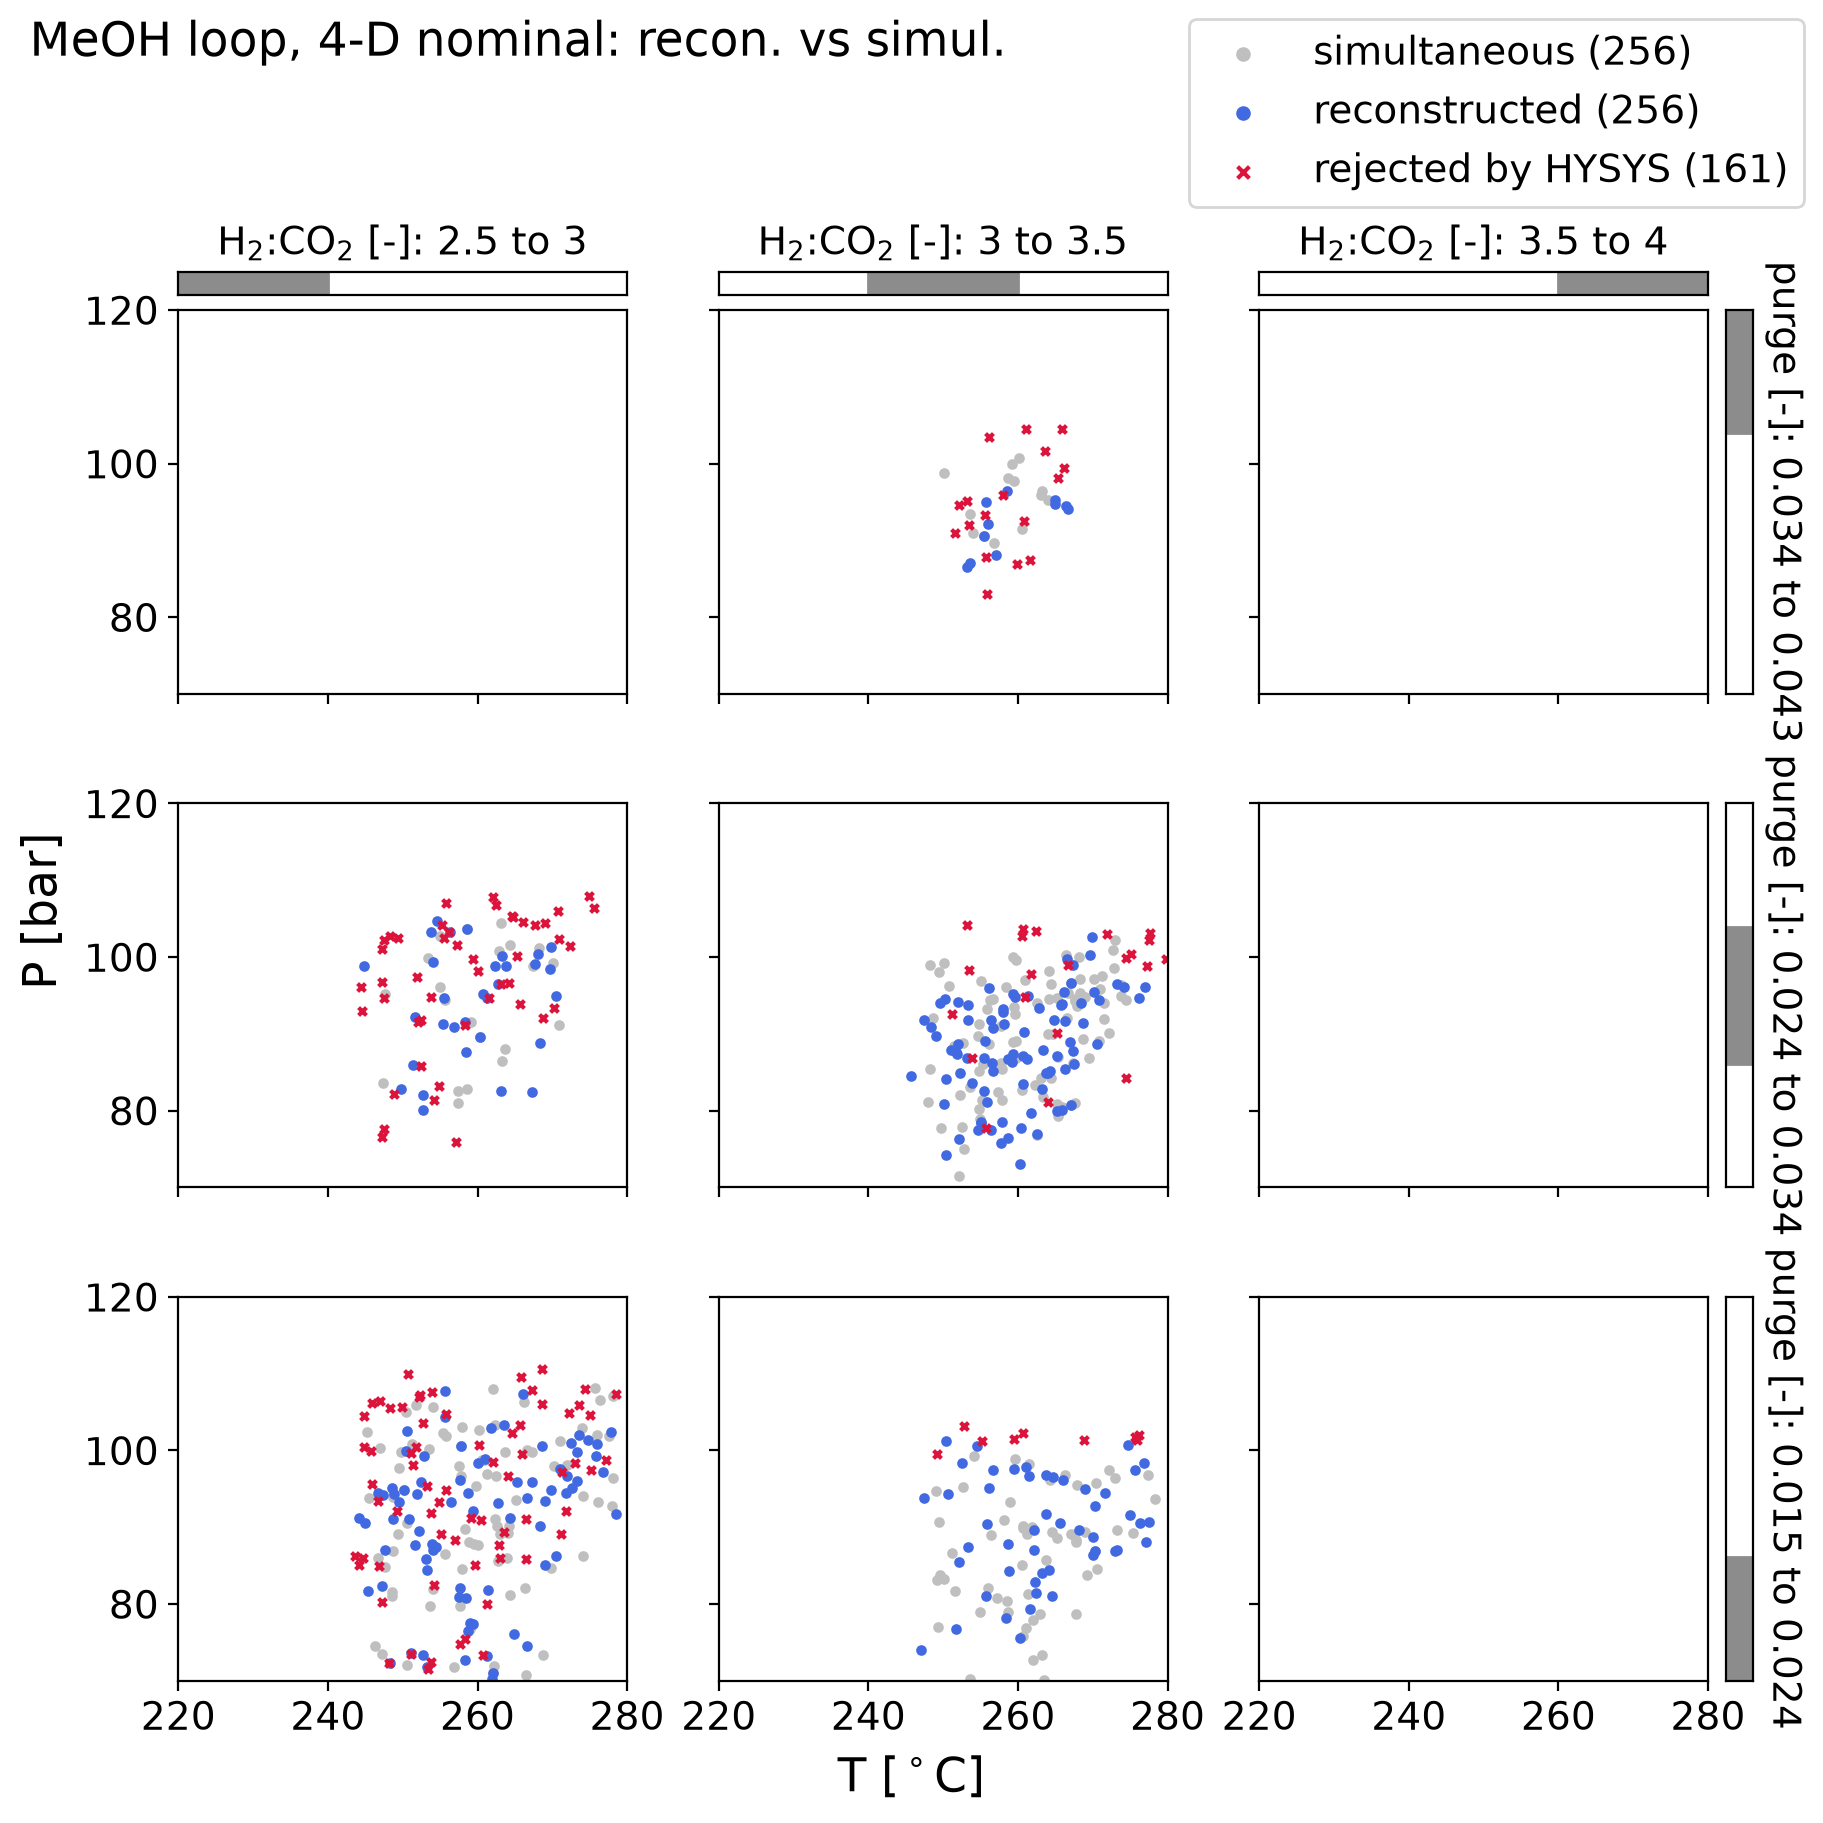

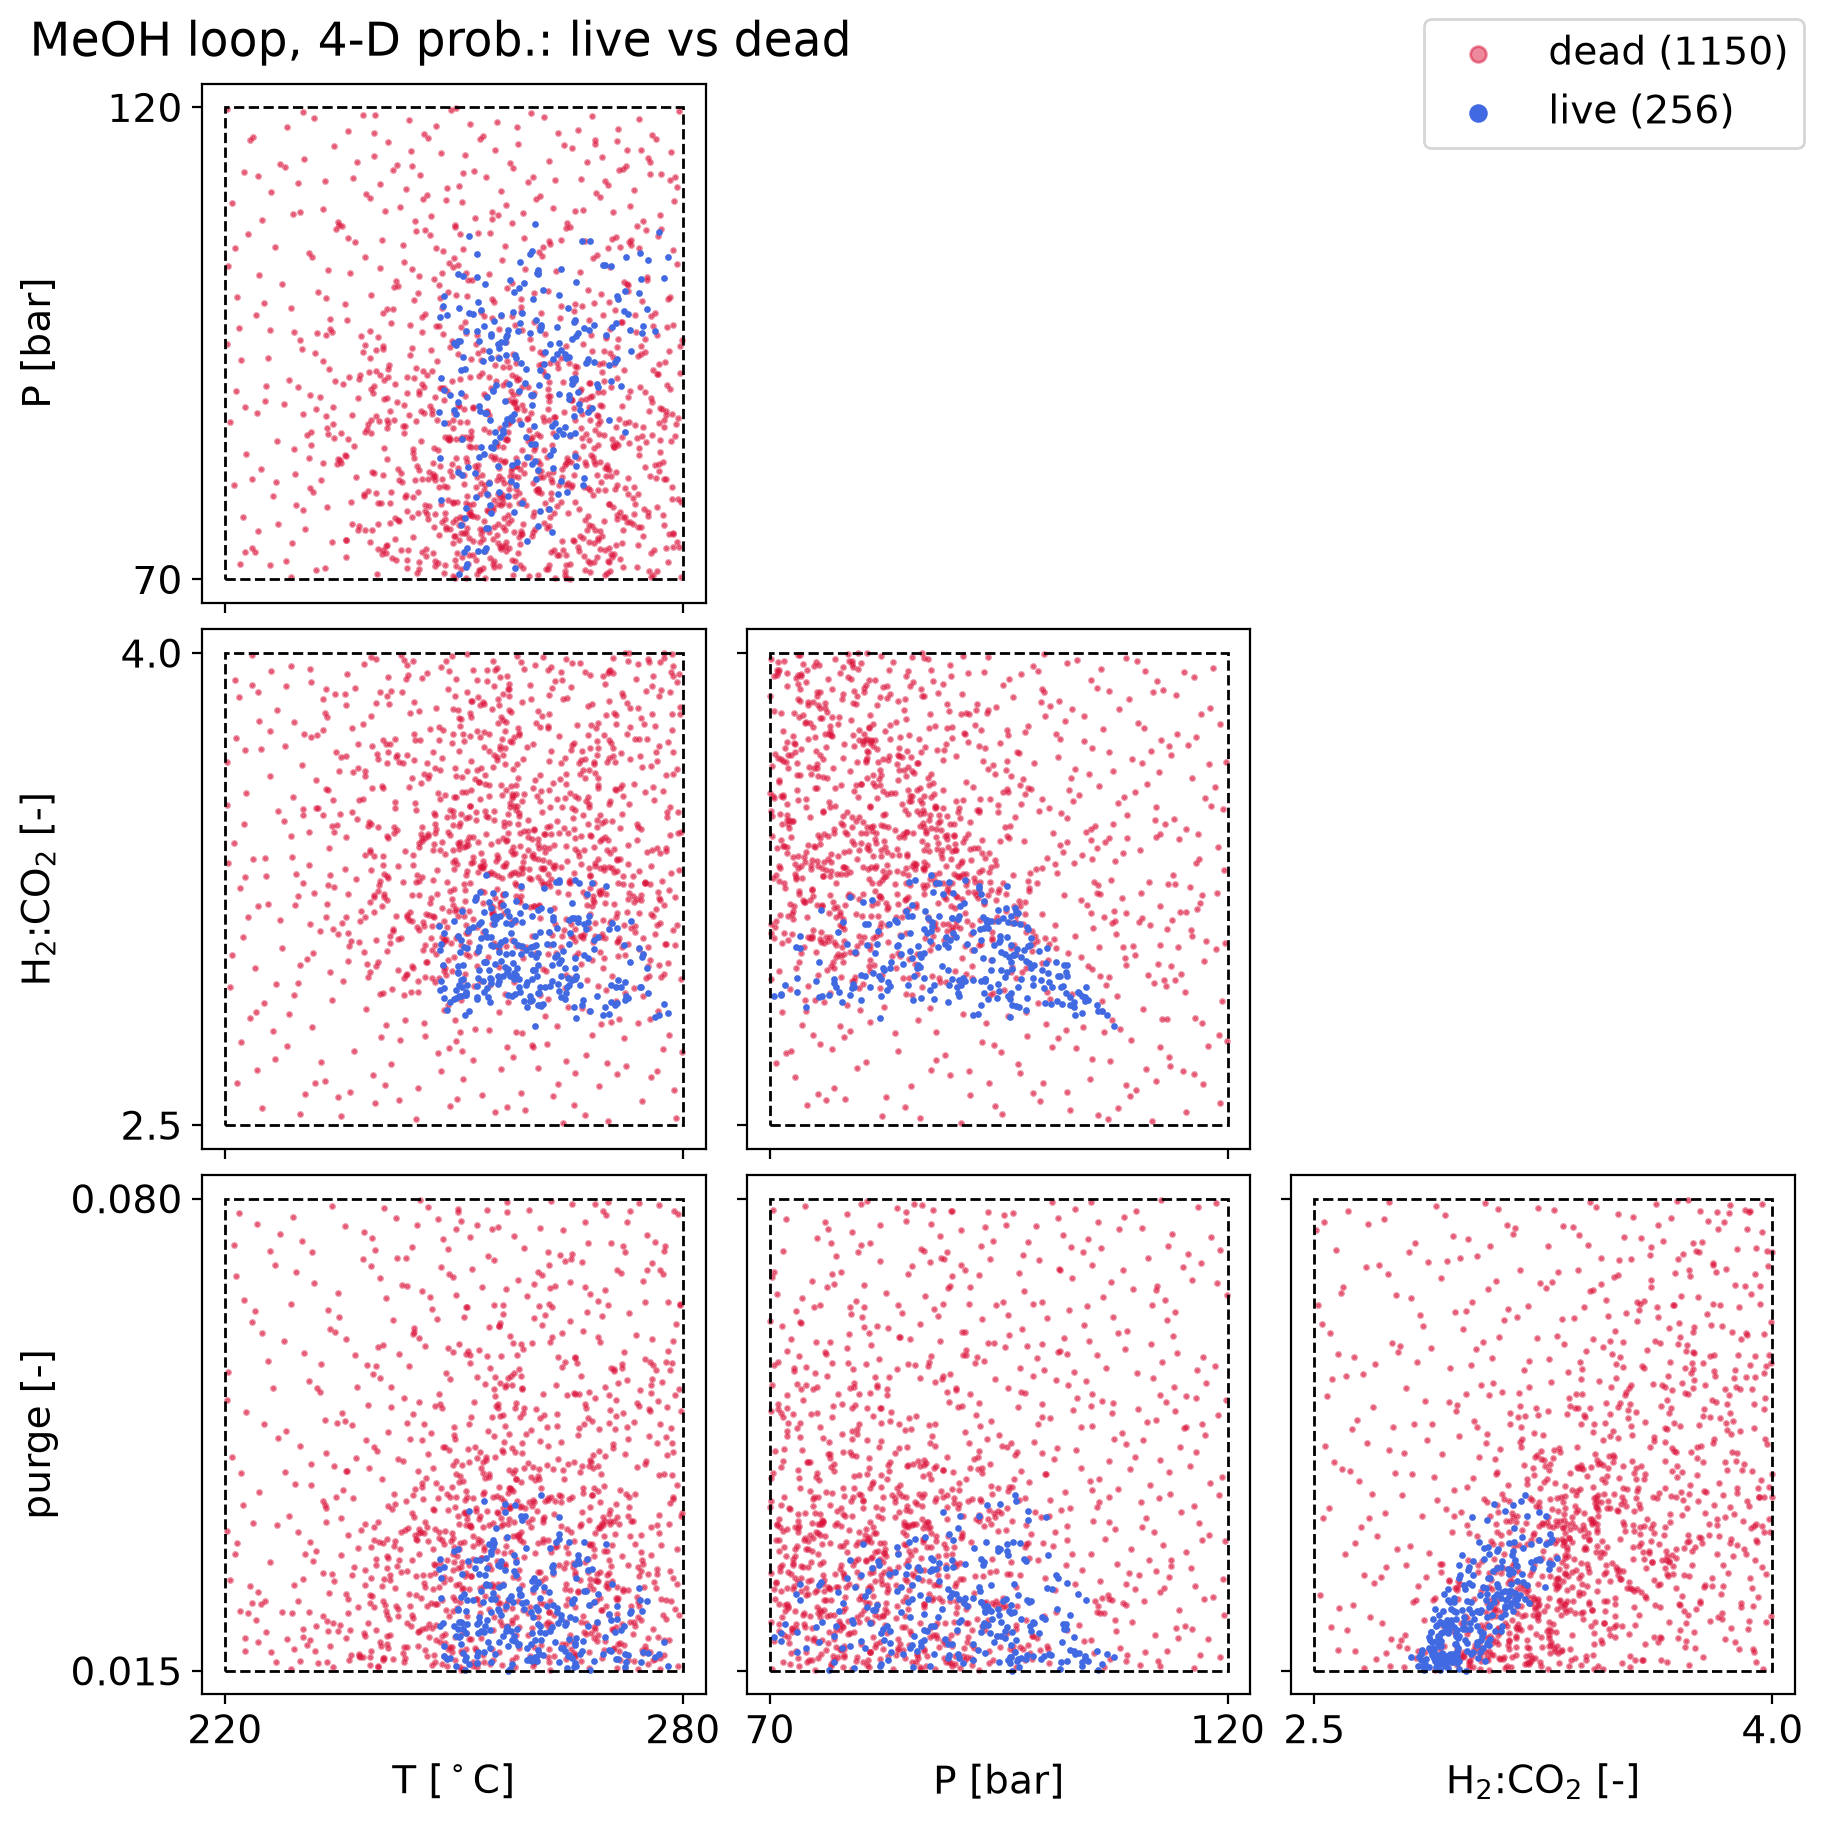

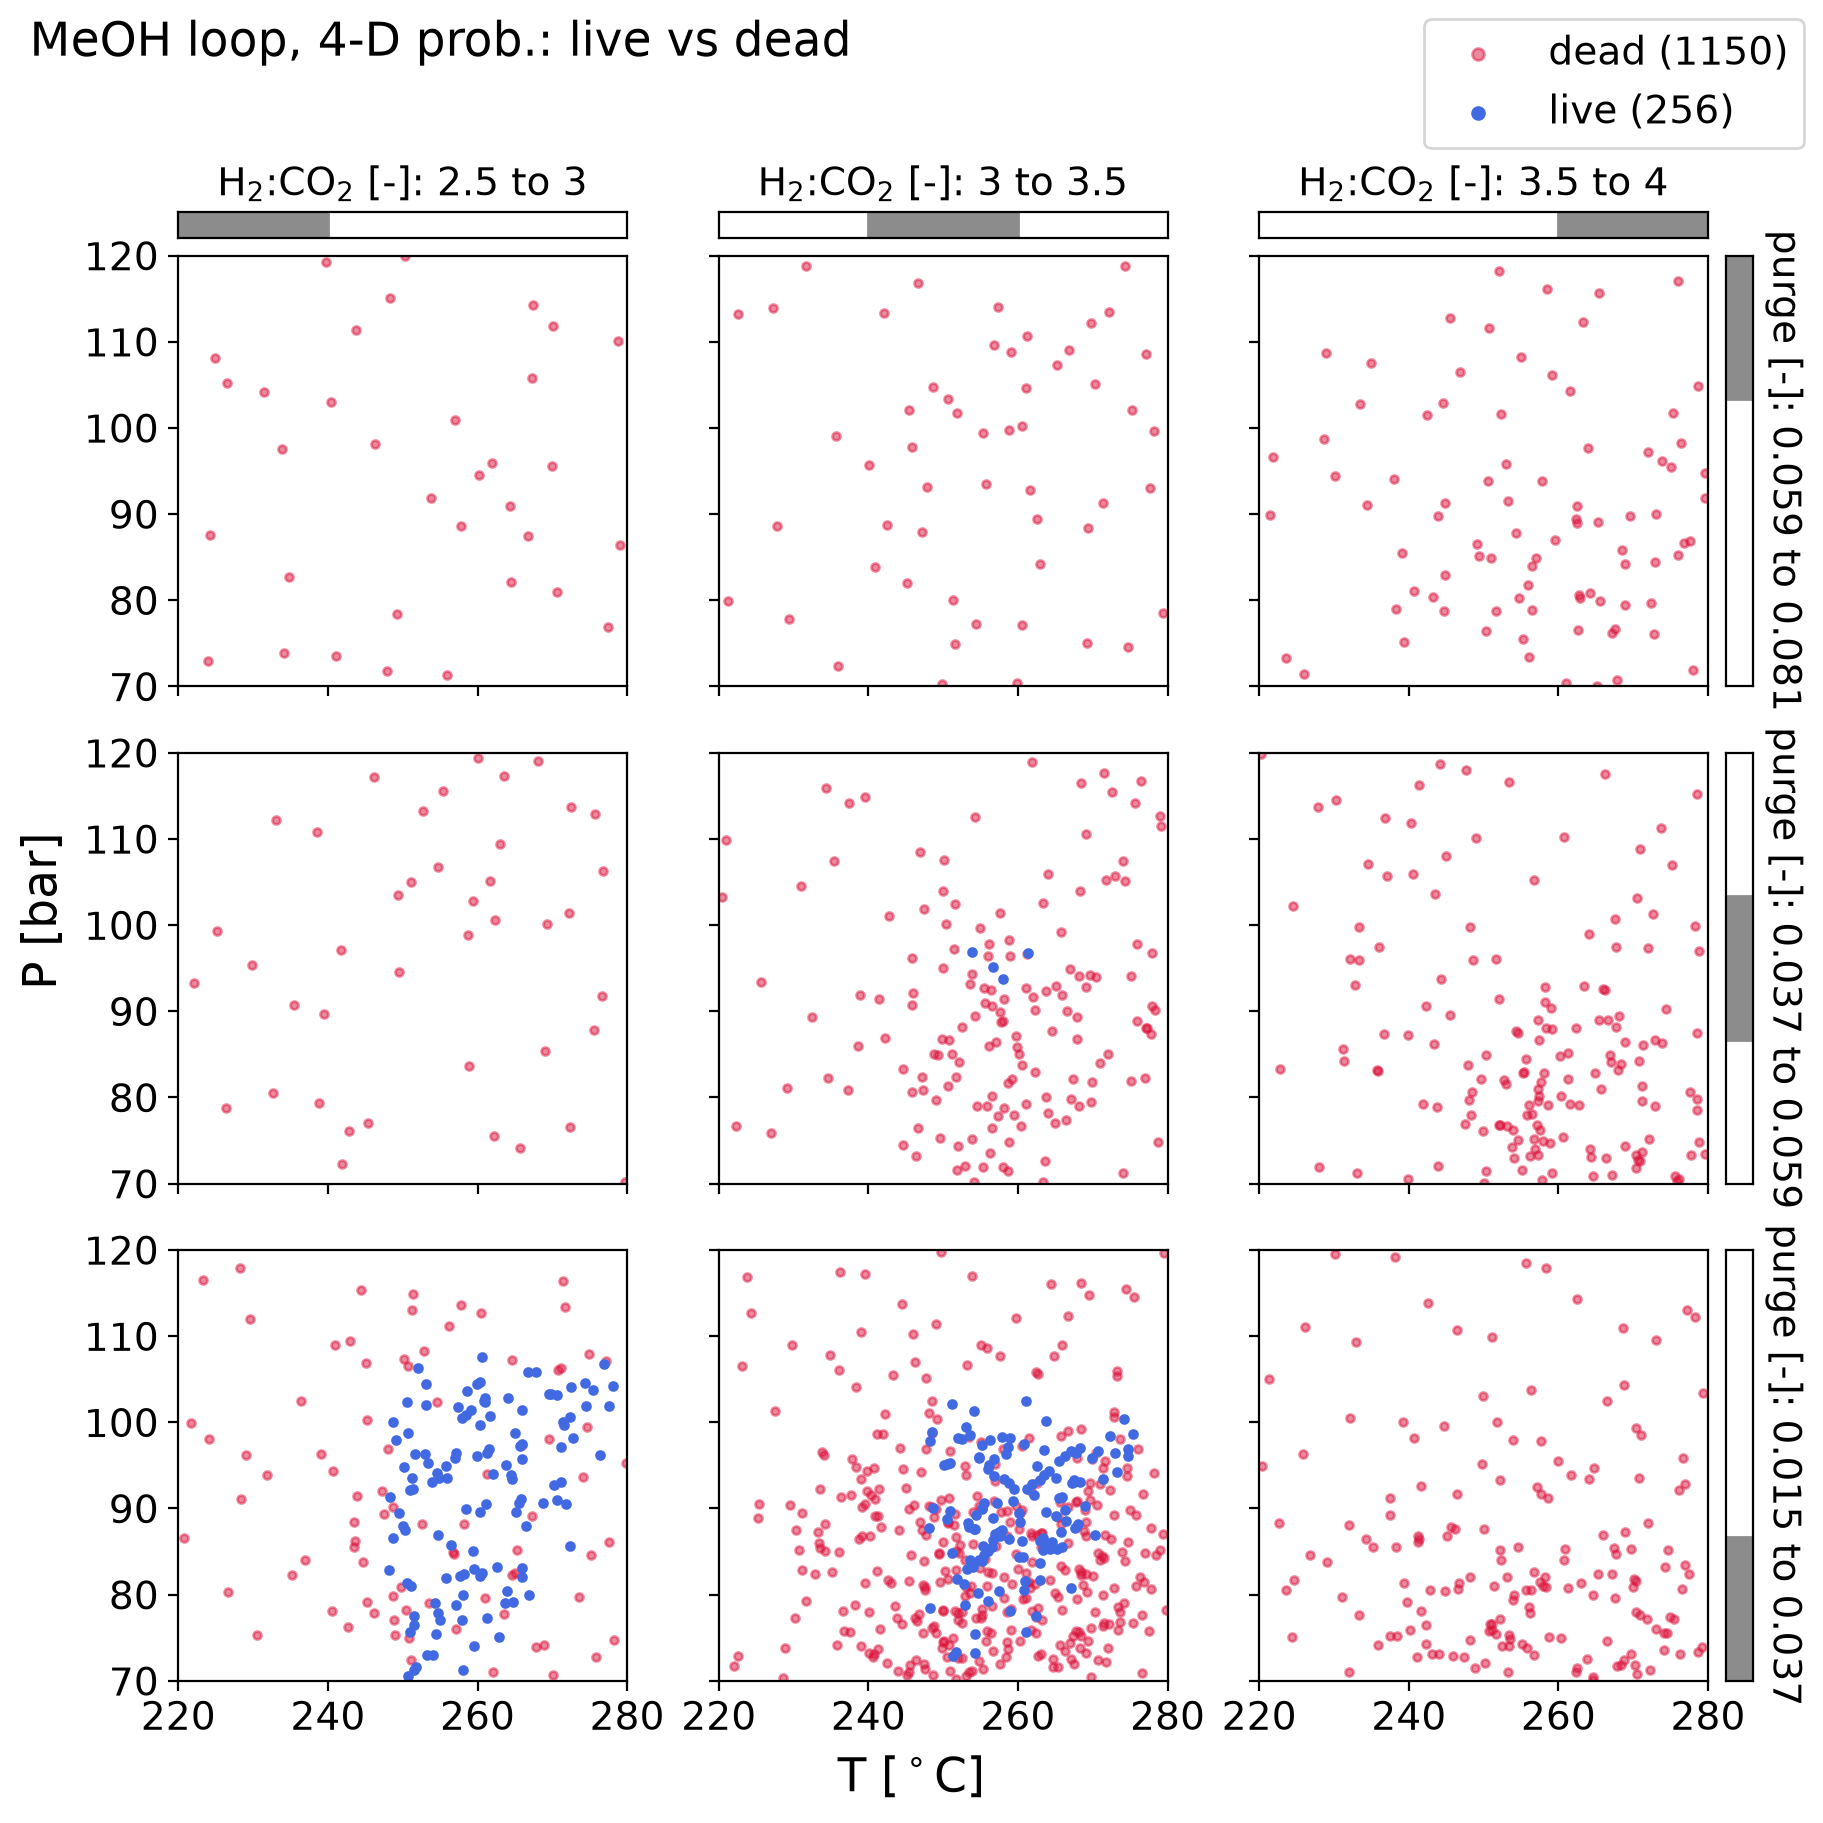

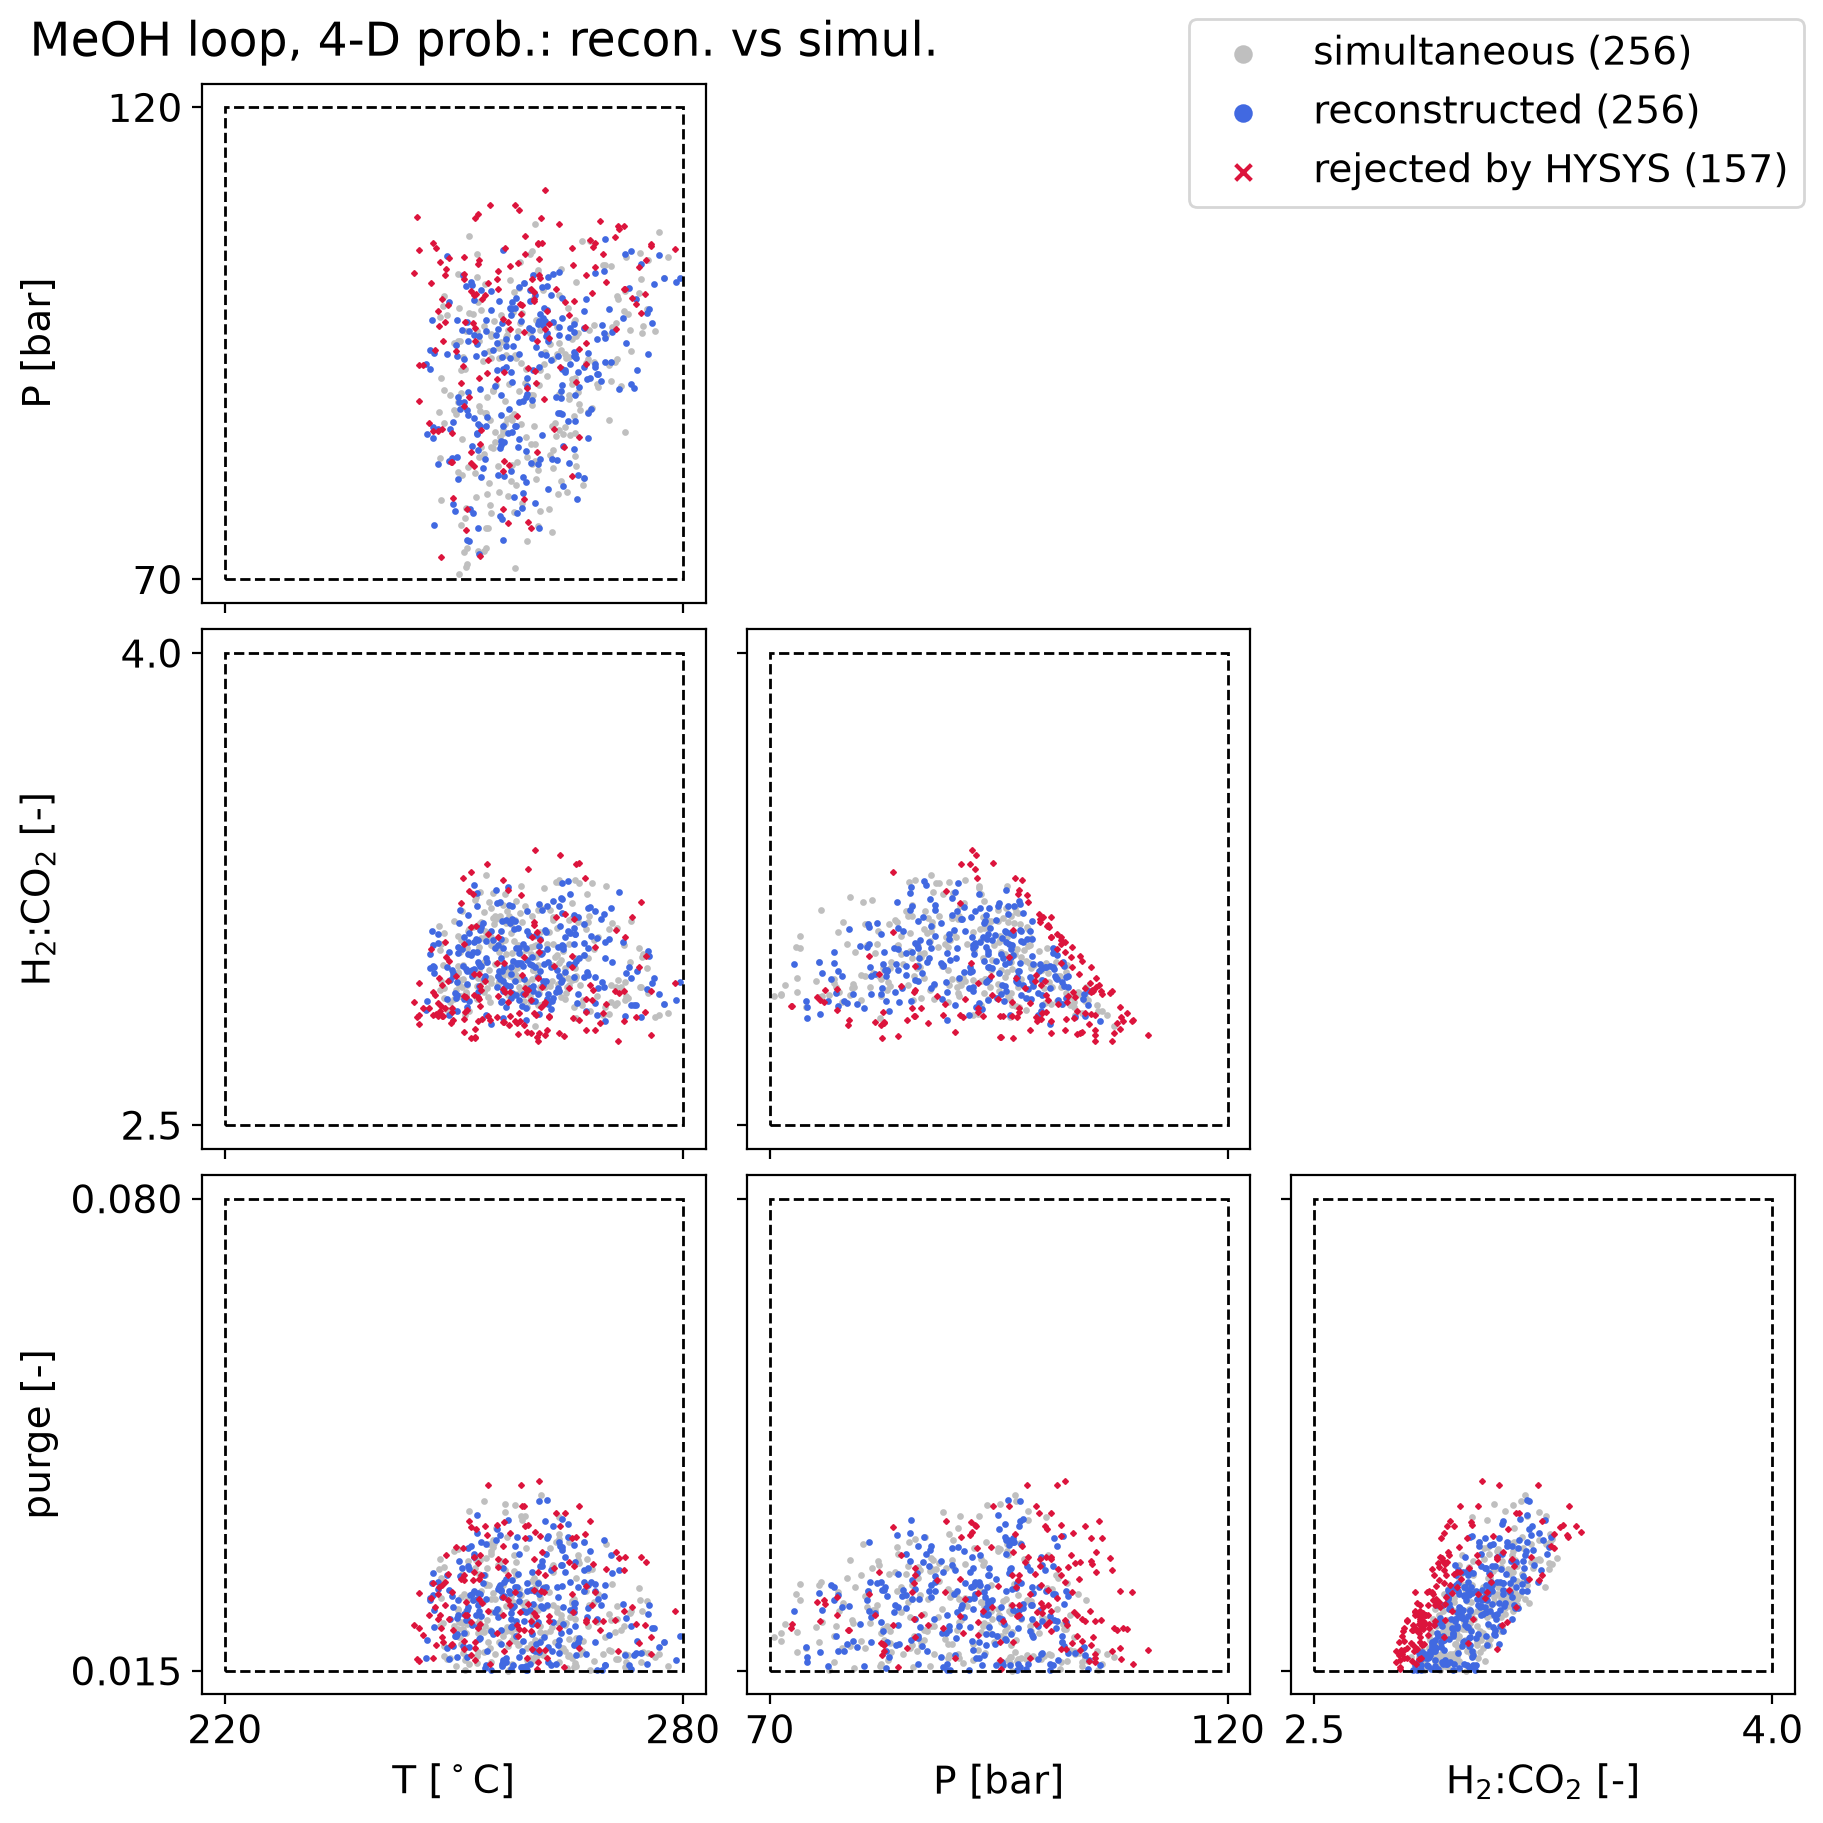

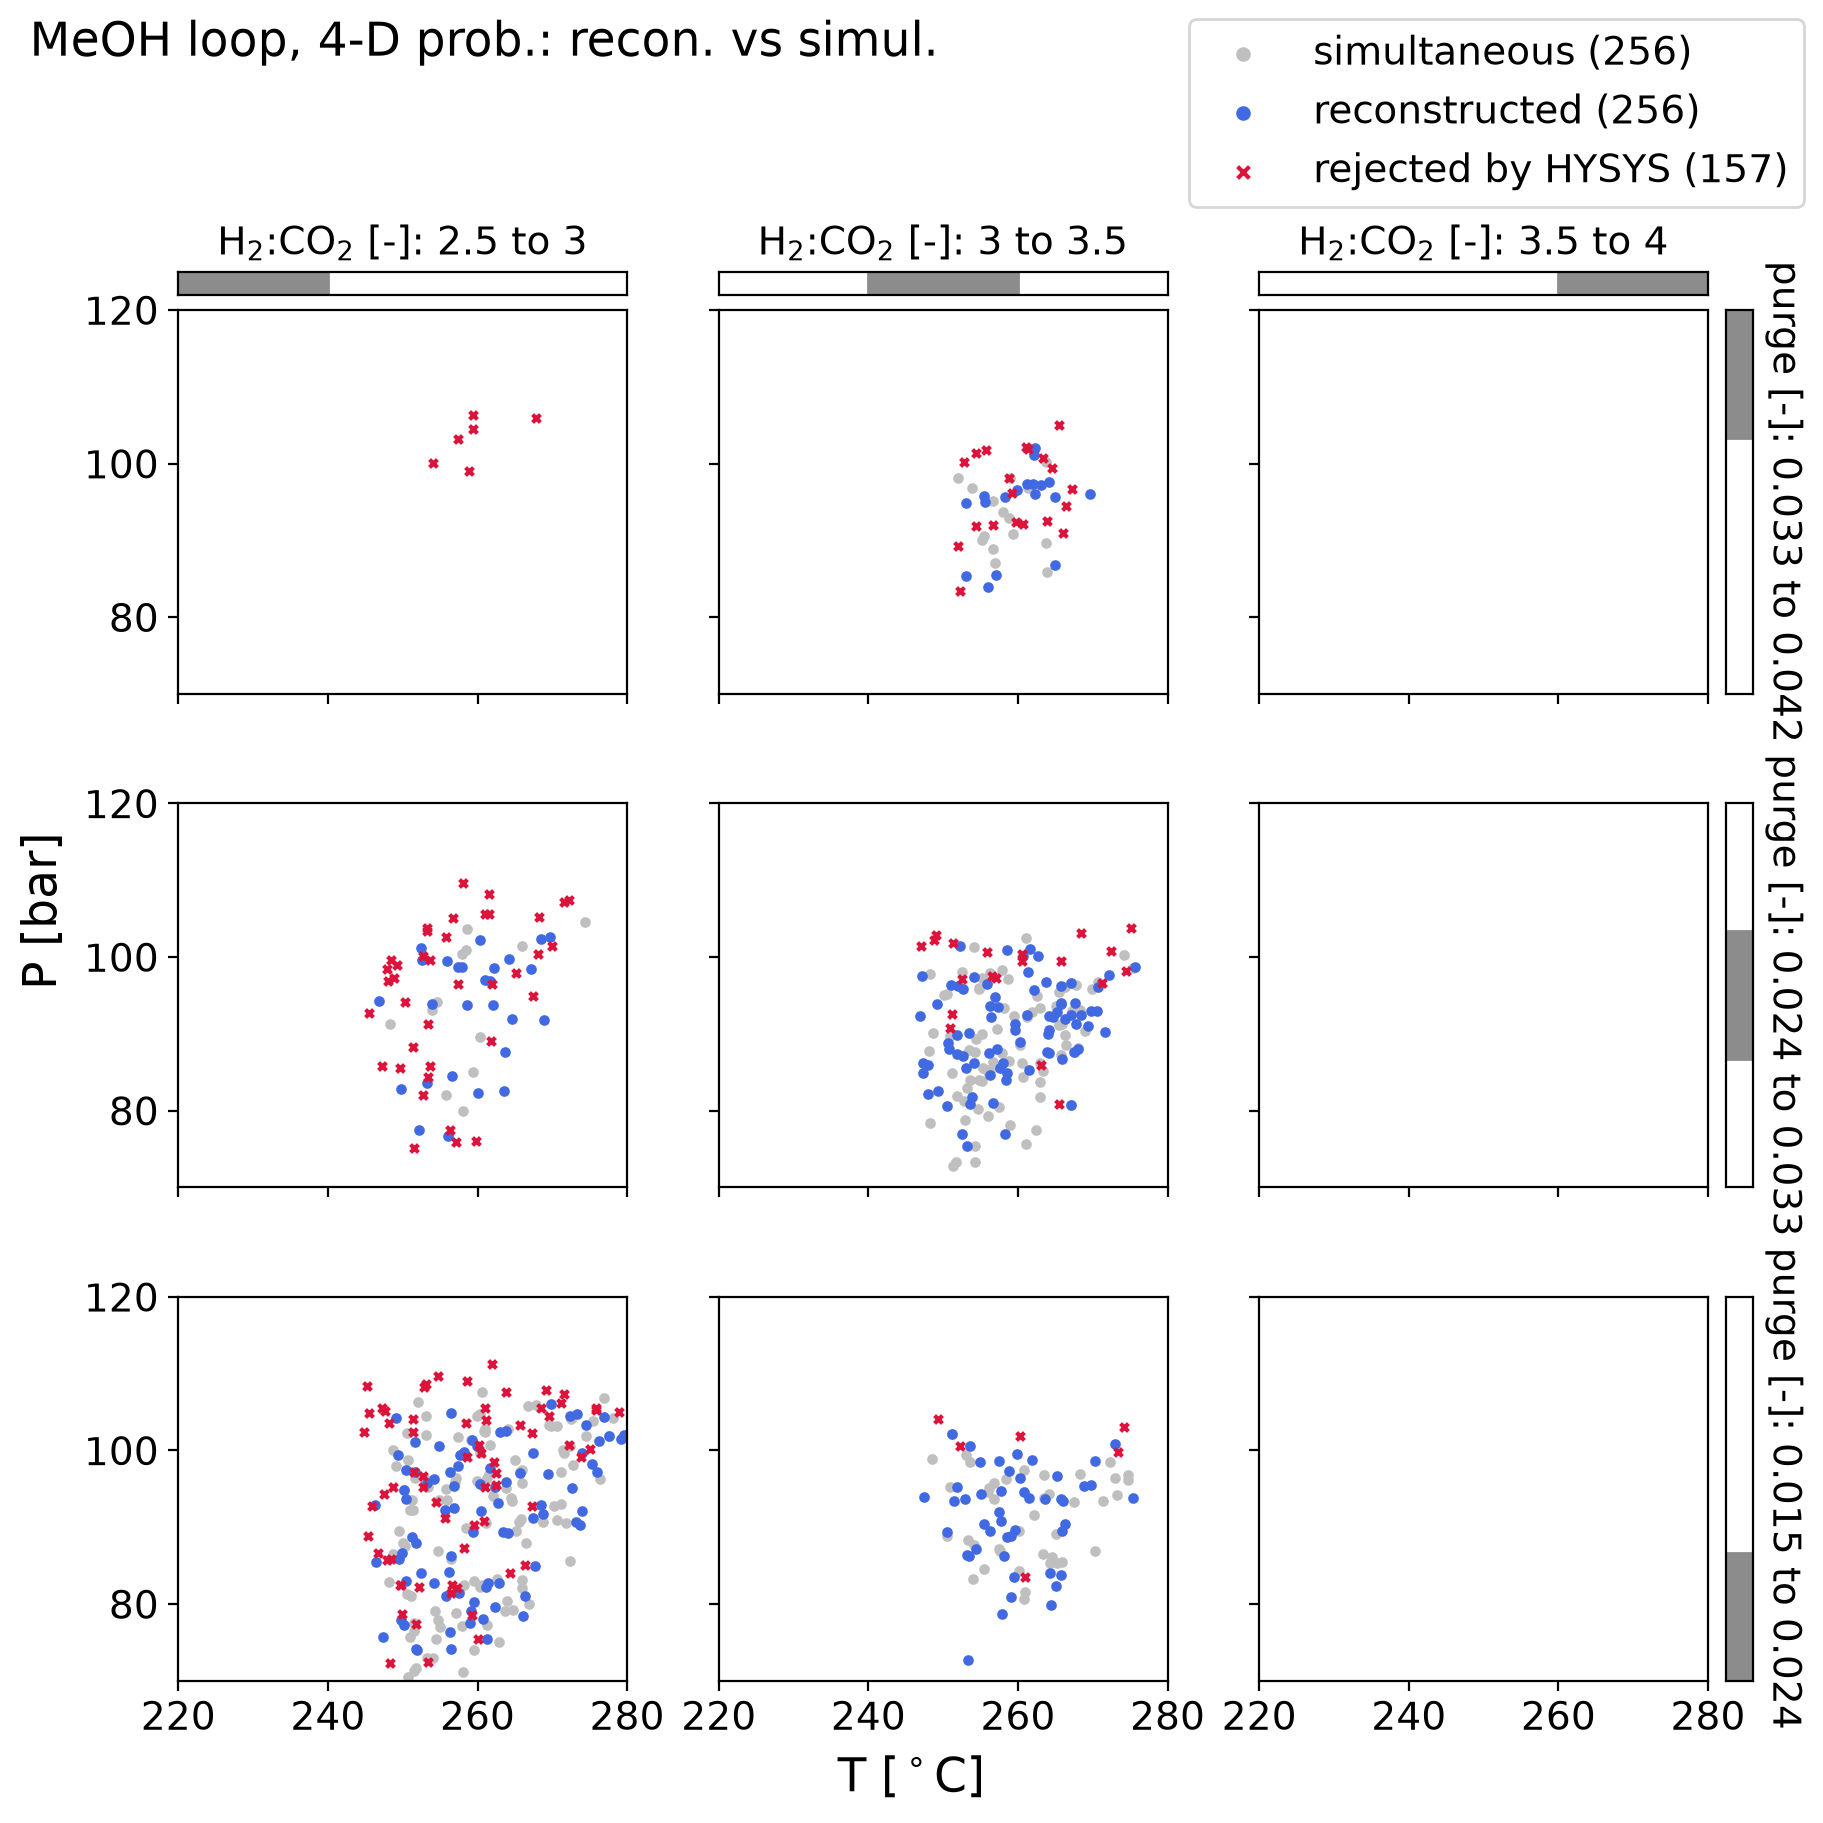

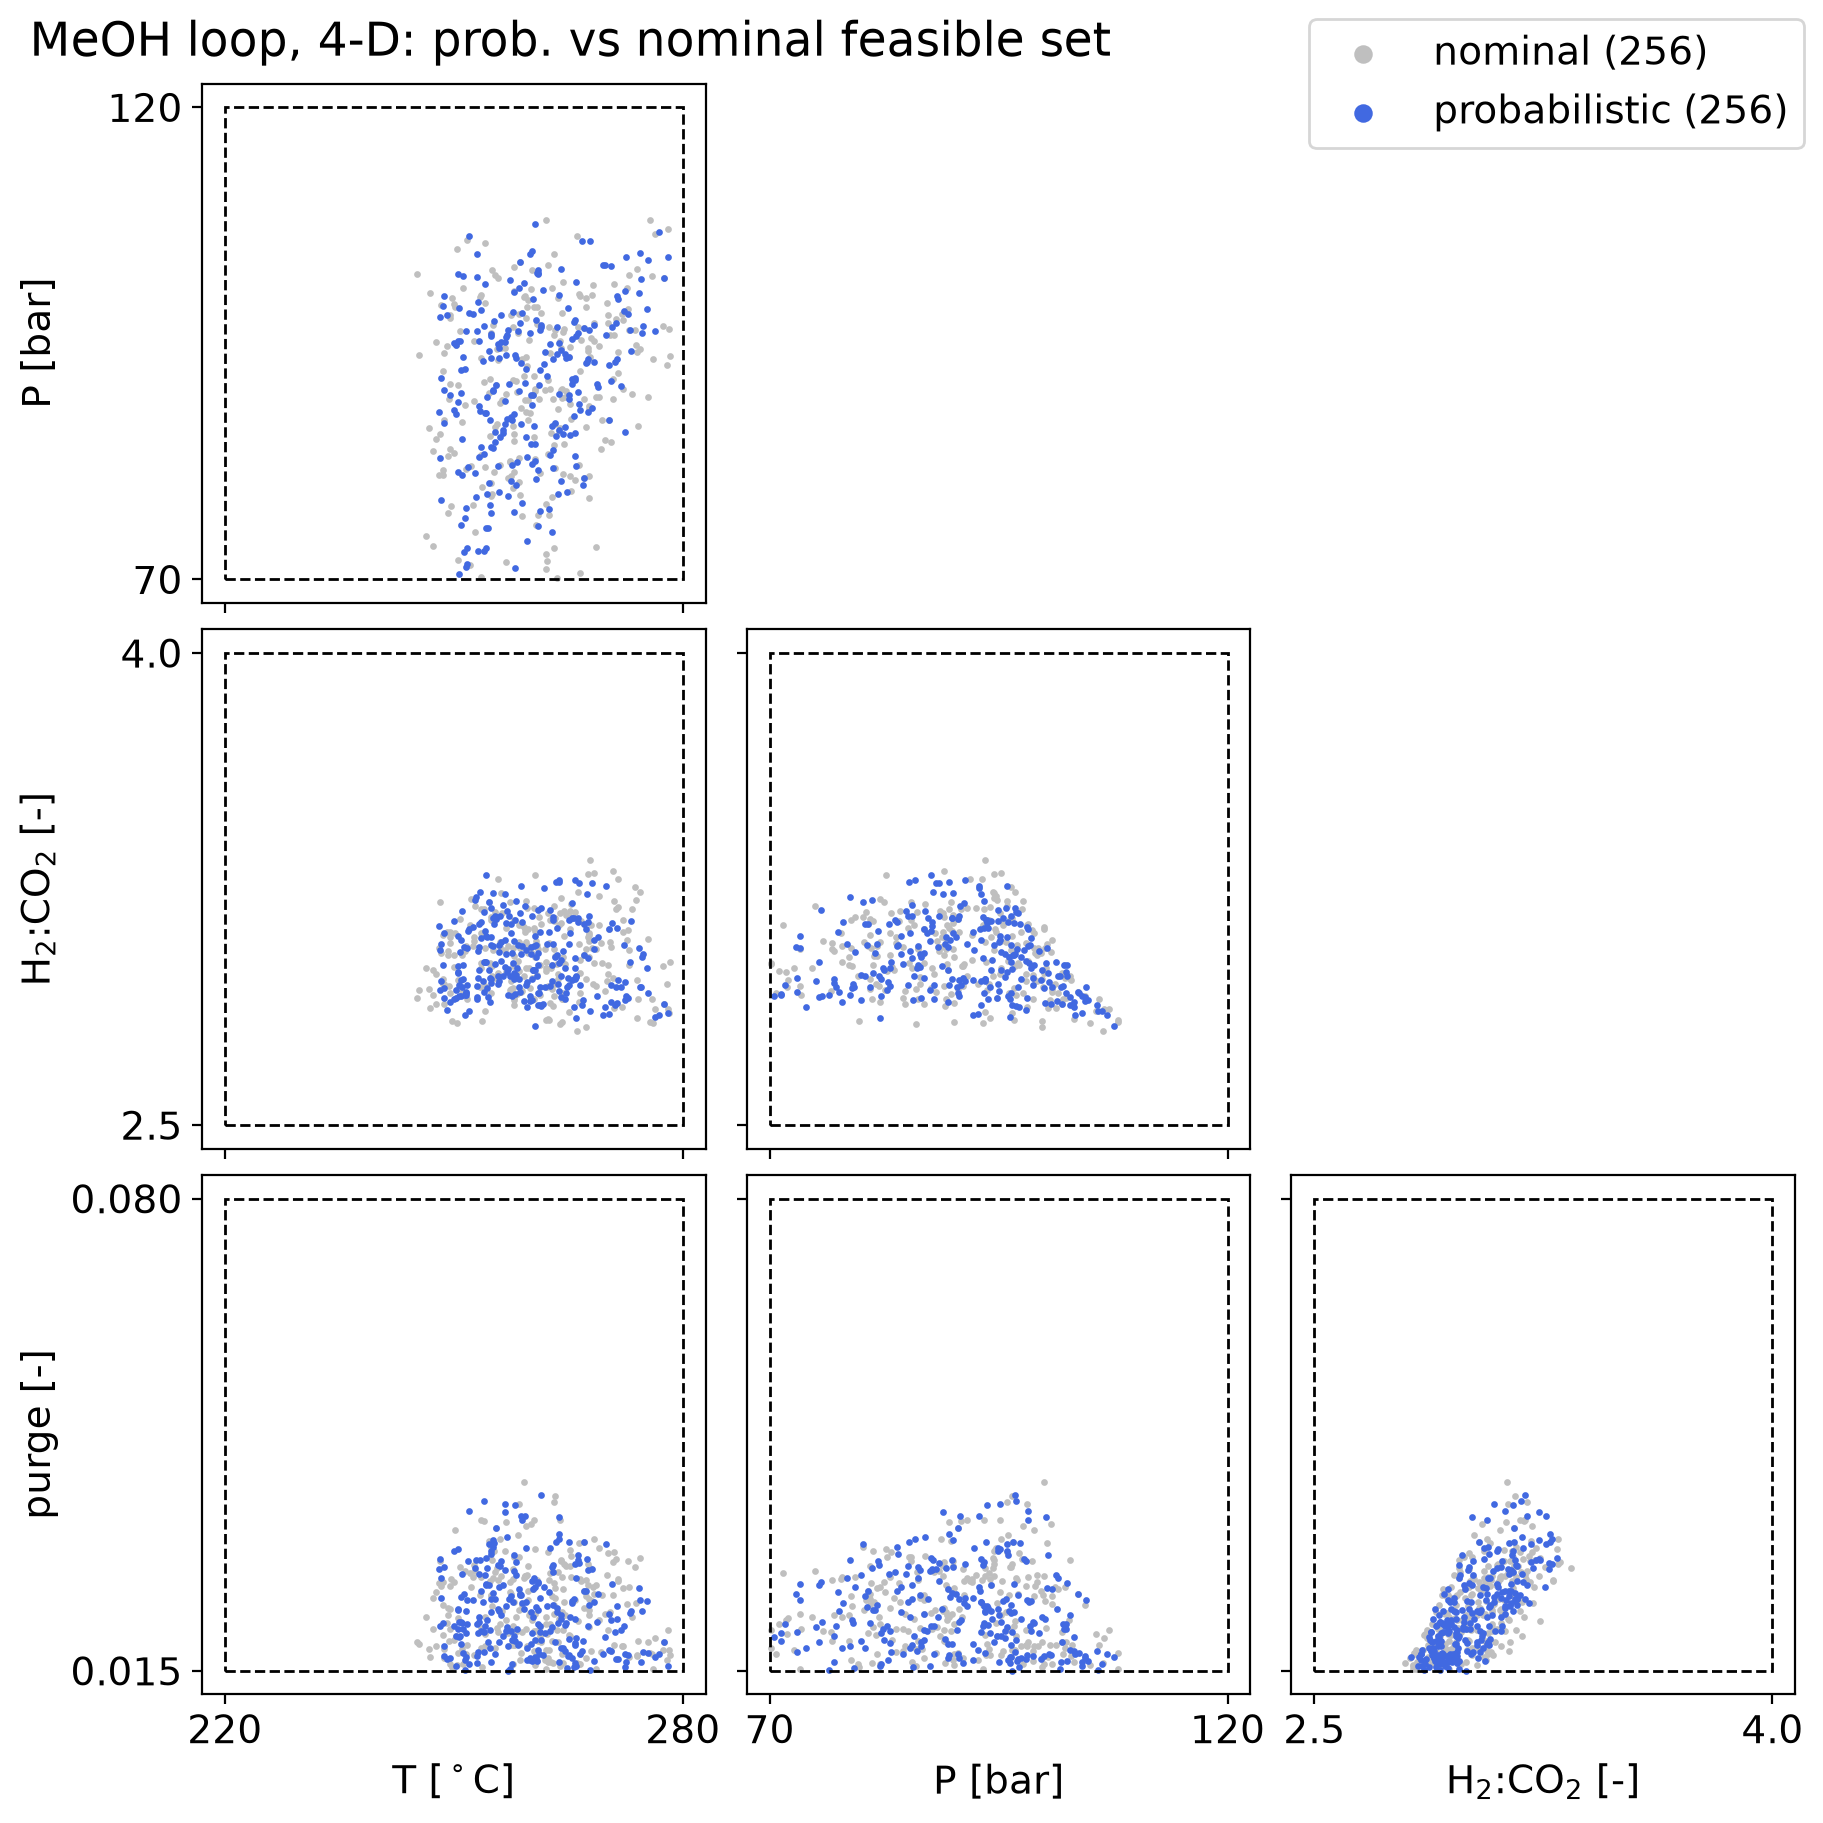

In [18]:
T, P, R, U = range(4)
BOX = list(zip(*DESIGN.values()))
TITLES = {"simultaneous": "live vs dead", "reconstructed": "recon. vs simul."}
RATIO_EDGES = np.linspace(*DESIGN["ratio"], 4)

def thesis_figures(out, name, title):
    """Corner and trellis as in the cascades; the trellis purge rows reach up to the largest point plotted, so nothing is dropped."""
    res, cand = out["hysys"]["result"], out["cand"]
    sets = {"simultaneous": [(res.dead.x, f"dead ({len(res.dead.x)})", dict(color="crimson", alpha=0.5)),
                             (res.live.x, f"live ({len(res.live.x)})", dict(color="royalblue"))],
            "reconstructed": [(res.live.x[res.live.feasible], f"simultaneous ({int(res.live.feasible.sum())})", dict(color="0.75")),
                              (cand.loc[cand.verified, list(DESIGN)].to_numpy(), f"reconstructed ({int(cand.verified.sum())})", dict(color="royalblue")),
                              (cand.loc[~cand.verified, list(DESIGN)].to_numpy(), f"rejected by HYSYS ({int((~cand.verified).sum())})", dict(color="crimson", marker="x"))]}
    for kind, pts in sets.items():
        purge_edges = np.linspace(DESIGN["purge_rate"][0], max(X[:, U].max() for X, _, _ in pts) + 1e-3, 4).round(3)
        grid = Corner(LABELS, BOX)
        for X, label, kw in pts:
            grid.scatter(X, s=2, label=label, **kw)
        grid.fig.legend(markerscale=4)
        grid.fig.suptitle(f"{title}: {TITLES[kind]}", x=0.01, ha="left")
        save(grid.fig, f"{FIG}/corner_{kind}_{name}{TAG}")
        grid = Trellis(RATIO_EDGES, purge_edges, xlabel=LABELS[T], ylabel=LABELS[P], col_label=LABELS[R], row_label=LABELS[U],
                       subplot_kw={"xlim": DESIGN["temperature_C"], "ylim": DESIGN["pressure_bar"]})
        for X, label, kw in pts:
            grid.scatter(X[:, T], X[:, P], X[:, R], X[:, U], s=8, label=label, **kw)
        grid.fig.legend(loc="outside upper right")
        grid.fig.suptitle(f"{title}: {TITLES[kind]}", x=0.01, ha="left")
        save(grid.fig, f"{FIG}/trellis_{kind}_{name}{TAG}")

for name, title in (("nominal", "MeOH loop, 4-D nominal"), ("probabilistic", "MeOH loop, 4-D prob.")):
    thesis_figures(runs[name], name, title)

grid = Corner(LABELS, BOX)
for name, color in (("nominal", "0.75"), ("probabilistic", "royalblue")):
    hys_live = runs[name]["hysys"]["result"].live
    grid.scatter(hys_live.x[hys_live.feasible], s=2, color=color, label=f"{name} ({int(hys_live.feasible.sum())})")
grid.fig.legend(markerscale=4)
grid.fig.suptitle("MeOH loop, 4-D: prob. vs nominal feasible set", x=0.01, ha="left")
save(grid.fig, f"{FIG}/corner_probabilistic_vs_nominal{TAG}")